# Riesgo Geopolítico y Volatilidad en los Mercados Financieros: Un Enfoque Basado en Machine Learning e Inteligencia Artificial
Octubre 2026

Máster Universitario en Big Data y Ciencia de Datos
2025 – 2026


Leonardo Jesus Villarreal Marcano

Notebook de investigación

# Inicialización

In [144]:
# %% Entorno -0- Comprobación e instalación de dependencias
# Solo instala un paquete si NO está disponible, y en ese caso fija la versión con la que se
# validó el flujo (cuando se conoce). Nunca actualiza un paquete ya instalado, para no alterar
# el entorno entre ejecuciones. Las versiones efectivas quedan registradas en la celda
# Reproducibilidad -2-. Entorno validado: Python 3.11.15 (entorno conda tfm).
import importlib, subprocess, sys
if sys.version_info[:2] != (3, 11):
    print(f"AVISO: el flujo se validó con Python 3.11 y este kernel usa {sys.version.split()[0]}")

DEPENDENCIAS = [                      # (nombre de importación, paquete de pip con la versión del entorno validado)
    ("numpy", "numpy==2.4.6"),
    ("pandas", "pandas==3.0.5"),
    ("scipy", "scipy==1.17.1"),
    ("sklearn", "scikit-learn==1.9.0"),
    ("joblib", "joblib==1.6.0"),
    ("threadpoolctl", "threadpoolctl==3.6.0"),
    ("shap", "shap==0.51.0"),
    ("arch", "arch==8.0.0"),
    ("statsmodels", "statsmodels==0.15.0"),
    ("xgboost", "xgboost==3.2.0"),
    ("matplotlib", "matplotlib==3.11.1"),
    ("seaborn", "seaborn==0.13.2"),
    ("pandas_market_calendars", "pandas_market_calendars==5.4.0"),
    ("dateutil", "python-dateutil==2.9.0.post0"),
    ("jinja2", "Jinja2==3.1.6"),
    ("pyarrow", "pyarrow==26.0.1"),
]

for modulo, paquete in DEPENDENCIAS:
    try:
        importlib.import_module(modulo)
    except ImportError:
        print(f"Instalando {paquete} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", paquete])
        importlib.invalidate_caches()
    finally:
        m = importlib.import_module(modulo)          # si aun así falla, el error detiene la ejecución aquí
        print(f"{modulo:24s} {getattr(m, '__version__', 'sin versión')}")

AVISO: el flujo se validó con Python 3.11 y este kernel usa 3.14.7
numpy                    2.5.3
pandas                   3.0.6
scipy                    1.18.1
sklearn                  1.9.1
joblib                   1.6.0
threadpoolctl            3.7.0
shap                     0.53.0
arch                     8.0.0
statsmodels              0.15.0
xgboost                  3.2.0
matplotlib               3.11.1
seaborn                  0.13.2
pandas_market_calendars  5.4.0
dateutil                 2.9.0.post0
jinja2                   3.1.6
pyarrow                  26.0.1


In [129]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow

from joblib import Parallel, delayed

REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW = REPO / "tfm-gpr-avol-ml" / "data" / "raw"
sys.path.insert(0, str(REPO / "data"))

import pandas_market_calendars as mcal
from pandas.tseries.holiday import USFederalHolidayCalendar
from datetime import timedelta
from dateutil.easter import easter

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
pd.set_option('display.expand_frame_repr', False) # Ver prints completos de datasets

SEED = 42
YEARS = range(1999, 2027)

import os
from datetime import datetime
Path("resultados").mkdir(exist_ok=True)
Path("figuras").mkdir(exist_ok=True)


# Data Cruda

In [3]:
# Calidad datos crudos -1-. Listar los archivos.
inventory = pd.DataFrame([
    {"file": p.name, "instrument": p.name.split("_")[0], "KB": round(p.stat().st_size / 1024, 1)}
    for p in sorted(RAW.iterdir()) if p.is_file()
])

print(REPO)
print(RAW)
print(inventory)

inventory.groupby("instrument")["file"].count().rename("n_files").to_frame()

C:\Users\EinKiGa\Desktop
C:\Users\EinKiGa\Desktop\tfm-gpr-avol-ml\data\raw
                                                                          file                         instrument         KB
0                            AI-GPR-index-eventtype_monthly_IacovielloTong.csv             AI-GPR-index-eventtype    59.5000
1                                        AI-GPR-index_daily_IacovielloTong.csv                       AI-GPR-index 1,981.0000
2                                      AI-GPR-index_monthly_IacovielloTong.csv                       AI-GPR-index    70.3000
3              Bitcoin_BTCUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv                            Bitcoin   137.1000
4              Bitcoin_BTCUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv                            Bitcoin   255.1000
5                 Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv                               Gold   291.7000
6                 Gold_XAUUSD_daily_20170101-20260

,n_files
instrument,
AI-GPR-index,2
AI-GPR-index-eventtype,1
Bitcoin,2
Gold,2
Oil-Brent,2
Oil-WTI,2
SP500,2
UnitedStates10YearBondYield-US10Y,2


In [4]:
# Calidad datos crudos -2-. Cargar los archivos.
INTEREST = {
    # series financieras
    "sp500":         "SP500_daily_",
    "oil_wti":       "Oil-WTI_CL_",
    "oil_brent":     "Oil-Brent_LCO_",
    "gold_xauusd":   "Gold_XAUUSD_",
    "us10y":         "UnitedStates10YearBondYield-US10Y_",
    "btc":           "Bitcoin_BTCUSD_",
    # variables
    "gpr_daily":     "AI-GPR-index_daily_",
    "gpr_eventtype": "AI-GPR-index-eventtype_monthly_",
}

ASSET_KEYS = ["sp500", "oil_wti", "oil_brent", "gold_xauusd", "us10y", "btc"]

raw = {}
for key, prefix in INTEREST.items():
    for p in sorted(RAW.glob(prefix + "*")):
        reader = pd.read_excel if p.suffix == ".xlsx" else pd.read_csv
        raw[(key, p.name)] = reader(p, dtype=str)

pd.DataFrame([
    {"key": k, "file": f, "shape": df.shape, "columns": list(df.columns)}
    for (k, f), df in raw.items()
])

,key,file,shape,columns
0,sp500,SP500_daily_19990101-20161231_OHCLVCh_investingcom.csv,"(4529, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
1,sp500,SP500_daily_20170101-20260910_OHCLVCh_investingcom.csv,"(2435, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
2,oil_wti,Oil-WTI_CL_daily_19990101-20161231_OHCLVCh_investingcom.csv,"(4554, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
3,oil_wti,Oil-WTI_CL_daily_20170101-20260910_OHCLVCh_investingcom.csv,"(2546, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
4,oil_brent,Oil-Brent_LCO_daily_19990101-20161231_OHCLVCh_investingcom.csv,"(4608, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
5,oil_brent,Oil-Brent_LCO_daily_20170101-20260910_OHCLVCh_investingcom.csv,"(2503, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
6,gold_xauusd,Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,"(4687, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
7,gold_xauusd,Gold_XAUUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,"(2521, 7)","[Date, Price, Open, High, Low, Vol., Change %]"
8,us10y,UnitedStates10YearBondYield-US10Y_daily_19910101-20161231_investingcom.csv,"(4622, 6)","[Date, Price, Open, High, Low, Change %]"
9,us10y,UnitedStates10YearBondYield-US10Y_daily_20170101-20260910_investingcom.csv,"(2516, 6)","[Date, Price, Open, High, Low, Change %]"


In [5]:
# Calidad datos crudos -3-. info(), head(), describe() por archivo
for (key, fname), df in raw.items():
    print(f"\n{'=' * 100}\n{key}  - {fname}\n{'=' * 100}")
    df.info()
    display(df.head())
    display(df.describe())


sp500  - SP500_daily_19990101-20161231_OHCLVCh_investingcom.csv
<class 'pandas.DataFrame'>
RangeIndex: 4529 entries, 0 to 4528
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      4529 non-null   str  
 1   Price     4529 non-null   str  
 2   Open      4529 non-null   str  
 3   High      4529 non-null   str  
 4   Low       4529 non-null   str  
 5   Vol.      0 non-null      str  
 6   Change %  4529 non-null   str  
dtypes: str(7)
memory usage: 247.8 KB


,Date,Price,Open,High,Low,Vol.,Change %
0,12/30/2016,"2,238.80","2,251.60","2,253.60","2,233.60",NaN,-0.47%
1,12/29/2016,"2,249.30","2,249.50","2,254.50","2,244.60",NaN,-0.03%
2,12/28/2016,"2,249.90","2,270.20","2,271.30","2,249.10",NaN,-0.84%
3,12/27/2016,"2,268.90","2,266.20","2,273.80","2,266.20",NaN,0.23%
4,12/23/2016,"2,263.80","2,260.20","2,263.80","2,258.80",NaN,0.12%


,Date,Price,Open,High,Low,Vol.,Change %
count,4529,4529,4529,4529,4529,0,4529
unique,4529,3604,3608,3577,3582,0,648
top,12/30/2016,"1,409.30","1,418.10","1,074.80","1,191.50",NaN,0.23%
freq,1,5,5,6,6,NaN,32



sp500  - SP500_daily_20170101-20260910_OHCLVCh_investingcom.csv
<class 'pandas.DataFrame'>
RangeIndex: 2435 entries, 0 to 2434
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      2435 non-null   str  
 1   Price     2435 non-null   str  
 2   Open      2435 non-null   str  
 3   High      2435 non-null   str  
 4   Low       2435 non-null   str  
 5   Vol.      0 non-null      str  
 6   Change %  2435 non-null   str  
dtypes: str(7)
memory usage: 133.3 KB


,Date,Price,Open,High,Low,Vol.,Change %
0,09/10/2026,"7,591.70","7,594.74","7,612.86","7,580.06",NaN,-0.58%
1,09/09/2026,"7,636.36","7,660.68","7,660.68","7,624.16",NaN,-0.48%
2,09/08/2026,"7,673.52","7,717.81","7,717.81","7,666.99",NaN,-0.58%
3,09/04/2026,"7,718.60","7,750.19","7,750.19","7,706.12",NaN,-0.38%
4,09/03/2026,"7,747.71","7,686.71","7,756.76","7,686.71",NaN,1.06%


,Date,Price,Open,High,Low,Vol.,Change %
count,2435,2435,2435,2435,2435,0,2435
unique,2435,2387,2369,2372,2380,0,499
top,09/10/2026,"2,723.10","2,910.00","4,511.99","2,393.90",NaN,0.03%
freq,1,3,3,2,3,NaN,24


... (32 outputs left out)

,Date,GPR_AI,GPR_AER,GPR_OIL,GPR_NONOIL,THREATS_GPR_AI,ACTS_GPR_AI,GPR_OIL_MiddleEast,GPR_OIL_Russia,GPR_OIL_USA,GPR_OIL_Venezuela,GPR_OIL_Africa,GPR_OIL_Americas,GPR_OIL_Asia,GPR_OIL_NorthSea
count,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350,24350
unique,24350,11140,6200,4089,11178,10756,10749,3169,1419,905,593,1388,843,1206,107
top,1960-01-01,118.65,115.27,0.0,126.4,121.14,119.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
freq,1,90,67,8126,96,82,89,12968,20497,22298,23328,19845,22465,21110,24226



gpr_eventtype  - AI-GPR-index-eventtype_monthly_IacovielloTong.csv
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Date                800 non-null    str  
 1   GPR_AI              800 non-null    str  
 2   military_conflict   800 non-null    str  
 3   diplomatic_tension  800 non-null    str  
 4   terrorism           800 non-null    str  
 5   civil_war           800 non-null    str  
 6   nuclear_threat      800 non-null    str  
 7   coup                800 non-null    str  
 8   sanctions           800 non-null    str  
 9   other               800 non-null    str  
dtypes: str(10)
memory usage: 62.6 KB


,Date,GPR_AI,military_conflict,diplomatic_tension,terrorism,civil_war,nuclear_threat,coup,sanctions,other
0,1960-01-01,116.35,13.1034,56.0133,5.5232,13.6367,15.9603,2.3236,0.4952,9.2943
1,1960-02-01,129.76,19.2458,62.4717,4.7343,9.4274,24.7417,1.1527,0.5352,7.4513
2,1960-03-01,112.5,10.0798,69.241,4.2763,6.4908,14.1269,0.84,0.3436,7.1016
3,1960-04-01,120.21,9.4762,70.6893,5.6934,15.2842,10.7371,1.9869,0.4203,5.9226
4,1960-05-01,153.26,13.4553,112.4268,2.934,6.3913,10.1663,2.8779,0.3738,4.6346


,Date,GPR_AI,military_conflict,diplomatic_tension,terrorism,civil_war,nuclear_threat,coup,sanctions,other
count,800,800,800,800,800,800,800,800,800,800
unique,800,770,800,800,797,798,797,789,794,796
top,1960-01-01,120.21,13.1034,56.0133,4.5375,6.3011,2.3818,0.0,0.3931,7.7596
freq,1,2,1,1,2,2,2,5,2,2


## Transformacion de tipo de datos

Se revisa la trasnformacion de datos y los posibles errores por derivacion de vacios/nulos/asuentes

In [6]:
# Calidad datos crudos -4-. Conversión explícita de datos (texto -> fecha/numero)
def parse_money(raw: pd.Series) -> pd.Series:
    s = raw.astype(str).str.strip().str.strip('"').str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

SUFFIX_MULT = {"K": 1e3, "M": 1e6, "B": 1e9}

def parse_volume(raw: pd.Series) -> pd.Series:
    s = raw.astype(str).str.strip().str.strip('"')
    mult = s.str[-1].map(SUFFIX_MULT).fillna(1.0)
    num = pd.to_numeric(s.str.replace(r"[KMB]$", "", regex=True), errors="coerce")
    out = num * mult
    out[s.isin(["", "nan", "-"])] = np.nan
    return out

def parse_pct(raw: pd.Series) -> pd.Series:
    s = raw.astype(str).str.strip().str.strip('"').str.replace("%", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

CONVERTERS = {
    "Date":     lambda s: pd.to_datetime(s, format="%m/%d/%Y", errors="coerce"),
    "Price":    parse_money,
    "Open":     parse_money,
    "High":     parse_money,
    "Low":      parse_money,
    "Vol.":     parse_volume,
    "Change %": parse_pct,
}

failures = []
for (key, fname), df in raw.items():
    if key not in ASSET_KEYS:
        continue
    for col, conv in CONVERTERS.items():
        if col not in df.columns:
            continue
        text = df[col]
        parsed = conv(text)
        empty = text.isna() | text.str.strip().isin(["", "-"])
        failed = parsed.isna() & ~empty
        failures.append({"key": key, "file": fname, "column": col, "rows": len(df),
                         "empty": int(empty.sum()), "failed": int(failed.sum()),
                         "failed_examples": text[failed].unique()[:5].tolist()})
failures = pd.DataFrame(failures)
failures[failures[["empty", "failed"]].sum(axis=1) > 0]

,key,file,column,rows,empty,failed,failed_examples
5,sp500,SP500_daily_19990101-20161231_OHCLVCh_investingcom.csv,Vol.,4529,4529,0,[]
12,sp500,SP500_daily_20170101-20260910_OHCLVCh_investingcom.csv,Vol.,2435,2435,0,[]
19,oil_wti,Oil-WTI_CL_daily_19990101-20161231_OHCLVCh_investingcom.csv,Vol.,4554,38,0,[]
26,oil_wti,Oil-WTI_CL_daily_20170101-20260910_OHCLVCh_investingcom.csv,Vol.,2546,99,0,[]
33,oil_brent,Oil-Brent_LCO_daily_19990101-20161231_OHCLVCh_investingcom.csv,Vol.,4608,1,0,[]
40,oil_brent,Oil-Brent_LCO_daily_20170101-20260910_OHCLVCh_investingcom.csv,Vol.,2503,1,0,[]
47,gold_xauusd,Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,Vol.,4687,4687,0,[]
54,gold_xauusd,Gold_XAUUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,Vol.,2521,2507,0,[]
73,btc,Bitcoin_BTCUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,Vol.,2359,6,0,[]


La tabla solo muestra las columnas con casuística que requiere atención:
- failed: el valor existía pero no se pudo convertir. Luego failed_examples muestra el texto descriptivo de la falla.
- empty: vacíos. No es un fallo de conversión, sino ausencias del proveedor.

Se observa que la data no tiene problemas de tipo conversion de datos. 
Pr su parte, los datos de Volumen son los unicos que tienen problemas, sin embargo no son importantes para esta investigación.

## Validación de rango de datos por archivo

In [7]:
# Calidad datos crudos -5-.
ranges = []
for (key, fname), df in raw.items():
    if key not in ASSET_KEYS:
        continue
    d = pd.to_datetime(df["Date"], format="%m/%d/%Y", errors="coerce")
    ranges.append({"key": key, "file": fname, "min": d.min(), "max": d.max(),
                   "rows": len(df), "bad_dates": int(d.isna().sum())})
ranges = pd.DataFrame(ranges).sort_values(["key", "min"]).reset_index(drop=True)

# the next segment must start after the previous one ends
ranges["prev_max"] = ranges.groupby("key")["max"].shift(1)
ranges["overlap"] = ranges["min"] <= ranges["prev_max"]
ranges["missing_days_between"] = (ranges["min"] - ranges["prev_max"]).dt.days - 1
ranges

,key,file,min,max,rows,bad_dates,prev_max,overlap,missing_days_between
0,btc,Bitcoin_BTCUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,2010-07-18,2016-12-31,2359,0,NaT,False,NaN
1,btc,Bitcoin_BTCUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,2017-01-01,2026-09-10,3540,0,2016-12-31,False,0.0000
2,gold_xauusd,Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,1999-01-04,2016-12-30,4687,0,NaT,False,NaN
3,gold_xauusd,Gold_XAUUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,2017-01-02,2026-09-10,2521,0,2016-12-30,False,2.0000
4,oil_brent,Oil-Brent_LCO_daily_19990101-20161231_OHCLVCh_investingcom.csv,1999-01-04,2016-12-30,4608,0,NaT,False,NaN
5,oil_brent,Oil-Brent_LCO_daily_20170101-20260910_OHCLVCh_investingcom.csv,2017-01-02,2026-09-10,2503,0,2016-12-30,False,2.0000
6,oil_wti,Oil-WTI_CL_daily_19990101-20161231_OHCLVCh_investingcom.csv,1999-01-04,2016-12-30,4554,0,NaT,False,NaN
7,oil_wti,Oil-WTI_CL_daily_20170101-20260910_OHCLVCh_investingcom.csv,2017-01-02,2026-09-10,2546,0,2016-12-30,False,2.0000
8,sp500,SP500_daily_19990101-20161231_OHCLVCh_investingcom.csv,1999-01-04,2016-12-30,4529,0,NaT,False,NaN
9,sp500,SP500_daily_20170101-20260910_OHCLVCh_investingcom.csv,2017-01-03,2026-09-10,2435,0,2016-12-30,False,3.0000


Se evalúa de la siugiente manera la completitud/solapamiento del origen de datos obtenidos via descarga manual:
- 0: tramos contiguos, sin hueco. Es lo que debe salir en Bitcoin.
- \> 0: días de calendario sin datos entre un tramo y otro. En activos que no cotizan fines de semana ni festivos, un valor pequeño es normal: si el tramo 2016 termina el viernes 30-12 y el 2017 empieza el martes 03-01, salen 3 días (fin de semana más el festivo de Año Nuevo). Que esos días sean o no sesiones reales lo valida el estudio de completitud con el calendario de cada mercado, no esta celda.
- < 0: solapamiento. Coincide con overlap = True.


Conclusión
- No hay solapamiento de data temporal. Los dias de missing days_between es entre un archivo y otro pero no representa un problema en las series que cotizan en periodo de trabajo normal: lunes a viernes en horario laboral y sin festivos de año nuevo.

## Unificar datos

In [8]:
# Calidad datos crudos -6-. Agregar todos los datos en un solo frame de datos
frames = []
for (key, fname), df in raw.items():
    if key not in ASSET_KEYS:                      # solo series financiras
        continue
    part = pd.DataFrame({
        "key":   key,                              # llave de identificación de la serie
        "file":  fname,                            # nombre del archivo
        "date":  pd.to_datetime(df["Date"], format="%m/%d/%Y"),
        "open":  parse_money(df["Open"]),   
        "high":  parse_money(df["High"]),
        "low":   parse_money(df["Low"]),
        "close": parse_money(df["Price"]),
        "vol":   parse_volume(df["Vol."]) if "Vol." in df.columns else float("nan"),   # US10Y no tiene volumen 
    })
    frames.append(part)

prices = pd.concat(frames, ignore_index=True).sort_values(["key", "date"], ignore_index=True)
# v1: vol_missing: missing volume data
prices["v1_vol_missing"] = prices["vol"].isna()    # True where the provider gives no volume

prices.groupby("key").agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    vol_missing=("v1_vol_missing", "sum"),                      # how many rows have no volume
)

,rows,first_date,last_date,vol_missing
key,,,,
btc,5899,2010-07-18,2026-09-10,6
gold_xauusd,7208,1999-01-04,2026-09-10,7194
oil_brent,7111,1999-01-04,2026-09-10,2
oil_wti,7100,1999-01-04,2026-09-10,137
sp500,6964,1999-01-04,2026-09-10,6964
us10y,7138,1999-01-04,2026-09-10,7138


# Data Curada

## Características de fecha calendario
1. La fecha en la que se registra actividad es legitima?, es decir, hubo sesion?
2. Inspeccion de las características de la sesion:
    - Los datos para medición de la volatilidad son correctos? son adecuados para el calculo de la volatilidad?

In [9]:
# checkpoint
df_m1 = prices.copy()

In [10]:
# Raw quality -8-. Agregar marcaciones de relacionadas al tiempo.

# festivos de US
us_holidays = (USFederalHolidayCalendar()
               .holidays(start=f"{min(YEARS)}-01-01", end=f"{max(YEARS)}-12-31", return_name=True)
               .reset_index().rename(columns={"index": "date", 0: "holiday"}))
# fechas espoeciales
FECHAS_ESPECIALES = {
    # Grupo 1: cierres del mercado de bonos no federales (se eliminan)
    "cierre_bonos": ["2001-09-11", "2001-09-12", "2012-10-30", "2004-06-11"],  # 2004: verificar
    # Viernes Santo con apertura y cierre anticipado (son sesiones; 2010, 2012, 2015 y 2026 por verificar)
    "viernes_santo_abierto": ["2010-04-02", "2012-04-06", "2015-04-03", "2021-04-02", "2023-04-07", "2026-04-03"],
    # Grupo 2: cierre de la bolsa con el mercado de bonos abierto (se conservan)
    "solo_bolsa": ["2007-01-02", "2018-12-05", "2025-01-09", "2012-10-29"],
    # Grupo 3: Año Nuevo trasladado al viernes, mercado de bonos abierto (se conservan)
    "ano_nuevo_trasladado": ["1999-12-31", "2004-12-31", "2010-12-31", "2021-12-31"],
}

 
# Composicion
abiertos = set(pd.to_datetime(FECHAS_ESPECIALES["viernes_santo_abierto"]))
FECHAS_ESPECIALES["viernes_santo_cerrado"] = [
    d.strftime("%Y-%m-%d")
    for d in (pd.Timestamp(easter(y)) - pd.Timedelta(days=2) for y in YEARS)
    if d not in abiertos
]

especiales = pd.DataFrame(
    [{"holiday": cat, "date": pd.to_datetime(f)}
     for cat, fechas in FECHAS_ESPECIALES.items()
     for f in fechas]
)
# Las especiales van primero: si una fecha coincide con un festivo federal, prevalece la especial
holidays = (pd.concat([especiales, us_holidays], ignore_index=True)
              .drop_duplicates(subset="date", keep="first")
              .sort_values("date")
              .reset_index(drop=True))
assert holidays["date"].is_unique                                        # NUEVO
 
df_m1["weekday"] = df_m1["date"].dt.day_name()
df_m1["is_weekend"] = df_m1["date"].dt.weekday >= 5
df_m1["month_day"] = df_m1["date"].dt.strftime("%m-%d")
n = len(df_m1)                                                           # NUEVO
df_m1 = df_m1.merge(holidays, on="date", how="left")
assert len(df_m1) == n, "El merge ha duplicado filas" 

In [11]:
df_m1.sample(5, random_state=SEED)

,key,file,date,open,high,low,close,vol,v1_vol_missing,weekday,is_weekend,month_day,holiday
10173,gold_xauusd,Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,2015-06-03,"1,193.8600","1,195.8100","1,180.1800","1,185.5000",NaN,True,Wednesday,False,06-03,NaN
36628,us10y,UnitedStates10YearBondYield-US10Y_daily_19910101-20161231_investingcom.csv,2008-04-04,3.4700,3.4700,3.4700,3.4700,NaN,True,Friday,False,04-04,NaN
657,btc,Bitcoin_BTCUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,2012-05-05,5.1000,5.1000,5.0000,5.1000,"18,840.0000",False,Saturday,True,05-05,NaN
13748,oil_brent,Oil-Brent_LCO_daily_19990101-20161231_OHCLVCh_investingcom.csv,2001-07-18,24.6500,24.9000,24.2000,24.2200,"43,510.0000",False,Wednesday,False,07-18,NaN
38017,us10y,UnitedStates10YearBondYield-US10Y_daily_19910101-20161231_investingcom.csv,2013-08-16,2.8250,2.8250,2.8250,2.8250,NaN,True,Friday,False,08-16,NaN


## Calidad de volatilidad Close-to-Close

In [12]:
# Checkpoint
df_m2 = df_m1.copy()

In [13]:
# ----------------------------------------------------------------------
# Entrada
# ----------------------------------------------------------------------
def desde_ohlc(df_ohlc, col_fecha="fecha", col_cierre="close"):
    """Copia del DataFrame (fecha + OHLC) -> serie de cierres con DatetimeIndex.
    No elimina duplicados ni ordena: eso lo evalúa Q1."""
    df = df_ohlc.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    df = df.rename(columns={col_fecha.lower(): "fecha", col_cierre.lower(): "close"})
    df["fecha"] = pd.to_datetime(df["fecha"])
    return pd.Series(pd.to_numeric(df["close"], errors="coerce").values,
                     index=pd.DatetimeIndex(df["fecha"]), name="close")


# ----------------------------------------------------------------------
# Controles
# ----------------------------------------------------------------------
def q1_estructura(close):
    return {
        "observaciones": len(close),
        "duplicadas": int(close.index.duplicated().sum()),
        "desordenada": bool(not close.index.is_monotonic_increasing),
        "cierres_faltantes": int(close.isna().sum()),
    }


def limpiar_estructura(close):
    """Ordena, elimina duplicados (se conserva la última) y cierres faltantes."""
    close = close[~close.index.duplicated(keep="last")].sort_index()
    return close.dropna()


def q2_no_positivos(close):
    malos = close[close <= 0]
    return {"precios_no_positivos": len(malos), "fechas": list(malos.index.date)}


def q3_calendario(close, cal_sesiones=None, cotiza_7_dias=False):
    """Compara la serie con el calendario de sesiones.
    Sin calendario oficial, usa lunes a viernes (no detecta festivos)."""
    if cotiza_7_dias:
        cal = pd.date_range(close.index.min(), close.index.max(), freq="D")
    elif cal_sesiones is not None:
        cal = pd.DatetimeIndex(cal_sesiones)
        cal = cal[(cal >= close.index.min()) & (cal <= close.index.max())]
    else:
        cal = pd.bdate_range(close.index.min(), close.index.max())
    fuera = close.index[~close.index.isin(cal)]
    faltan = cal[~cal.isin(close.index)]
    return {
        "calendario": "7 días" if cotiza_7_dias else
                      ("oficial" if cal_sesiones is not None else "lunes-viernes (aprox.)"),
        "dias_fuera_de_sesion": len(fuera),
        "sesiones_faltantes": len(faltan),
        "fechas_fuera": list(fuera.date),
        "fechas_faltantes": list(faltan.date),
    }, fuera


def q4_ceros(close, fuera_sesion, racha_min=3):
    """Clasifica los retornos nulos. Una racha es una secuencia de cierres
    idénticos consecutivos de longitud >= racha_min (dato posiblemente congelado)."""
    r = np.log(close).diff().dropna()
    cero = r == 0
    # Longitud de cada racha de cierres idénticos
    grupo = (close != close.shift()).cumsum()
    largo = close.groupby(grupo).transform("size").reindex(r.index)
    en_fuera = cero & r.index.isin(fuera_sesion)
    en_racha = cero & ~en_fuera & (largo >= racha_min)
    legitimo = cero & ~en_fuera & ~en_racha
    return {
        "retornos": len(r),
        "ceros_total": int(cero.sum()),
        "ceros_fuera_de_sesion": int(en_fuera.sum()),
        "ceros_en_racha": int(en_racha.sum()),
        "ceros_legitimos": int(legitimo.sum()),
        "fechas_racha": list(r.index[en_racha].date),
    }


def q5_extremos(close, umbral=10.0):
    """Retornos con |z robusto| > umbral (mediana y MAD). Solo para revisión."""
    r = np.log(close).diff().dropna()
    med = r.median()
    mad = 1.4826 * (r - med).abs().median()
    z = (r - med) / mad if mad > 0 else r * 0
    ext = r[z.abs() > umbral]
    return {"extremos": len(ext),
            "detalle": [(d.date(), round(v, 4)) for d, v in ext.items()]}


def q6_logaritmo(close, percentil=0.01):
    """Valor mínimo propuesto para r^2 y efecto del logaritmo sobre la asimetría."""
    r2 = np.log(close).diff().dropna() ** 2
    positivos = r2[r2 > 0]
    eps = positivos.quantile(percentil)
    log_rv = np.log(r2.clip(lower=eps))
    return {
        "eps_propuesto": float(eps),
        "min_positivo": float(positivos.min()),
        "proporcion_afectada": float((r2 < eps).mean()),
        "asimetria_niveles": float(r2.skew()),
        "asimetria_log": float(log_rv.skew()),
    }


def q7_objetivo(close, horizontes=(5, 22)):
    """Medias futuras de r^2 sobre h observaciones iguales a cero."""
    r2 = np.log(close).diff().dropna() ** 2
    return {h: int((r2.rolling(h).mean() == 0).sum()) for h in horizontes}


def variacion(close, tipo="log"):
    """Variación diaria: logarítmica del precio o diferencia (yield, puntos básicos)."""
    return np.log(close).diff() if tipo == "log" else close.diff()
 
 
def marcar_anomalias(close, cal, verificado, cotiza_7_dias, tipo_variacion="log",
                     racha_min=3, umbral_extremo=10.0):
    """Devuelve un DataFrame intermedio con tipo_anomalia, accion y motivo por fecha.
    Reglas: R1 fin de semana -> eliminar; R2 fuera de calendario verificado -> eliminar;
    R3 fuera de calendario no verificado -> eliminar solo si la variación es nula."""
    r = variacion(close, tipo_variacion)
    nulo = r.eq(0)
    fin_semana = pd.Series((close.index.weekday >= 5) & (not cotiza_7_dias), index=close.index)
    fuera = pd.Series(~close.index.isin(cal), index=close.index)
    grupo = (close != close.shift()).cumsum()
    racha = close.groupby(grupo).transform("size") >= racha_min
    rr = r.dropna()
    mad = 1.4826 * (rr - rr.median()).abs().median()
    extremo = ((r - rr.median()).abs() / mad > umbral_extremo) if mad > 0 else r * False
    verif = bool(verificado)
 
    m = pd.DataFrame({"r": r, "nulo": nulo, "fin_semana": fin_semana, "fuera": fuera,
                      "racha": racha, "extremo": extremo}, index=close.index)
    m["tipo_anomalia"], m["accion"], m["motivo"] = "ninguna", "conservar", ""
    reglas = [  # de menor a mayor prioridad: las posteriores sobrescriben
        (m["extremo"].fillna(False), "extremo", "revisar", "Variación superior a 10 desviaciones robustas"),
        (m["nulo"] & ~m["racha"], "nulo_legitimo", "valor_minimo", "Variación nula en sesión"),
        (m["nulo"] & m["racha"], "racha", "revisar", "Cierres idénticos consecutivos"),
        (m["fuera"] & (not verif) & ~m["nulo"], "fuera_sesion_con_variacion", "conservar",
         "R3: calendario no verificado con variación"),
        (m["fuera"] & (not verif) & m["nulo"], "fuera_sesion_nulo", "eliminar",
         "R3: calendario no verificado, variación nula"),
        (m["fuera"] & verif, "fuera_sesion", "eliminar", "R2: fuera del calendario verificado"),
        (m["fin_semana"], "fin_de_semana", "eliminar", "R1: fin de semana"),
    ]
    for cond, tipo, accion, motivo in reglas:
        m.loc[cond.astype(bool), ["tipo_anomalia", "accion", "motivo"]] = [tipo, accion, motivo]
    return m

# ----------------------------------------------------------------------
# Informe
# ----------------------------------------------------------------------
def revisar(close, activo, cal_sesiones=None, cotiza_7_dias=False,
            horizontes=(5, 22), racha_min=3, umbral_extremo=10.0):
    print(f"\n=== {activo} ===")
    res = {"Q1": q1_estructura(close)}
    q1 = res["Q1"]
    print(f"Q1  Obs.: {q1['observaciones']}  duplicadas: {q1['duplicadas']}  "
          f"desordenada: {q1['desordenada']}  faltantes: {q1['cierres_faltantes']}")
    close = limpiar_estructura(close)

    res["Q2"] = q2_no_positivos(close)
    print(f"Q2  Precios no positivos: {res['Q2']['precios_no_positivos']} "
          f"{res['Q2']['fechas'][:5]}")
    close = close[close > 0]   # solo para poder evaluar los controles siguientes

    res["Q3"], fuera = q3_calendario(close, cal_sesiones, cotiza_7_dias)
    res["Q4"] = q4_ceros(close, fuera, racha_min)

    # Q5-Q7 se evalúan sobre la serie sin días fuera de sesión, que es la que
    # se usaría tras eliminar los cierres rellenados por el proveedor.
    sesion = close[~close.index.isin(fuera)]
    res["Q5"] = q5_extremos(sesion, umbral_extremo)
    res["Q6"] = q6_logaritmo(sesion)
    res["Q7"] = q7_objetivo(sesion, horizontes)

    q3, q4, q5, q6 = res["Q3"], res["Q4"], res["Q5"], res["Q6"]
    print(f"Q3  Calendario {q3['calendario']}: fuera de sesión {q3['dias_fuera_de_sesion']}, "
          f"sesiones faltantes {q3['sesiones_faltantes']}")
    print(f"Q4  Retornos nulos: {q4['ceros_total']} de {q4['retornos']} "
          f"(fuera de sesión {q4['ceros_fuera_de_sesion']}, en racha {q4['ceros_en_racha']}, "
          f"legítimos {q4['ceros_legitimos']})")
    print(f"Q5  Retornos extremos para revisar: {q5['extremos']} {q5['detalle'][:5]}")
    print(f"Q6  (sin días fuera de sesión) eps propuesto: {q6['eps_propuesto']:.3e}  afectados: {q6['proporcion_afectada']:.2%}  "
          f"asimetría niveles {q6['asimetria_niveles']:.1f} -> log {q6['asimetria_log']:.2f}")
    print(f"Q7  Medias nulas de la variable objetivo: {res['Q7']}")
    return res

# ----------------------------------------------------------------------
# variables
# ----------------------------------------------------------------------
def agregar_variacion(df, tipo="log", col_cierre="close", col_fecha="date", nombre="variacion"):
    """Añade la variación diaria al DataFrame.
    tipo="log": variación logarítmica del precio; tipo="dif": diferencia (yield, puntos básicos)."""
    df = df.sort_values(col_fecha)
    if tipo == "log":
        df[nombre] = np.log(df[col_cierre]).diff()
    else:
        df[nombre]  = df[col_cierre].diff()
    return df

def agregar_volatilidad(df, horizontes=(5, 22), col_variacion="variacion", percentil=0.01):
    """Añade la volatilidad realizada a partir de la columna de variación.
    rv: volatilidad diaria (variación al cuadrado).
    log_rv_d: componente HAR diario, en logaritmos, con valor mínimo para los ceros.
    log_rv_{h}: componentes HAR semanal y mensual (media de las h sesiones hasta t).
    objetivo_{h}: variable objetivo (media de las h sesiones siguientes a t)."""
    df = df.sort_values("date")
    df["rv"] = df[col_variacion] ** 2
    eps = df.loc[df["rv"] > 0, "rv"].quantile(percentil)
    df.attrs["eps"] = eps                                    # valor mínimo usado, para documentarlo
    df["log_rv_d"] = np.log(df["rv"].clip(lower=eps))
    for h in horizontes:
        media = df["rv"].rolling(h).mean()
        df[f"log_rv_{h}"] = np.log(media)                    # componente HAR
        df[f"objetivo_{h}"] = np.log(media.shift(-h))        # variable objetivo
    return df

if __name__ == "__main__":

    # Entradas de datos
    ## Calendarios
    nyse = mcal.get_calendar("NYSE")
    sifma = mcal.get_calendar("SIFMA_US")
    lse = mcal.get_calendar("LSE")
    globex_crude = mcal.get_calendar("CMEGlobex_Crude")
    iepa = mcal.get_calendar("IEPA")
    globex_gold = mcal.get_calendar("CMEGlobex_Gold")
    
    REVIEWED_CRUDE_CLOSURES = pd.DatetimeIndex([
        '1999-11-26', '1999-12-31', '2000-01-03', '2000-07-03', '2000-11-24', '2001-11-23', '2001-12-24',
        '2002-07-05', '2002-11-29', '2003-11-28', '2003-12-26', '2004-01-02', '2004-11-26', '2004-12-31',
        '2005-11-25', '2006-07-03', '2006-11-24',
    ])
    REVIEWED_BOND_CLOSURES = pd.DatetimeIndex([
        ##"2001-09-11", "2001-09-12", "2001-09-13", "2001-09-14", "2004-06-11", "2012-10-29", "2012-10-30",
        ##"2000-11-10", "2006-11-10", "1999-12-31", "2004-12-31", "2010-12-31",
        "2001-09-11", "2001-09-12",    # 9/11 attacks (bond market reopened on 09-13)
        "2004-06-11",                  # Reagan funeral
        "2012-10-30",                  # Hurricane Sandy (10-29 had an early-close session)
    ])
    REVIEWED_HOLIDAY_CLOSURES = (pd.DatetimeIndex(["2006-01-02"])
        .union(pd.DatetimeIndex([f"{y}-12-25" for y in YEARS] + [f"{y}-01-01" for y in YEARS]))
        .union(pd.DatetimeIndex([pd.Timestamp(easter(y)) - timedelta(days=2) for y in YEARS])))
    US_HOLIDAYS = USFederalHolidayCalendar().holidays(start=f"{min(YEARS)}-01-01", end=f"{max(YEARS)}-12-31")


    SESIONES_ESPECIALES_BONOS = pd.to_datetime( FECHAS_ESPECIALES["ano_nuevo_trasladado"]
                                                + FECHAS_ESPECIALES["viernes_santo_abierto"]
                                                + FECHAS_ESPECIALES["solo_bolsa"])
    CIERRES_BONOS = pd.to_datetime( FECHAS_ESPECIALES["cierre_bonos"]
                                    + FECHAS_ESPECIALES["viernes_santo_cerrado"])

    ## Serie financieras
    df_btc         = df_m2[df_m2["key"] == "btc"].copy()
    df_sp500       = df_m2[df_m2["key"] == "sp500"].copy()
    df_oil_wti     = df_m2[df_m2["key"] == "oil_wti"].copy()
    df_oil_brent   = df_m2[df_m2["key"] == "oil_brent"].copy()
    df_gold_xauusd = df_m2[df_m2["key"] == "gold_xauusd"].copy()
    df_us10y       = df_m2[df_m2["key"] == "us10y"].copy()
    ### Ajustes manuales en PRECIO verificados sobre la data
    df_gold_xauusd.loc[df_gold_xauusd["date"] == "2008-03-10", "close"] = 971.8 # Ajustes manuales verificados
    df_gold_xauusd.loc[df_gold_xauusd["date"] == "2008-03-11", "close"] = 976.0 # Ajustes manuales verificados

    # Calidad
    ## Series solo close
    c2c_btc          = desde_ohlc(df_btc, col_fecha="date", col_cierre="close")
    c2c_sp500        = desde_ohlc(df_sp500, col_fecha="date", col_cierre="close")
    c2c_oil_wti      = desde_ohlc(df_oil_wti, col_fecha="date", col_cierre="close")
    c2c_oil_brent    = desde_ohlc(df_oil_brent, col_fecha="date", col_cierre="close")
    c2c_gold_xauusd  = desde_ohlc(df_gold_xauusd, col_fecha="date", col_cierre="close")
    c2c_us10y        = desde_ohlc(df_us10y, col_fecha="date", col_cierre="close")
    ## Calendarios
    cal_btc         = pd.date_range(df_btc["date"].min(), df_btc["date"].max(), freq="D")
    cal_sp500       = nyse.schedule(start_date=df_sp500["date"].min(), end_date=df_sp500["date"].max()).index
    cal_oil_wti     = iepa.schedule(start_date=df_oil_wti["date"].min(), end_date=df_oil_wti["date"].max()).index
    cal_oil_brent   = iepa.schedule(start_date=df_oil_brent["date"].min(), end_date=df_oil_brent["date"].max()).index
    cal_gold_xauusd = pd.bdate_range(df_gold_xauusd["date"].min(), df_gold_xauusd["date"].max()).difference(REVIEWED_HOLIDAY_CLOSURES)
    cal_us10y       = (sifma.schedule(start_date=df_us10y["date"].min(), end_date=df_us10y["date"].max()).index
                    .difference(US_HOLIDAYS)            # CAMBIO: primero se quitan festivos federales
                    .difference(CIERRES_BONOS)          # y cierres del mercado de bonos,
                    .union(SESIONES_ESPECIALES_BONOS))  # y al final se restauran las sesiones especiales
    ## Marca de cura 
    CAL_VERIFICADO = {                                                       # NUEVO: decide la regla R2 o R3
        "btc": True,
        "sp500": True,
        "oil_wti": False, "oil_brent": False,
        "gold_xauusd": False,
        "us10y": True,
    }
    ## Criterio de ajuste de inicio de serie
    INICIO = {
        "btc": "2014-03-01"    # criterio de liquidez = "2013-06-01", criterio de "estabilidad" por efecto de MtGox = "2014-03-01"
        }                                           # NUEVO: 
    
    ## Ejecutar revision de datos
    rev_btc         = revisar(c2c_btc,         "btc",         cal_sesiones=cal_btc,         cotiza_7_dias=True,  horizontes=(7, 30), racha_min=3, umbral_extremo=10.0)
    rev_sp500       = revisar(c2c_sp500,       "sp500",       cal_sesiones=cal_sp500,       cotiza_7_dias=False, horizontes=(5, 22), racha_min=3, umbral_extremo=10.0)
    rev_oil_wti     = revisar(c2c_oil_wti,     "oil_wti",     cal_sesiones=cal_oil_wti,     cotiza_7_dias=False, horizontes=(5, 22), racha_min=3, umbral_extremo=10.0)
    rev_oil_brent   = revisar(c2c_oil_brent,   "oil_brent",   cal_sesiones=cal_oil_brent,   cotiza_7_dias=False, horizontes=(5, 22), racha_min=3, umbral_extremo=10.0)
    rev_gold_xauusd = revisar(c2c_gold_xauusd, "gold_xauusd", cal_sesiones=cal_gold_xauusd, cotiza_7_dias=False, horizontes=(5, 22), racha_min=3, umbral_extremo=10.0)
    rev_us10y       = revisar(c2c_us10y,       "us10y",       cal_sesiones=cal_us10y,       cotiza_7_dias=False, horizontes=(5, 22), racha_min=3, umbral_extremo=10.0)
    
    ## Realizar las marcas de calidad de datos
    marcas_btc         = marcar_anomalias(c2c_btc.loc[INICIO["btc"]:], cal_btc,  CAL_VERIFICADO["btc"],         True,  "log")
    marcas_sp500       = marcar_anomalias(c2c_sp500,       cal_sp500,       CAL_VERIFICADO["sp500"],       False, "log")
    marcas_oil_wti     = marcar_anomalias(c2c_oil_wti,     cal_oil_wti,     CAL_VERIFICADO["oil_wti"],     False, "log")
    marcas_oil_brent   = marcar_anomalias(c2c_oil_brent,   cal_oil_brent,   CAL_VERIFICADO["oil_brent"],   False, "log")
    marcas_gold_xauusd = marcar_anomalias(c2c_gold_xauusd, cal_gold_xauusd, CAL_VERIFICADO["gold_xauusd"], False, "log")
    marcas_us10y       = marcar_anomalias(c2c_us10y,       cal_us10y,       CAL_VERIFICADO["us10y"],       False, "dif")
    
    ## Marcas de calidad de datos manuales
    ### BTC
    motivos_btc = {
        "2015-01-14": "Desplome de enero de 2015 tras el robo en Bitstamp",
        "2015-01-15": "Rebote tras el desplome de enero de 2015",
        "2017-07-20": "Acuerdo sobre la actualización SegWit",
        "2020-03-12": "Jueves negro de la pandemia",
    }
    for f, motivo in motivos_btc.items():
        marcas_btc.loc[pd.Timestamp(f), ["accion", "motivo"]] = ["conservar", f"Extremo verificado: {motivo}"]
    ### S&P500
    #### 1 
    motivos_sp500 = {
        "2008-09-29": "Rechazo del primer plan de rescate bancario",
        "2008-10-13": "Planes coordinados de recapitalización bancaria",
        "2008-10-15": "Caída por temor a la recesión",
        "2008-10-28": "Subida previa a la reunión de la Reserva Federal",
        "2008-12-01": "El NBER declara la recesión",
        "2020-03-12": "Jueves negro de la pandemia",
        "2020-03-13": "Declaración de emergencia nacional",
        "2020-03-16": "Recorte de tipos de emergencia",
        "2020-03-24": "Expectativas del paquete de estímulo",
        "2025-04-09": "Pausa de 90 días en los aranceles recíprocos",
    }
    for f, motivo in motivos_sp500.items():
        marcas_sp500.loc[pd.Timestamp(f), ["accion", "motivo"]] = ["conservar", f"Extremo verificado: {motivo}"]
    #### 2
    for f in ["2004-12-29", "2004-12-30"]:
        marcas_sp500.loc[pd.Timestamp(f), ["accion", "motivo"]] = [
            "valor_minimo",
            "Racha revisada: semana festiva con variación inferior a la precisión del proveedor (verificado con TradingView)"]
    ### Oro - XAUUSD
    motivos_gold = {
        "1999-09-28": "Acuerdo de Washington sobre el oro",
        "2008-09-17": "Quiebra de Lehman Brothers y rescate de AIG",
        "2013-04-15": "Desplome del oro de abril de 2013",
        "2000-02-04": "Placer Dome suspende su programa de coberturas",
        "2026-01-30": "Desplome tras el anuncio del nuevo presidente de la Reserva Federal",
    }
    for f, motivo in motivos_gold.items():
        marcas_gold_xauusd.loc[pd.Timestamp(f), ["accion", "motivo"]] = ["conservar", f"Extremo verificado: {motivo}"]
    ### Oil - WTI
    motivos_wti = {
        "2020-03-09": "Guerra de precios entre Arabia Saudí y Rusia",
        "2020-03-18": "Desplome por el colapso de la demanda en la pandemia",
        "2020-03-19": "Rebote tras anunciarse una posible intervención de EE. UU.",
        "2020-04-20": "Caída del contrato de junio el día del precio negativo del de mayo",
        "2020-04-21": "Desplome del contrato de junio",
        "2020-04-22": "Tensión entre EE. UU. e Irán en el golfo Pérsico, combinada con el cambio "
                    "del contrato de junio al de julio (verificado con la EIA); no se corrige",
    }
    for f, motivo in motivos_wti.items():
        marcas_oil_wti.loc[pd.Timestamp(f), ["accion", "motivo"]] = ["conservar", f"Extremo verificado: {motivo}"]

    assert not (marcas_oil_wti["accion"] == "revisar").any(), "Quedan filas por revisar"
    ### Oil - Brent
    motivos_brent = {
        "2020-03-09": "Guerra de precios entre Arabia Saudí y Rusia",
        "2020-04-02": "Anuncio de un posible recorte de producción de Arabia Saudí y Rusia",
        "2020-04-21": "Contagio del desplome del WTI de abril de 2020",
    }
    for f, motivo in motivos_brent.items():
        marcas_oil_brent.loc[pd.Timestamp(f), ["accion", "motivo"]] = ["conservar", f"Extremo verificado: {motivo}"]

    assert not (marcas_oil_brent["accion"] == "revisar").any(), "Quedan filas por revisar"
    ### Treasury - us10y
    marcas_us10y.loc[pd.Timestamp("2025-01-29"), ["accion", "motivo"]] = [
        "valor_minimo", "Racha revisada: variación nula confirmada con FRED (DGS10)"]
    marcas_us10y.loc[pd.Timestamp("2025-01-28"), ["accion", "motivo"]] = [
        "valor_minimo", "Racha revisada: FRED registra +2 pb; diferencia atribuible a la hora de cotización"]

    # Comprobacion final
    assert not (marcas_btc["accion"] == "revisar").any(), "btc: quedan filas por revisar"
    assert not (marcas_sp500["accion"] == "revisar").any(), "sp500: quedan filas por revisar"
    assert not (marcas_oil_wti["accion"] == "revisar").any(), "oil_wti: quedan filas por revisar"
    assert not (marcas_oil_brent["accion"] == "revisar").any(), "oil_brent: quedan filas por revisar"
    assert not (marcas_gold_xauusd["accion"] == "revisar").any(), "gold_xauusd: quedan filas por revisar"
    assert not (marcas_us10y["accion"] == "revisar").any(), "us10y: quedan filas por revisar"
    ## Datos anomalos sin justificacion
    assert (marcas_btc.loc[marcas_btc["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "btc: anomalías sin motivo"
    assert (marcas_sp500.loc[marcas_sp500["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "sp500: anomalías sin motivo"
    assert (marcas_oil_wti.loc[marcas_oil_wti["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "oil_wti: anomalías sin motivo"
    assert (marcas_oil_brent.loc[marcas_oil_brent["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "oil_brent: anomalías sin motivo"
    assert (marcas_gold_xauusd.loc[marcas_gold_xauusd["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "gold_xauusd: anomalías sin motivo"
    assert (marcas_us10y.loc[marcas_us10y["tipo_anomalia"] != "ninguna", "motivo"] != "").all(), "us10y: anomalías sin motivo"


    # ------------------------------- Final --------------------------------
    ## Limpio
    df_btc_limpio         = df_btc[(df_btc["date"] >= INICIO["btc"]) & ~df_btc["date"].isin(marcas_btc.index[marcas_btc["accion"] == "eliminar"])]
    df_btc_limpio         = df_btc_limpio.drop(columns='vol')
    df_sp500_limpio       = df_sp500[~df_sp500["date"].isin(marcas_sp500.index[marcas_sp500["accion"] == "eliminar"])]
    df_sp500_limpio       = df_sp500_limpio.drop(columns='vol')
    df_oil_wti_limpio     = df_oil_wti[~df_oil_wti["date"].isin(marcas_oil_wti.index[marcas_oil_wti["accion"] == "eliminar"])]
    df_oil_wti_limpio     = df_oil_wti_limpio.drop(columns='vol')
    df_oil_brent_limpio   = df_oil_brent[~df_oil_brent["date"].isin(marcas_oil_brent.index[marcas_oil_brent["accion"] == "eliminar"])]
    df_oil_brent_limpio   = df_oil_brent_limpio.drop(columns='vol')
    df_gold_xauusd_limpio = df_gold_xauusd[~df_gold_xauusd["date"].isin(marcas_gold_xauusd.index[marcas_gold_xauusd["accion"] == "eliminar"])]
    df_gold_xauusd_limpio = df_gold_xauusd_limpio.drop(columns='vol')
    df_us10y_limpio       = df_us10y[~df_us10y["date"].isin(marcas_us10y.index[marcas_us10y["accion"] == "eliminar"])]
    df_us10y_limpio       = df_us10y_limpio.drop(columns='vol')
    ## Variacion
    df_btc_limpio         = agregar_variacion(df_btc_limpio,         tipo="log")
    df_sp500_limpio       = agregar_variacion(df_sp500_limpio,       tipo="log")
    df_oil_wti_limpio     = agregar_variacion(df_oil_wti_limpio,     tipo="log")
    df_oil_brent_limpio   = agregar_variacion(df_oil_brent_limpio,   tipo="log")
    df_gold_xauusd_limpio = agregar_variacion(df_gold_xauusd_limpio, tipo="log")
    df_us10y_limpio       = agregar_variacion(df_us10y_limpio,       tipo="dif")
    ## Volatilidad
    df_btc_limpio         = agregar_volatilidad(df_btc_limpio,         horizontes=(7, 30))
    df_sp500_limpio       = agregar_volatilidad(df_sp500_limpio,       horizontes=(5, 22))
    df_oil_wti_limpio     = agregar_volatilidad(df_oil_wti_limpio,     horizontes=(5, 22))
    df_oil_brent_limpio   = agregar_volatilidad(df_oil_brent_limpio,   horizontes=(5, 22))
    df_gold_xauusd_limpio = agregar_volatilidad(df_gold_xauusd_limpio, horizontes=(5, 22))
    df_us10y_limpio       = agregar_volatilidad(df_us10y_limpio,       horizontes=(5, 22))
    ## Validacion por conteo
    print("\n=== Validacion por conteo ===")
    series = {
        "btc":         (df_btc,         df_btc_limpio,         marcas_btc),
        "sp500":       (df_sp500,       df_sp500_limpio,       marcas_sp500),
        "oil_wti":     (df_oil_wti,     df_oil_wti_limpio,     marcas_oil_wti),
        "oil_brent":   (df_oil_brent,   df_oil_brent_limpio,   marcas_oil_brent),
        "gold_xauusd": (df_gold_xauusd, df_gold_xauusd_limpio, marcas_gold_xauusd),
        "us10y":       (df_us10y,       df_us10y_limpio,       marcas_us10y),
    }
    for nombre, (df, df_limpio, marcas) in series.items():
        base = df[df["date"] >= INICIO[nombre]] if nombre in INICIO else df
        ok = len(base) - len(df_limpio) == (marcas["accion"] == "eliminar").sum()
        print(f"{nombre}: {ok}")


=== btc ===
Q1  Obs.: 5899  duplicadas: 0  desordenada: False  faltantes: 0
Q2  Precios no positivos: 0 []
Q3  Calendario 7 días: fuera de sesión 0, sesiones faltantes 0
Q4  Retornos nulos: 400 de 5898 (fuera de sesión 0, en racha 303, legítimos 97)
Q5  Retornos extremos para revisar: 57 [(datetime.date(2010, 10, 26), 0.6931), (datetime.date(2010, 11, 5), 0.4055), (datetime.date(2010, 11, 6), 0.2877), (datetime.date(2010, 11, 7), -0.2877), (datetime.date(2010, 11, 8), -0.4055)]
Q6  (sin días fuera de sesión) eps propuesto: 1.292e-07  afectados: 7.71%  asimetría niveles 47.1 -> log -0.65
Q7  Medias nulas de la variable objetivo: {7: 134, 30: 70}

=== sp500 ===
Q1  Obs.: 6964  duplicadas: 0  desordenada: False  faltantes: 0
Q2  Precios no positivos: 0 []
Q3  Calendario oficial: fuera de sesión 0, sesiones faltantes 0
Q4  Retornos nulos: 27 de 6963 (fuera de sesión 0, en racha 2, legítimos 25)
Q5  Retornos extremos para revisar: 10 [(datetime.date(2008, 9, 29), -0.092), (datetime.date(20

### Valores epsilon de volatilidad para las series financieras

Los valores epsilon son los valores mínimos de volatilidad realizada para cada serie financiera.
Los valores son requeridos para evitar calculos sobre el logaritmo de 0. 

In [14]:
print(f"btc         : {df_btc_limpio.attrs['eps']}")
print(f"sp500       : {df_sp500_limpio.attrs['eps']}")
print(f"oil_wti     : {df_oil_wti_limpio.attrs['eps']}")
print(f"oil_brent   : {df_oil_brent_limpio.attrs['eps']}")
print(f"gold_xauusd : {df_gold_xauusd_limpio.attrs['eps']}")
print(f"us10y       : {df_us10y_limpio.attrs['eps']}")

btc         : 1.012407366036516e-07
sp500       : 9.721786323590403e-09
oil_wti     : 1.0025761805042535e-07
oil_brent   : 1.0547399115028288e-07
gold_xauusd : 1.4351866923375839e-08
us10y       : 3.999999999999119e-06


### Análisis de series financieras

#### BTC

##### Fecha de comportamiento eficiente de Bitcoin

In [15]:
# Bitcoin: los primeros años no sirven y hay que recortar la muestra.
# Hay 303 retornos nulos en rachas de precios congelados y el Q7 encuentra 134 semanas y 70 meses enteros con volatilidad cero. Eso solo ocurre cuando el precio no se actualiza durante semanas, algo típico de los primeros años de Bitcoin, con muy poca liquidez. Los extremos lo confirman: en 2010 hay subidas del 69 #% en un día (un logaritmo de 0,6931 equivale exactamente a duplicar el precio), que reflejan un mercado casi inexistente, no volatilidad comparable con la actual.

# Urquhart (2016) aporta el argumento general: el mercado empieza a comportarse de forma eficiente a partir de 2013. Esto se comprueba con el criterio del 5% de iliquidez:
r = np.log(c2c_btc).diff().dropna()
ceros = (r == 0).resample("ME").sum()                     # proporción mensual de días sin cambio
dias = r.resample("ME").size()
cuota_6m = ceros.rolling(6).sum() / dias.rolling(6).sum()   # proporción en 6 meses

print("=== Criterio de 5% de iliquidez: btc ===")
print(cuota_6m[cuota_6m > 0.05].index.max())

=== Criterio de 5% de iliquidez: btc ===
2013-05-31 00:00:00


En consecuencia, se elige como incio de la serie de bitcoin el periodo a partir de 2013-05-31

<Axes: xlabel='fecha', ylabel='close'>

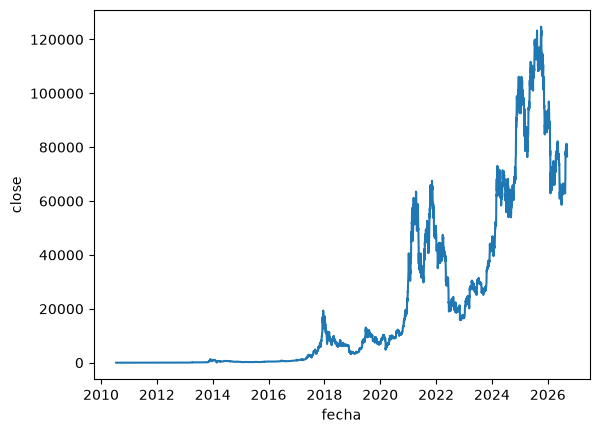

In [16]:
sns.lineplot(c2c_btc)

##### Comprobación de rigurosidad: Comparación con SP500

In [17]:
# Prueba de rigurosidad
# Aplicacion del criterio de 5% de iliquidez con el SP500 

# Urquhart (2016) aporta el argumento general: el mercado empieza a comportarse de forma eficiente a partir de 2013. Esto se comprueba con el criterio del 5% de iliquidez:
r = np.log(c2c_sp500).diff().dropna()
ceros = (r == 0).resample("ME").sum()                     # proporción mensual de días sin cambio
dias = r.resample("ME").size()
cuota_6m = ceros.rolling(6).sum() / dias.rolling(6).sum()   # proporción en 6 meses

#print("=== Criterio de 5% de iliquidez: sp500 ===")
print(cuota_6m[cuota_6m > 0.05].index.max())

NaT


In [18]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_btc["tipo_anomalia"], marcas_btc["accion"])

accion,conservar,valor_minimo
tipo_anomalia,,
extremo,4,0
ninguna,4565,0
nulo_legitimo,0,8


##### Validación de la alineación de Bitcoin al calendario hábil

In [19]:
# %% Calidad datos crudos -Validación de la alineación de Bitcoin al calendario hábil
# Criterios fijados antes de ejecutar:
#   C1  Cuota de la varianza de Bitcoin en días no hábiles (descriptivo).
#   C2  Varianza perdida al alinear (sesgo), con IC bootstrap. Umbral: 10 %.
#   C3  Correlación entre volatilidad alineada y de calendario completo (5 y 22).
# Regla: si C2 o C3 no son aceptables, Bitcoin se analiza en calendario completo.

def preparar_alineacion(btc_close, cal_habil):
    """Variaciones de Bitcoin y asignación de cada día al día hábil igual o siguiente."""
    r = np.log(btc_close.sort_index()).diff().dropna()
    cal = pd.DatetimeIndex(cal_habil).sort_values()
    r = r[(r.index > cal[0]) & (r.index <= cal[-1])]
    df = pd.DataFrame({"r": r.values, "r2": r.values ** 2}, index=r.index)
    df["habil"] = r.index.isin(cal)
    df["dia_habil"] = cal[cal.searchsorted(r.index)]          # sábado y domingo -> lunes
    return df


def agregar_alineacion(df):
    """Una fila por día hábil: versión alineada y versión de calendario completo."""
    d = df.groupby("dia_habil").agg(r_alineado=("r", "sum"), var_calendario=("r2", "sum"))
    d["var_alineada"] = d["r_alineado"] ** 2
    return d


def perdida_alineacion(d):
    """C2: proporción de varianza perdida al alinear (negativa si se gana)."""
    return 1 - d["var_alineada"].sum() / d["var_calendario"].sum()


def ic_perdida_alineacion(d, bloque=22, n_boot=2000, semilla=42):
    """C2: IC al 95 % por bootstrap de bloques móviles."""
    rng = np.random.default_rng(semilla)
    n, k = len(d), len(d) // bloque
    valores = []
    for _ in range(n_boot):
        inicios = rng.integers(0, n - bloque, size=k)
        idx = np.concatenate([np.arange(s, s + bloque) for s in inicios])
        valores.append(perdida_alineacion(d.iloc[idx]))
    return np.percentile(valores, [2.5, 97.5])


def validar_alineacion(btc_close, cal_habil, horizontes=(5, 22)):
    df = preparar_alineacion(btc_close, cal_habil)
    d = agregar_alineacion(df)
    c1_obs = df.loc[~df["habil"], "r2"].sum() / df["r2"].sum()
    c1_esp = (~df["habil"]).mean()
    c2 = perdida_alineacion(d)
    c2_ic = ic_perdida_alineacion(d)
    c3 = {}
    for h in horizontes:
        al = np.log(d["var_alineada"].rolling(h).mean())
        ca = np.log(d["var_calendario"].rolling(h).mean())
        ok = np.isfinite(al) & np.isfinite(ca)
        c3[h] = np.corrcoef(al[ok], ca[ok])[0, 1]

    print(f"Muestra: {btc_close.index.min().date()} a {btc_close.index.max().date()}")
    print(f"C1  Cuota de varianza en días no hábiles: {c1_obs:.1%} (uniforme: {c1_esp:.1%})")
    print(f"C2  Varianza perdida al alinear: {c2:.1%}   IC 95 %: [{c2_ic[0]:.1%}, {c2_ic[1]:.1%}]")
    for h, c in c3.items():
        print(f"C3  Correlación alineada vs calendario, h = {h:>2}: {c:.3f}")
    return {"c1_obs": c1_obs, "c1_esp": c1_esp, "c2": c2, "c2_ic": tuple(c2_ic), "c3": c3}


# Ejecución con la muestra del estudio (inicio tras el cierre de Mt. Gox)
res_alineacion_btc = validar_alineacion(c2c_btc.loc[INICIO["btc"]:], cal_sp500)

Muestra: 2014-03-01 a 2026-09-10
C1  Cuota de varianza en días no hábiles: 18.6% (uniforme: 31.1%)
C2  Varianza perdida al alinear: 3.0%   IC 95 %: [-0.9%, 6.5%]
C3  Correlación alineada vs calendario, h =  5: 0.941
C3  Correlación alineada vs calendario, h = 22: 0.975


No solo afecta la liquidez como se vio en el criterio previo. También afecta la varianza.

De esta manera se define que la fecha de inicio es 2014-03-01.

#### S&P500

In [20]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_sp500["tipo_anomalia"], marcas_sp500["accion"])

accion,conservar,valor_minimo
tipo_anomalia,,
extremo,10,0
ninguna,6927,0
nulo_legitimo,0,25
racha,0,2


In [21]:
marcas_sp500[marcas_sp500["accion"] == "revisar"]

,r,nulo,fin_semana,fuera,racha,extremo,tipo_anomalia,accion,motivo
fecha,,,,,,,,,


#### Oro - XAU USD

In [22]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_gold_xauusd["tipo_anomalia"], marcas_gold_xauusd["accion"])

accion,conservar,eliminar,valor_minimo
tipo_anomalia,,,
extremo,5,0,0
fuera_sesion_con_variacion,47,0,0
fuera_sesion_nulo,0,4,0
ninguna,7122,0,0
nulo_legitimo,0,0,30


In [23]:
marcas_gold_xauusd[marcas_gold_xauusd["accion"] == "revisar"]

,r,nulo,fin_semana,fuera,racha,extremo,tipo_anomalia,accion,motivo
fecha,,,,,,,,,


#### Oil - WTI

In [24]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_oil_wti["tipo_anomalia"], marcas_oil_wti["accion"])

accion,conservar,eliminar,valor_minimo
tipo_anomalia,,,
extremo,6,0,0
fin_de_semana,0,47,0
fuera_sesion_con_variacion,18,0,0
fuera_sesion_nulo,0,2,0
ninguna,7006,0,0
nulo_legitimo,0,0,21


In [25]:
marcas_oil_wti[marcas_oil_wti["accion"] == "revisar"]

,r,nulo,fin_semana,fuera,racha,extremo,tipo_anomalia,accion,motivo
fecha,,,,,,,,,


#### Oil - Brent

In [26]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_oil_brent["tipo_anomalia"], marcas_oil_brent["accion"])

accion,conservar,eliminar,valor_minimo
tipo_anomalia,,,
extremo,3,0,0
fuera_sesion_con_variacion,10,0,0
fuera_sesion_nulo,0,1,0
ninguna,7074,0,0
nulo_legitimo,0,0,23


In [27]:
marcas_oil_brent[marcas_oil_brent["accion"] == "revisar"]

,r,nulo,fin_semana,fuera,racha,extremo,tipo_anomalia,accion,motivo
fecha,,,,,,,,,


#### Treasury - us10y

In [28]:
# Inspección: recuento por tipo y acción de cada activo
pd.crosstab(marcas_us10y["tipo_anomalia"], marcas_us10y["accion"])

accion,conservar,eliminar,valor_minimo
tipo_anomalia,,,
fin_de_semana,0,40,0
fuera_sesion,0,177,0
ninguna,6851,0,0
nulo_legitimo,0,0,68
racha,0,0,2


In [29]:
marcas_us10y[marcas_us10y["accion"] == "revisar"]

,r,nulo,fin_semana,fuera,racha,extremo,tipo_anomalia,accion,motivo
fecha,,,,,,,,,


Se revisan los 2 dias de racha contra la funete de la FRED: https://fred.stlouisfed.org/graph/?g=1ZkQm

## Serie de riesgo geopolítico

In [30]:
# Checkpoint
df_btc_gpr         = df_btc_limpio.copy()
df_sp500_gpr       = df_sp500_limpio.copy()
df_oil_wti_gpr     = df_oil_wti_limpio.copy()
df_oil_brent_gpr   = df_oil_brent_limpio.copy()
df_gold_xauusd_gpr = df_gold_xauusd_limpio.copy()
df_us10y_gpr       = df_us10y_limpio.copy()

In [31]:
# Calidad datos -10-. 
gpr_frames = {"gpr_daily": [], "gpr_eventtype": []}
for (key, fname), df in raw.items():
    if key not in gpr_frames:                                    
        continue
    part = df.copy()
    part.insert(0, "key", key)                                      
    part.insert(1, "file", fname)                                   
    part["date"] = pd.to_datetime(part.pop("Date"), format="%Y-%m-%d")
    cols_num = [c for c in part.columns if c not in ("key", "file", "date")]
    part[cols_num] = part[cols_num].apply(pd.to_numeric, errors="coerce") 
    gpr_frames[key].append(part)

df_gpr_daily     = pd.concat(gpr_frames["gpr_daily"], ignore_index=True).sort_values("date", ignore_index=True)
df_gpr_eventtype = pd.concat(gpr_frames["gpr_eventtype"], ignore_index=True).sort_values("date", ignore_index=True)

In [32]:
# Validacion de nulos.
# Ambos valores deben ser 0. 
df_gpr_daily.isna().sum().sum(), df_gpr_eventtype.isna().sum().sum() 

(np.int64(0), np.int64(0))

In [33]:
# Validacion de fechas
print(df_gpr_daily["date"].agg(["min", "max"]))
print(df_gpr_eventtype["date"].agg(["min", "max"]))

min   1960-01-01
max   2026-08-31
Name: date, dtype: datetime64[us]
min   1960-01-01
max   2026-08-01
Name: date, dtype: datetime64[us]


In [34]:
# Calidad datos crudos -11-. Calidad de AI-GPR
print(f'{(df_gpr_daily["date"].diff().dt.days.dropna() == 1).all()}')                    # diario: días consecutivos, sin huecos
print(f'{df_gpr_daily["date"].is_unique, df_gpr_eventtype["date"].is_unique}')           # sin fechas duplicadas
print(f'{(df_gpr_eventtype["date"].dt.day == 1).all()}')                                  # mensual: todas las fechas el día 1
print(f'{(df_gpr_daily["GPR_AI"] > 0).all()}')                                            # positivo: el logaritmo existe

CATEGORIAS = ["military_conflict", "diplomatic_tension", "terrorism", "civil_war", "nuclear_threat", "coup", "sanctions", "other"]
print(f'{(df_gpr_eventtype[CATEGORIAS] >= 0).all().all()}')                                       # categorías no negativas
print(f'{(df_gpr_eventtype[CATEGORIAS].sum(axis=1) - df_gpr_eventtype["GPR_AI"]).abs().max()}')   # suma de categorías frente al total

True
(True, True)
True
True
True
0.00020000000002085017


In [35]:
def agregar_gpr_intensidad(df, df_gpr, horizontes=(5, 22), col="GPR_AI"):
    """Añade la intensidad del riesgo geopolítico alineada a las sesiones del activo.
    Cada día del AI-GPR se asigna a la sesión igual o siguiente; los días no hábiles
    se agregan con la media. gpr_d: día; gpr_{h}: media de las h sesiones hasta t."""
    df = df.sort_values("date")
    sesiones = pd.DatetimeIndex(df["date"])
    g = df_gpr.loc[df_gpr["date"].between(sesiones[0], sesiones[-1]), ["date", col]].copy()
    g["sesion"] = sesiones[sesiones.searchsorted(g["date"])]       # sábado y domingo -> lunes
    nivel = df["date"].map(g.groupby("sesion")[col].mean())
    df["gpr_n_dias"] = df["date"].map(g.groupby("sesion").size())   # días agregados en cada sesión
    df["gpr_d"] = np.log(nivel)
    for h in horizontes:
        df[f"gpr_{h}"] = np.log(nivel.rolling(h).mean())            # media y después logaritmo
    return df

df_btc_gpr         = agregar_gpr_intensidad(df_btc_limpio,         df_gpr_daily, horizontes=(7, 30))
df_sp500_gpr       = agregar_gpr_intensidad(df_sp500_limpio,       df_gpr_daily, horizontes=(5, 22))
df_oil_wti_gpr     = agregar_gpr_intensidad(df_oil_wti_limpio,     df_gpr_daily, horizontes=(5, 22))
df_oil_brent_gpr   = agregar_gpr_intensidad(df_oil_brent_limpio,   df_gpr_daily, horizontes=(5, 22))
df_gold_xauusd_gpr = agregar_gpr_intensidad(df_gold_xauusd_limpio, df_gpr_daily, horizontes=(5, 22))
df_us10y_gpr       = agregar_gpr_intensidad(df_us10y_limpio,       df_gpr_daily, horizontes=(5, 22))

In [36]:
TIPOS_EVENTO = ["military_conflict", "diplomatic_tension", "terrorism", "civil_war",
                "nuclear_threat", "coup", "sanctions"]                    # "other" queda como referencia

def agregar_gpr_composicion(df, df_evt, tipos=TIPOS_EVENTO):
    """Añade la proporción de cada tipo de evento del MES ANTERIOR (rezago de un mes).
    La proporción es el valor de la categoría dividido entre el índice total del mes."""
    df = df.sort_values("date")
    mes = df_evt["date"].dt.to_period("M")
    prop = df_evt.set_index(mes)[tipos].div(df_evt.set_index(mes)["GPR_AI"], axis=0)
    mes_anterior = df["date"].dt.to_period("M") - 1                       # rezago de un mes
    for t in tipos:
        df[f"s_{t}"] = mes_anterior.map(prop[t])
    return df

In [37]:
df_btc_f2         = agregar_gpr_composicion(df_btc_gpr,         df_gpr_eventtype)
df_sp500_f2       = agregar_gpr_composicion(df_sp500_gpr,       df_gpr_eventtype)
df_oil_wti_f2     = agregar_gpr_composicion(df_oil_wti_gpr,     df_gpr_eventtype)
df_oil_brent_f2   = agregar_gpr_composicion(df_oil_brent_gpr,   df_gpr_eventtype)
df_gold_xauusd_f2 = agregar_gpr_composicion(df_gold_xauusd_gpr, df_gpr_eventtype)
df_us10y_f2       = agregar_gpr_composicion(df_us10y_gpr,       df_gpr_eventtype)

In [38]:
print(f'{df_sp500_f2.groupby(df_sp500_f2["date"].dt.to_period("M"))["s_sanctions"].nunique().max()}')                          # 1: constante dentro de cada mes
print(f'{df_sp500_f2.loc[df_sp500_f2["date"] == "2022-03-01", "s_military_conflict"]}')                                        # debe ser la proporción de febrero de 2022
print(f'{(df_gpr_eventtype["military_conflict"] / df_gpr_eventtype["GPR_AI"])[df_gpr_eventtype["date"] == "2022-02-01"]}')     # proporción de febrero de 2022, para comparar

1
33145   0.5921
Name: s_military_conflict, dtype: float64
745   0.5921
dtype: float64


In [39]:
prop = df_gpr_eventtype.set_index("date")[TIPOS_EVENTO].div(df_gpr_eventtype.set_index("date")["GPR_AI"], axis=0)
display(prop.loc["1999-01-01":"2021-12-01"].agg(["mean", "std"]).T)   # entrenamiento
display(prop.loc["2022-01-01":].agg(["mean", "std"]).T)               # prueba
display(prop.loc["1999-01-01":].apply(lambda s: s.autocorr(lag=1)))   # persistencia, en la muestra del estudio

,mean,std
military_conflict,0.2417,0.1129
diplomatic_tension,0.3171,0.0993
terrorism,0.1598,0.0834
civil_war,0.0711,0.0456
nuclear_threat,0.0431,0.0298
coup,0.0135,0.0191
sanctions,0.0251,0.0235


,mean,std
military_conflict,0.4763,0.1263
diplomatic_tension,0.2468,0.0793
terrorism,0.0583,0.0309
civil_war,0.0302,0.0250
nuclear_threat,0.0203,0.0149
coup,0.0131,0.0178
sanctions,0.0449,0.0409


military_conflict    0.7481
diplomatic_tension   0.7185
terrorism            0.6452
civil_war            0.7655
nuclear_threat       0.5246
coup                 0.3422
sanctions            0.6951
dtype: float64

In [40]:
entreno = prop.loc["1999-01-01":"2021-12-01"]
prueba = prop.loc["2022-01-01":]
((prueba > entreno.max()) | (prueba < entreno.min())).mean()   # proporción de meses de prueba fuera del rango de entrenamiento

military_conflict    0.0536
diplomatic_tension   0.0357
terrorism            0.1429
civil_war            0.2143
nuclear_threat       0.0000
coup                 0.0000
sanctions            0.0179
dtype: float64

# EDA

,military_conflict,diplomatic_tension,terrorism,civil_war,nuclear_threat,coup,sanctions,log_gpr
military_conflict,1.0000,-0.7000,-0.3000,-0.3800,-0.2300,-0.2100,-0.1200,0.6200
diplomatic_tension,-0.7000,1.0000,-0.3000,0.0600,-0.0200,0.1500,0.3600,-0.4900
terrorism,-0.3000,-0.3000,1.0000,-0.0200,0.1100,-0.1000,-0.3900,-0.0700
civil_war,-0.3800,0.0600,-0.0200,1.0000,0.1100,0.1300,-0.1600,-0.3200
nuclear_threat,-0.2300,-0.0200,0.1100,0.1100,1.0000,-0.1100,-0.1700,-0.2000
coup,-0.2100,0.1500,-0.1000,0.1300,-0.1100,1.0000,-0.0100,-0.1600
sanctions,-0.1200,0.3600,-0.3900,-0.1600,-0.1700,-0.0100,1.0000,0.1800
log_gpr,0.6200,-0.4900,-0.0700,-0.3200,-0.2000,-0.1600,0.1800,1.0000


array([[<Axes: xlabel='log_gpr', ylabel='log_gpr'>,
        <Axes: xlabel='military_conflict', ylabel='log_gpr'>,
        <Axes: xlabel='diplomatic_tension', ylabel='log_gpr'>,
        <Axes: xlabel='terrorism', ylabel='log_gpr'>],
       [<Axes: xlabel='log_gpr', ylabel='military_conflict'>,
        <Axes: xlabel='military_conflict', ylabel='military_conflict'>,
        <Axes: xlabel='diplomatic_tension', ylabel='military_conflict'>,
        <Axes: xlabel='terrorism', ylabel='military_conflict'>],
       [<Axes: xlabel='log_gpr', ylabel='diplomatic_tension'>,
        <Axes: xlabel='military_conflict', ylabel='diplomatic_tension'>,
        <Axes: xlabel='diplomatic_tension', ylabel='diplomatic_tension'>,
        <Axes: xlabel='terrorism', ylabel='diplomatic_tension'>],
       [<Axes: xlabel='log_gpr', ylabel='terrorism'>,
        <Axes: xlabel='military_conflict', ylabel='terrorism'>,
        <Axes: xlabel='diplomatic_tension', ylabel='terrorism'>,
        <Axes: xlabel='terrorism', yl

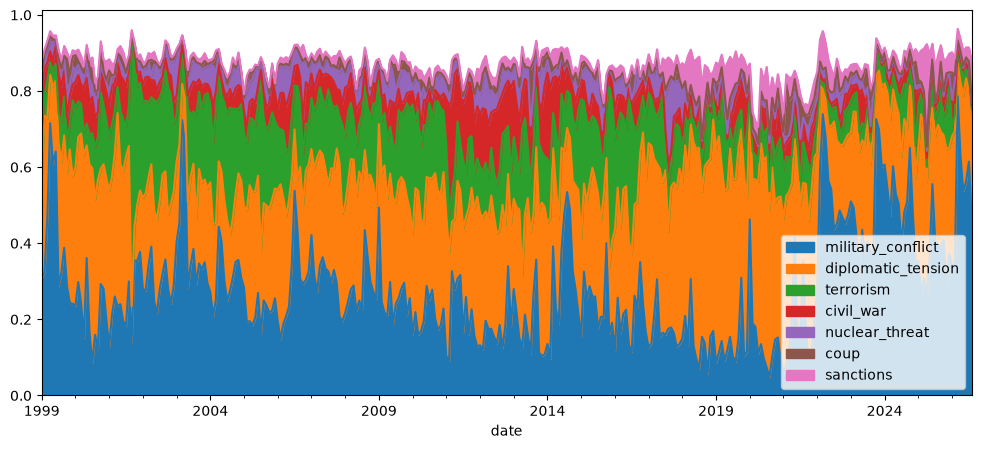

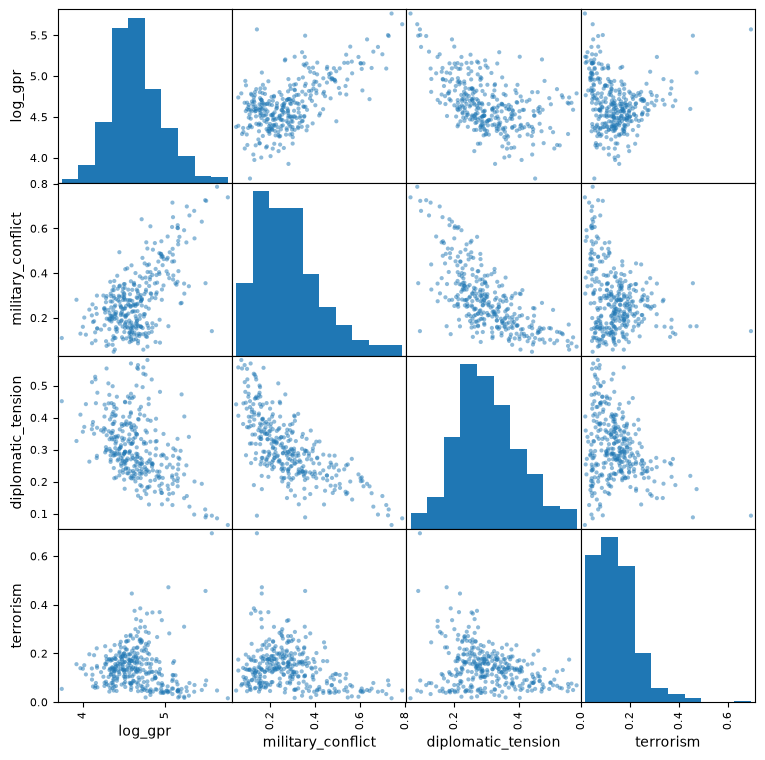

In [41]:
mensual = prop.loc["1999-01-01":].copy()
mensual["log_gpr"] = np.log(df_gpr_eventtype.set_index("date")["GPR_AI"].loc["1999-01-01":])

display(mensual.corr().round(2))                                     # 1. correlaciones entre proporciones e intensidad
mensual[TIPOS_EVENTO].plot.area(figsize=(12, 5))                     # 2. evolución de la composición
pd.plotting.scatter_matrix(mensual[["log_gpr", "military_conflict", "diplomatic_tension", "terrorism"]], figsize=(9, 9))   # 3. relaciones

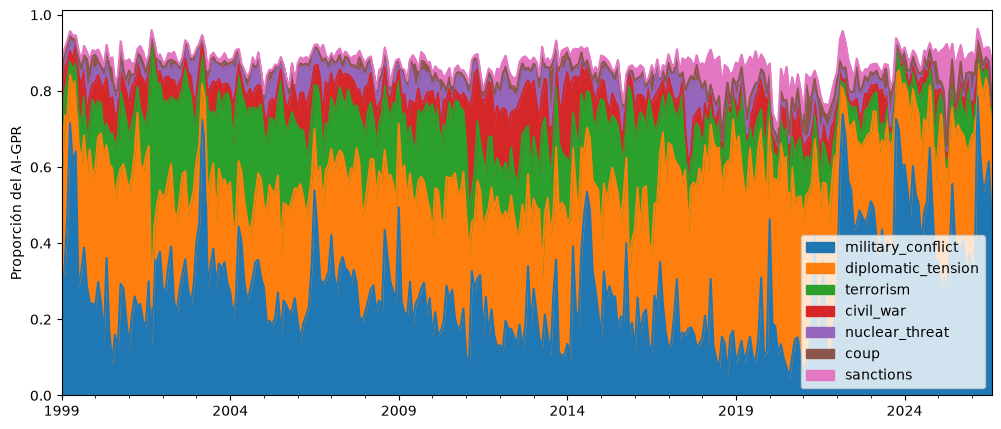

In [42]:
ax = mensual[TIPOS_EVENTO].plot.area(figsize=(12, 5))
ax.set_ylabel("Proporción del AI-GPR"); ax.set_xlabel("")
ax.figure.savefig("figuras/composicion_tipos_evento.png", dpi=200, bbox_inches="tight")

In [43]:
# EDA -1-. Tabla descriptiva de la volatilidad (series limpias)
display(pd.DataFrame({
    "btc": df_btc_limpio["rv"].describe(), "sp500": df_sp500_limpio["rv"].describe(),
    "oil_brent": df_oil_brent_limpio["rv"].describe(), "oil_wti": df_oil_wti_limpio["rv"].describe(),
    "gold_xauusd": df_gold_xauusd_limpio["rv"].describe(), "us10y": df_us10y_limpio["rv"].describe()}).T)
print(df_btc_limpio["rv"].skew(), df_btc_limpio["log_rv_d"].skew())               # repetir por activo
print(df_btc_limpio["rv"].kurt(), df_btc_limpio["log_rv_d"].kurt())

,count,mean,std,min,25%,50%,75%,max
btc,"4,576.0000",0.0013,0.0050,0.0000,0.0000,0.0002,0.0009,0.2473
sp500,"6,963.0000",0.0001,0.0005,0.0000,0.0000,0.0000,0.0001,0.0163
oil_brent,"7,109.0000",0.0005,0.0019,0.0000,0.0000,0.0001,0.0005,0.0783
oil_wti,"7,050.0000",0.0007,0.0060,0.0000,0.0000,0.0002,0.0006,0.3378
gold_xauusd,"7,203.0000",0.0001,0.0004,0.0000,0.0000,0.0000,0.0001,0.0109
us10y,"6,920.0000",0.0036,0.0073,0.0000,0.0003,0.0013,0.0038,0.2162


29.045412704350888 -0.616206530411466
1316.6235618084775 0.20604448584285118


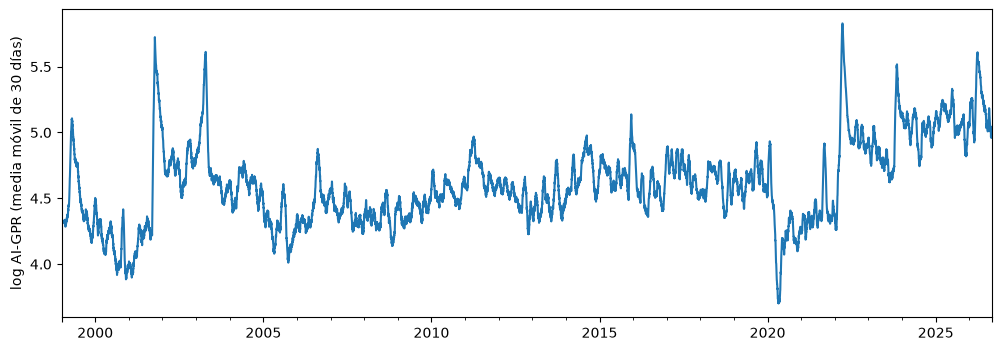

In [44]:
# EDA -2-. AI-GPR diario
ax = np.log(df_gpr_daily.set_index("date").loc["1999-01-01":, "GPR_AI"]).rolling(30).mean().plot(figsize=(12, 4))
ax.set_ylabel("log AI-GPR (media móvil de 30 días)"); ax.set_xlabel("")
ax.figure.savefig("figuras/aigpr_diario.png", dpi=200, bbox_inches="tight")

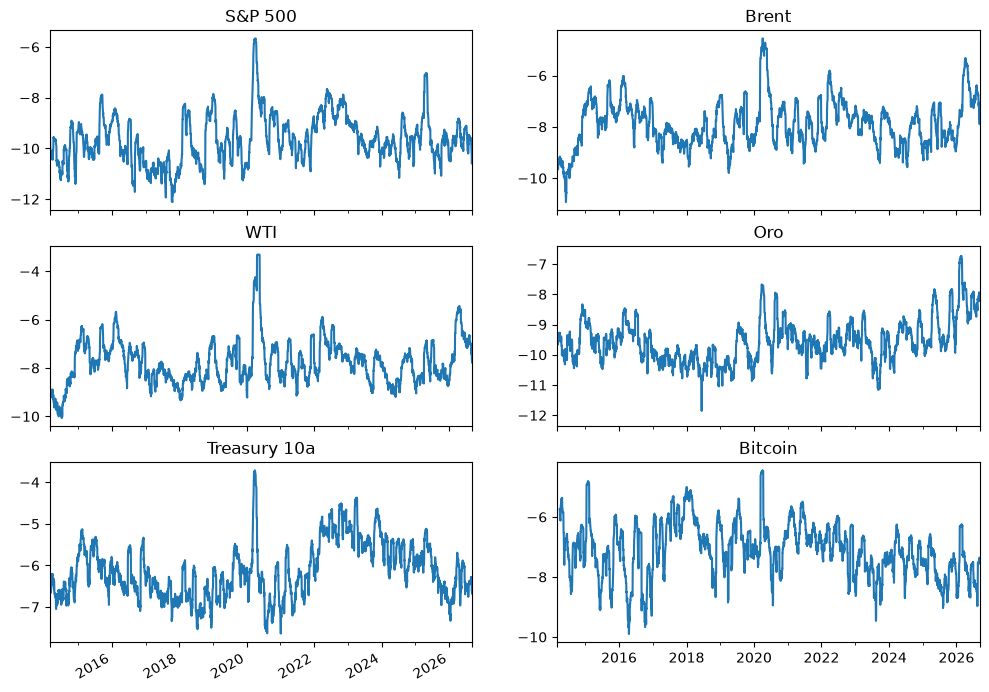

In [45]:
# EDA -3-. Volatilidad de cada activo (media mensual en logaritmos)
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, (nombre, d) in zip(axes.flat, {"S&P 500": df_sp500_limpio, "Brent": df_oil_brent_limpio, "WTI": df_oil_wti_limpio,
                                        "Oro": df_gold_xauusd_limpio, "Treasury 10a": df_us10y_limpio, "Bitcoin": df_btc_limpio}.items()):
    col = "log_rv_30" if nombre == "Bitcoin" else "log_rv_22"
    d.set_index("date")[col].plot(ax=ax, title=nombre); ax.set_xlabel("")
fig.savefig("figuras/volatilidad_activos.png", dpi=200, bbox_inches="tight")

In [46]:
# EDA -4-. Señal exploratoria: intensidad frente a volatilidad futura (solo entrenamiento)
print(df_sp500_gpr.loc[df_sp500_gpr["date"] < "2022-01-01", ["gpr_22", "objetivo_22"]].corr().iloc[0, 1])   # repetir por activo

-0.15631990214896013


# Modelado

In [47]:
# Modelado -1. Conjuntos de variables y fechas clave
F0 = ["rv_d", "rv_w", "rv_m"]                                  # componentes HAR
F1 = F0 + ["gpr_d", "gpr_w", "gpr_m"]                          # + intensidad
F2 = F1 + [f"s_{t}" for t in TIPOS_EVENTO]                     # + composición ("other" como referencia)
FIN_GPR = pd.Timestamp("2026-08-31")                           # última fecha del AI-GPR diario
INICIO_PRUEBA = pd.Timestamp("2022-01-01")


def construir_matriz(df, w, m):
    """Matriz de un activo con nombres genéricos: w y m son los horizontes semanal y mensual."""
    x = pd.DataFrame({
        "date":  df["date"],
        "rv_d":  df["log_rv_d"],  "rv_w":  df[f"log_rv_{w}"],  "rv_m":  df[f"log_rv_{m}"],
        "gpr_d": df["gpr_d"],     "gpr_w": df[f"gpr_{w}"],     "gpr_m": df[f"gpr_{m}"],
        **{f"s_{t}": df[f"s_{t}"] for t in TIPOS_EVENTO},
        "y_w":   df[f"objetivo_{w}"],   "y_m":   df[f"objetivo_{m}"],
    })
    x = x[x["date"] <= FIN_GPR].dropna(subset=F2)              # solo filas con todos los predictores
    x["periodo"] = np.where(x["date"] < INICIO_PRUEBA, "entrenamiento", "prueba")
    return x.reset_index(drop=True)

In [48]:
mat_btc         = construir_matriz(df_btc_f2,         7, 30)
mat_sp500       = construir_matriz(df_sp500_f2,       5, 22)
mat_oil_brent   = construir_matriz(df_oil_brent_f2,   5, 22)
mat_oil_wti     = construir_matriz(df_oil_wti_f2,     5, 22)
mat_gold_xauusd = construir_matriz(df_gold_xauusd_f2, 5, 22)
mat_us10y       = construir_matriz(df_us10y_f2,       5, 22)

In [49]:
# comprobaciones
print(f'{mat_sp500.groupby("periodo")["date"].agg(["min", "max", "count"])}')          # fechas y tamaño de cada periodo
print(f'{mat_sp500[F2].isna().sum().sum()}')                                            # 0: predictores completos
print(f'{mat_sp500[["y_w", "y_m"]].isna().sum()}')                                      # solo las últimas filas
print(f'{mat_sp500.loc[mat_sp500["y_m"].isna(), "date"].min()}')                        # primera fecha sin objetivo mensual

                     min        max  count
periodo                                   
entrenamiento 1999-02-04 2021-12-31   5766
prueba        2022-01-03 2026-08-31   1169
0
y_w     0
y_m    15
dtype: int64
2026-08-11 00:00:00


In [50]:
# comprobaciones
print(f'{mat_btc.groupby("periodo")["date"].agg(["min", "max", "count"])}')          # fechas y tamaño de cada periodo
print(f'{mat_btc[F2].isna().sum().sum()}')                                            # 0: predictores completos
print(f'{mat_btc[["y_w", "y_m"]].isna().sum()}')                                      # solo las últimas filas
print(f'{mat_btc.loc[mat_btc["y_m"].isna(), "date"].min()}')                        # primera fecha sin objetivo mensual

                     min        max  count
periodo                                   
entrenamiento 2014-03-31 2021-12-31   2833
prueba        2022-01-01 2026-08-31   1704
0
y_w     0
y_m    20
dtype: int64
2026-08-12 00:00:00


In [51]:
# %% Modelado -2- Importaciones y funciones base (QLIKE, evaluación y ventana expansiva)
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor


def qlike_niveles(y_log, pred_log, sigma2):
    """QLIKE en niveles, con la corrección del sesgo al deshacer el logaritmo."""
    y, p = np.exp(y_log), np.exp(pred_log + np.asarray(sigma2) / 2)
    return float(np.mean(y / p - np.log(y / p) - 1))


def evaluar(pred):
    p = pred.copy()
    p["y_niv"] = np.exp(p["y"])
    p["pred_niv"] = np.exp(p["pred"] + p["sigma2"] / 2)                    # corrección al volver a niveles
    p["mse"] = (p["y_niv"] - p["pred_niv"]) ** 2
    p["qlike"] = p["y_niv"] / p["pred_niv"] - np.log(p["y_niv"] / p["pred_niv"]) - 1
    res = p.groupby(["conjunto", "estimador"])[["mse", "qlike"]].mean()
    ref = res.loc[("F0", "lineal")]                                         # HAR-RV
    res["r2oos_mse"] = 1 - res["mse"] / ref["mse"]                          # > 0: mejora frente al HAR-RV
    res["r2oos_qlike"] = 1 - res["qlike"] / ref["qlike"]                    # > 0: mejora frente al HAR-RV
    return res


def ventana_expansiva(mat, y_col, h, conjuntos, mejores, etiqueta=""):
    """Igual que la versión del piloto, pero cada estimador usa sus hiperparámetros ajustados."""
    mat = mat.dropna(subset=[y_col]).reset_index(drop=True)
    prueba = mat.index[mat["periodo"] == "prueba"]
    meses = mat.loc[prueba, "date"].dt.to_period("M")
    lista_meses = meses.unique()
    tiempos, filas, inicio = {}, [], datetime.now()
    print(f"[{inicio:%H:%M:%S}] Inicio {etiqueta}: {len(lista_meses)} reestimaciones")
    for k, mes in enumerate(lista_meses, start=1):
        idx_pred = prueba[meses == mes]
        train = mat.iloc[: idx_pred[0] - h + 1]                             # purga
        for nombre_conj, cols in conjuntos.items():
            for _, fila in mejores[mejores["conjunto"] == nombre_conj].iterrows():
                t_est = datetime.now()
                est = construir_estimador(fila["estimador"], fila["params"]).fit(train[cols], train[y_col])
                cola = train.iloc[-500:]
                sigma2 = float(np.var(cola[y_col] - est.predict(cola[cols])))
                filas.append(pd.DataFrame({
                    "date": mat.loc[idx_pred, "date"].values,
                    "conjunto": nombre_conj, "estimador": fila["estimador"],
                    "y": mat.loc[idx_pred, y_col].values,
                    "pred": est.predict(mat.loc[idx_pred, cols]), "sigma2": sigma2,
                }))
                tiempos[fila["estimador"]] = tiempos.get(fila["estimador"], 0) + (datetime.now() - t_est).total_seconds()
        transcurrido = datetime.now() - inicio
        restante = transcurrido / k * (len(lista_meses) - k)
        print(f"[{datetime.now():%H:%M:%S}] {etiqueta} {mes} ({k}/{len(lista_meses)}) | "
              f"transcurrido {str(transcurrido).split('.')[0]} | restante estimado {str(restante).split('.')[0]}")
    print(f"[{datetime.now():%H:%M:%S}] Fin {etiqueta}: {str(datetime.now() - inicio).split('.')[0]}")
    print("Segundos por estimador:", {k: round(v, 1) for k, v in tiempos.items()})
    return pd.concat(filas, ignore_index=True)

## Ajuste de hiperparámetros en dos fases y predicciones

In [52]:
# %% Modelado -35- Estimadores, envoltorio con varianza del error y métrica QLIKE
from uuid import uuid4
CONJ_M = {"F0": F0, "F1": F1, "F2": F2}                                  # horizonte mensual
CONJ_W = {"F0": F0, "F1": F1}                                            # horizonte semanal: sin composición
ID_EJECUCION = f"{datetime.now():%Y%m%d_%H%M%S}_{uuid4().hex[:6]}"      # identificador de la ejecución definitiva
print(ID_EJECUCION)
from scipy.stats import loguniform, uniform, randint
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, TimeSeriesSplit


def construir_estimador(nombre, params=None, n_jobs_xgb=-1):
    """Estimador nuevo. Los parámetros recibidos prevalecen sobre los valores por defecto."""
    params = params or {}
    if nombre == "lineal":
        return LinearRegression()
    if nombre == "enet":
        return make_pipeline(StandardScaler(), ElasticNet(**{"max_iter": 10000, **params}))
    if nombre == "svr":
        return make_pipeline(StandardScaler(), SVR(**{"cache_size": 1000, "max_iter": 200_000, **params}))
    if nombre == "xgboost":
        return XGBRegressor(**{"subsample": 0.8, "random_state": SEED, "n_jobs": n_jobs_xgb, **params})
    raise ValueError(nombre)


class ConVarianza(BaseEstimator, RegressorMixin):
    """Envoltorio que, al entrenar, guarda la varianza del error de las últimas 500 filas
    (la misma que usa la corrección del sesgo), para que la métrica QLIKE pueda leerla."""
    def __init__(self, estimador=None):
        self.estimador = estimador

    def fit(self, X, y):
        self.est_ = clone(self.estimador).fit(X, y)
        cola_X, cola_y = X.iloc[-500:], y.iloc[-500:]
        self.sigma2_ = float(np.var(cola_y - self.est_.predict(cola_X)))
        return self

    def predict(self, X):
        return self.est_.predict(X)


def metrica_qlike(estimador, X, y):
    """QLIKE en niveles con signo negativo (scikit-learn maximiza la métrica)."""
    return -qlike_niveles(np.asarray(y), estimador.predict(X), estimador.sigma2_)


# Prefijos de los parámetros dentro del envoltorio y del pipeline
PREFIJO = {"enet": "estimador__elasticnet__", "svr": "estimador__svr__", "xgboost": "estimador__"}

DISTRIBUCIONES = {
    "enet":    {"alpha": loguniform(1e-5, 10), "l1_ratio": uniform(0, 1)},
    "svr":     {"C": loguniform(1e-3, 1e3), "epsilon": loguniform(0.01, 2), "gamma": loguniform(1e-3, 1)},
    "xgboost": {"max_depth": randint(1, 7), "n_estimators": randint(100, 1501), "learning_rate": loguniform(0.005, 0.3),
                "min_child_weight": loguniform(1, 100), "subsample": uniform(0.5, 0.5),
                "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(0.1, 100)},
}


def rejilla_fina(nombre, mejor):
    """Fase 2: mitad, igual y doble del mejor valor de la fase 1 en los parámetros principales
    (profundidad: -1, igual, +1). El resto de parámetros se fija en el valor de la fase 1."""
    principales = {"enet": ["alpha", "l1_ratio"], "svr": ["C", "epsilon", "gamma"],
                   "xgboost": ["max_depth", "learning_rate", "n_estimators"]}[nombre]
    rejilla = {}
    for k, v in mejor.items():
        if k not in principales:
            rejilla[k] = [v]
        elif k == "max_depth":
            rejilla[k] = sorted({max(1, v - 1), v, v + 1})
        elif k == "n_estimators":
            rejilla[k] = sorted({max(50, int(v / 2)), int(v), int(v * 2)})
        elif k == "l1_ratio":
            rejilla[k] = sorted({max(0.0, v / 2), v, min(1.0, v * 2)})
        else:
            rejilla[k] = [v / 2, v, v * 2]
    return rejilla

20261109_113346_e8873a


In [53]:
# %% Modelado -36- Ajuste en dos fases de un caso
def ajustar_dos_fases(mat, y_col, h, gap, conjuntos, etiqueta="", n_iter=40, semilla=SEED):
    """Fase 1: búsqueda aleatoria amplia. Fase 2: rejilla fina alrededor del mejor punto.
    Solo usa el periodo de entrenamiento, sin sus últimas h filas. Mismo formato de salida que ajustar()."""
    train = mat[mat["periodo"] == "entrenamiento"].dropna(subset=[y_col]).reset_index(drop=True)
    train = train.iloc[: len(train) - h]
    cv = TimeSeriesSplit(n_splits=5, gap=gap)
    filas, inicio = [], datetime.now()
    print(f"[{inicio:%H:%M:%S}] Inicio ajuste en dos fases {etiqueta} ({len(train)} filas)")
    for nombre_conj, cols in conjuntos.items():
        X, y = train[cols], train[y_col]
        # Lineal: sin hiperparámetros, solo su QLIKE de validación
        gs = GridSearchCV(ConVarianza(construir_estimador("lineal")), {}, scoring=metrica_qlike, cv=cv).fit(X, y)
        filas.append({"conjunto": nombre_conj, "estimador": "lineal", "params": {}, "qlike_cv": -gs.best_score_,
                      "fase1_params": {}, "fase1_qlike": -gs.best_score_})
        for nombre in ["enet", "svr", "xgboost"]:
            t = datetime.now()
            base = ConVarianza(construir_estimador(nombre, n_jobs_xgb=1))
            pre = PREFIJO[nombre]
            f1 = RandomizedSearchCV(base, {pre + k: v for k, v in DISTRIBUCIONES[nombre].items()}, n_iter=n_iter,
                                    scoring=metrica_qlike, cv=cv, random_state=semilla, n_jobs=-1, error_score=np.nan).fit(X, y)
            mejor1 = {k.replace(pre, ""): v for k, v in f1.best_params_.items()}
            f2 = GridSearchCV(base, {pre + k: v for k, v in rejilla_fina(nombre, mejor1).items()},
                              scoring=metrica_qlike, cv=cv, n_jobs=-1, error_score=np.nan).fit(X, y)
            mejor2 = {k.replace(pre, ""): v for k, v in f2.best_params_.items()}
            mejor2 = {k: (int(v) if k in ("max_depth", "n_estimators") else float(v)) for k, v in mejor2.items()}
            filas.append({"conjunto": nombre_conj, "estimador": nombre, "params": mejor2, "qlike_cv": -f2.best_score_,
                          "fase1_params": mejor1, "fase1_qlike": -f1.best_score_})
            print(f"[{datetime.now():%H:%M:%S}] {etiqueta} {nombre_conj} {nombre}: "
                  f"fase 1 {-f1.best_score_:.4f} -> fase 2 {-f2.best_score_:.4f} ({str(datetime.now() - t).split('.')[0]})")
    print(f"[{datetime.now():%H:%M:%S}] Fin ajuste {etiqueta}: {str(datetime.now() - inicio).split('.')[0]}")
    mejores = pd.DataFrame(filas)
    return mejores, mejores[["conjunto", "estimador", "params", "qlike_cv"]]

In [54]:
# %% Modelado -37- Ajuste en dos fases de los doce casos (para ejecutar de noche). Guarda cada caso al terminar.
res2_sp500_m,       mej2_sp500_m       = ajustar_dos_fases(mat_sp500,       "y_m", 22, 22, CONJ_M, "sp500 mensual");  pd.to_pickle(res2_sp500_m,       f"resultados/hp2_sp500_m_{ID_EJECUCION}.pkl")
res2_sp500_w,       mej2_sp500_w       = ajustar_dos_fases(mat_sp500,       "y_w", 5,  22, CONJ_W, "sp500 semanal");  pd.to_pickle(res2_sp500_w,       f"resultados/hp2_sp500_w_{ID_EJECUCION}.pkl")
res2_oil_brent_m,   mej2_oil_brent_m   = ajustar_dos_fases(mat_oil_brent,   "y_m", 22, 22, CONJ_M, "brent mensual");  pd.to_pickle(res2_oil_brent_m,   f"resultados/hp2_oil_brent_m_{ID_EJECUCION}.pkl")
res2_oil_brent_w,   mej2_oil_brent_w   = ajustar_dos_fases(mat_oil_brent,   "y_w", 5,  22, CONJ_W, "brent semanal");  pd.to_pickle(res2_oil_brent_w,   f"resultados/hp2_oil_brent_w_{ID_EJECUCION}.pkl")
res2_oil_wti_m,     mej2_oil_wti_m     = ajustar_dos_fases(mat_oil_wti,     "y_m", 22, 22, CONJ_M, "wti mensual");    pd.to_pickle(res2_oil_wti_m,     f"resultados/hp2_oil_wti_m_{ID_EJECUCION}.pkl")
res2_oil_wti_w,     mej2_oil_wti_w     = ajustar_dos_fases(mat_oil_wti,     "y_w", 5,  22, CONJ_W, "wti semanal");    pd.to_pickle(res2_oil_wti_w,     f"resultados/hp2_oil_wti_w_{ID_EJECUCION}.pkl")
res2_gold_xauusd_m, mej2_gold_xauusd_m = ajustar_dos_fases(mat_gold_xauusd, "y_m", 22, 22, CONJ_M, "oro mensual");    pd.to_pickle(res2_gold_xauusd_m, f"resultados/hp2_gold_xauusd_m_{ID_EJECUCION}.pkl")
res2_gold_xauusd_w, mej2_gold_xauusd_w = ajustar_dos_fases(mat_gold_xauusd, "y_w", 5,  22, CONJ_W, "oro semanal");    pd.to_pickle(res2_gold_xauusd_w, f"resultados/hp2_gold_xauusd_w_{ID_EJECUCION}.pkl")
res2_us10y_m,       mej2_us10y_m       = ajustar_dos_fases(mat_us10y,       "y_m", 22, 22, CONJ_M, "us10y mensual");  pd.to_pickle(res2_us10y_m,       f"resultados/hp2_us10y_m_{ID_EJECUCION}.pkl")
res2_us10y_w,       mej2_us10y_w       = ajustar_dos_fases(mat_us10y,       "y_w", 5,  22, CONJ_W, "us10y semanal");  pd.to_pickle(res2_us10y_w,       f"resultados/hp2_us10y_w_{ID_EJECUCION}.pkl")
res2_btc_m,         mej2_btc_m         = ajustar_dos_fases(mat_btc,         "y_m", 30, 30, CONJ_M, "btc mensual");    pd.to_pickle(res2_btc_m,         f"resultados/hp2_btc_m_{ID_EJECUCION}.pkl")
res2_btc_w,         mej2_btc_w         = ajustar_dos_fases(mat_btc,         "y_w", 7,  30, CONJ_W, "btc semanal");    pd.to_pickle(res2_btc_w,         f"resultados/hp2_btc_w_{ID_EJECUCION}.pkl")

[11:33:46] Inicio ajuste en dos fases sp500 mensual (5744 filas)


[11:33:57] sp500 mensual F0 enet: fase 1 0.4205 -> fase 2 0.4204 (0:00:11)
[11:34:14] sp500 mensual F0 svr: fase 1 0.4280 -> fase 2 0.4095 (0:00:16)
[11:34:26] sp500 mensual F0 xgboost: fase 1 0.4840 -> fase 2 0.4840 (0:00:12)
[11:34:27] sp500 mensual F1 enet: fase 1 0.4175 -> fase 2 0.4172 (0:00:00)
[11:34:48] sp500 mensual F1 svr: fase 1 0.4250 -> fase 2 0.4227 (0:00:20)
[11:35:03] sp500 mensual F1 xgboost: fase 1 0.5022 -> fase 2 0.5022 (0:00:14)
[11:35:03] sp500 mensual F2 enet: fase 1 0.4486 -> fase 2 0.4466 (0:00:00)
[11:35:33] sp500 mensual F2 svr: fase 1 0.4611 -> fase 2 0.4586 (0:00:29)
[11:35:51] sp500 mensual F2 xgboost: fase 1 0.5697 -> fase 2 0.5607 (0:00:18)
[11:35:51] Fin ajuste sp500 mensual: 0:02:04
[11:35:51] Inicio ajuste en dos fases sp500 semanal (5761 filas)
[11:35:52] sp500 semanal F0 enet: fase 1 0.4745 -> fase 2 0.4744 (0:00:00)
[11:36:13] sp500 semanal F0 svr: fase 1 0.4734 -> fase 2 0.4700 (0:00:21)
[11:36:26] sp500 semanal F0 xgboost: fase 1 0.5065 -> fase 2

In [55]:
# %% Modelado -38- Predicciones con los hiperparámetros de la búsqueda en dos fases. Guarda cada caso al terminar.
pred2_sp500_m       = ventana_expansiva(mat_sp500,       "y_m", 22, CONJ_M, mej2_sp500_m,       "sp500 mensual");  pred2_sp500_m.to_pickle(f"resultados/pred2_sp500_m_{ID_EJECUCION}.pkl")
pred2_sp500_w       = ventana_expansiva(mat_sp500,       "y_w", 5,  CONJ_W, mej2_sp500_w,       "sp500 semanal");  pred2_sp500_w.to_pickle(f"resultados/pred2_sp500_w_{ID_EJECUCION}.pkl")
pred2_oil_brent_m   = ventana_expansiva(mat_oil_brent,   "y_m", 22, CONJ_M, mej2_oil_brent_m,   "brent mensual");  pred2_oil_brent_m.to_pickle(f"resultados/pred2_oil_brent_m_{ID_EJECUCION}.pkl")
pred2_oil_brent_w   = ventana_expansiva(mat_oil_brent,   "y_w", 5,  CONJ_W, mej2_oil_brent_w,   "brent semanal");  pred2_oil_brent_w.to_pickle(f"resultados/pred2_oil_brent_w_{ID_EJECUCION}.pkl")
pred2_oil_wti_m     = ventana_expansiva(mat_oil_wti,     "y_m", 22, CONJ_M, mej2_oil_wti_m,     "wti mensual");    pred2_oil_wti_m.to_pickle(f"resultados/pred2_oil_wti_m_{ID_EJECUCION}.pkl")
pred2_oil_wti_w     = ventana_expansiva(mat_oil_wti,     "y_w", 5,  CONJ_W, mej2_oil_wti_w,     "wti semanal");    pred2_oil_wti_w.to_pickle(f"resultados/pred2_oil_wti_w_{ID_EJECUCION}.pkl")
pred2_gold_xauusd_m = ventana_expansiva(mat_gold_xauusd, "y_m", 22, CONJ_M, mej2_gold_xauusd_m, "oro mensual");    pred2_gold_xauusd_m.to_pickle(f"resultados/pred2_gold_xauusd_m_{ID_EJECUCION}.pkl")
pred2_gold_xauusd_w = ventana_expansiva(mat_gold_xauusd, "y_w", 5,  CONJ_W, mej2_gold_xauusd_w, "oro semanal");    pred2_gold_xauusd_w.to_pickle(f"resultados/pred2_gold_xauusd_w_{ID_EJECUCION}.pkl")
pred2_us10y_m       = ventana_expansiva(mat_us10y,       "y_m", 22, CONJ_M, mej2_us10y_m,       "us10y mensual");  pred2_us10y_m.to_pickle(f"resultados/pred2_us10y_m_{ID_EJECUCION}.pkl")
pred2_us10y_w       = ventana_expansiva(mat_us10y,       "y_w", 5,  CONJ_W, mej2_us10y_w,       "us10y semanal");  pred2_us10y_w.to_pickle(f"resultados/pred2_us10y_w_{ID_EJECUCION}.pkl")
pred2_btc_m         = ventana_expansiva(mat_btc,         "y_m", 30, CONJ_M, mej2_btc_m,         "btc mensual");    pred2_btc_m.to_pickle(f"resultados/pred2_btc_m_{ID_EJECUCION}.pkl")
pred2_btc_w         = ventana_expansiva(mat_btc,         "y_w", 7,  CONJ_W, mej2_btc_w,         "btc semanal");    pred2_btc_w.to_pickle(f"resultados/pred2_btc_w_{ID_EJECUCION}.pkl")
print(datetime.now().strftime("%H:%M:%S"), "Ajuste en dos fases y predicciones terminados")

[11:51:04] Inicio sp500 mensual: 56 reestimaciones
[11:51:07] sp500 mensual 2022-01 (1/56) | transcurrido 0:00:02 | restante estimado 0:02:17
[11:51:09] sp500 mensual 2022-02 (2/56) | transcurrido 0:00:05 | restante estimado 0:02:16
[11:51:12] sp500 mensual 2022-03 (3/56) | transcurrido 0:00:07 | restante estimado 0:02:12
[11:51:14] sp500 mensual 2022-04 (4/56) | transcurrido 0:00:09 | restante estimado 0:02:09
[11:51:17] sp500 mensual 2022-05 (5/56) | transcurrido 0:00:12 | restante estimado 0:02:06
[11:51:19] sp500 mensual 2022-06 (6/56) | transcurrido 0:00:14 | restante estimado 0:02:03
[11:51:22] sp500 mensual 2022-07 (7/56) | transcurrido 0:00:17 | restante estimado 0:02:00
[11:51:24] sp500 mensual 2022-08 (8/56) | transcurrido 0:00:19 | restante estimado 0:01:57
[11:51:26] sp500 mensual 2022-09 (9/56) | transcurrido 0:00:22 | restante estimado 0:01:54
[11:51:29] sp500 mensual 2022-10 (10/56) | transcurrido 0:00:24 | restante estimado 0:01:52
[11:51:31] sp500 mensual 2022-11 (11/5

In [56]:
# %% Modelado -39- Usar los resultados de la búsqueda en dos fases en todo el flujo
mej_sp500_m,       pred_sp500_m       = mej2_sp500_m,       pred2_sp500_m
mej_sp500_w,       pred_sp500_w       = mej2_sp500_w,       pred2_sp500_w
mej_oil_brent_m,   pred_oil_brent_m   = mej2_oil_brent_m,   pred2_oil_brent_m
mej_oil_brent_w,   pred_oil_brent_w   = mej2_oil_brent_w,   pred2_oil_brent_w
mej_oil_wti_m,     pred_oil_wti_m     = mej2_oil_wti_m,     pred2_oil_wti_m
mej_oil_wti_w,     pred_oil_wti_w     = mej2_oil_wti_w,     pred2_oil_wti_w
mej_gold_xauusd_m, pred_gold_xauusd_m = mej2_gold_xauusd_m, pred2_gold_xauusd_m
mej_gold_xauusd_w, pred_gold_xauusd_w = mej2_gold_xauusd_w, pred2_gold_xauusd_w
mej_us10y_m,       pred_us10y_m       = mej2_us10y_m,       pred2_us10y_m
mej_us10y_w,       pred_us10y_w       = mej2_us10y_w,       pred2_us10y_w
mej_btc_m,         pred_btc_m         = mej2_btc_m,         pred2_btc_m
mej_btc_w,         pred_btc_w         = mej2_btc_w,         pred2_btc_w
print(mej_sp500_m is mej2_sp500_m, pred_btc_w is pred2_btc_w)        # True True

True True


## Evaluación: tests, MCS, sesgo y gráficos

In [57]:
# %% Modelado -17- Varianza HAC (Newey-West) y tests de Clark-West y Diebold-Mariano
from scipy import stats


def varianza_nw(x, rezagos):
    """Varianza de la media de x con errores HAC de Newey-West (pesos de Bartlett)."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)
    s = x @ x / n
    for l in range(1, rezagos + 1):
        s += 2 * (1 - l / (rezagos + 1)) * (x[l:] @ x[:-l]) / n
    return s / n


def emparejar(pred, conj_a, est_a, conj_b, est_b):
    """Predicciones de dos modelos alineadas por fecha."""
    a = pred[(pred["conjunto"] == conj_a) & (pred["estimador"] == est_a)].set_index("date")
    b = pred[(pred["conjunto"] == conj_b) & (pred["estimador"] == est_b)].set_index("date")
    return a.join(b[["pred", "sigma2"]], rsuffix="_b", how="inner")


def clark_west(pred, estimador, base, alternativo, h):
    """Clark-West (2007) para modelos anidados, sobre el error cuadrático en logaritmos.
    H0: el modelo ampliado no mejora al restringido. Unilateral: t > 0 favorece al ampliado."""
    d = emparejar(pred, base, estimador, alternativo, estimador)
    e0, e1 = d["y"] - d["pred"], d["y"] - d["pred_b"]
    f = e0 ** 2 - (e1 ** 2 - (d["pred"] - d["pred_b"]) ** 2)
    t = f.mean() / np.sqrt(varianza_nw(f, h - 1))
    return t, 1 - stats.norm.cdf(t)


def diebold_mariano(pred, conj_a, est_a, conj_b, est_b, h):
    """Diebold-Mariano sobre la QLIKE en niveles. Bilateral: t > 0 indica que A predice mejor que B."""
    d = emparejar(pred, conj_a, est_a, conj_b, est_b)
    y = np.exp(d["y"])
    pa, pb = np.exp(d["pred"] + d["sigma2"] / 2), np.exp(d["pred_b"] + d["sigma2_b"] / 2)
    qa, qb = y / pa - np.log(y / pa) - 1, y / pb - np.log(y / pb) - 1
    dif = qb - qa
    t = dif.mean() / np.sqrt(varianza_nw(dif, h - 1))
    return t, 2 * (1 - stats.norm.cdf(abs(t)))

In [58]:
# %% Modelado -18- Tabla resumen de un caso
def resumen_caso(caso, pred, mej, h):
    """Una fila por estimador: QLIKE, mejora frente al HAR-RV y tests de cada comparación."""
    ev = evaluar(pred)
    principal = mej[mej["conjunto"] == "F0"].sort_values("qlike_cv").iloc[0]["estimador"]
    conjuntos = sorted(pred["conjunto"].unique())
    filas = []
    for est in ["lineal", "enet", "svr", "xgboost"]:
        fila = {"caso": caso, "estimador": est, "principal": est == principal}
        for c in conjuntos:
            fila[f"qlike_{c}"] = ev.loc[(c, est), "qlike"]
            fila[f"r2oos_qlike_{c}"] = ev.loc[(c, est), "r2oos_qlike"]
        fila["cw_F1vsF0_t"], fila["cw_F1vsF0_p"] = clark_west(pred, est, "F0", "F1", h)
        if "F2" in conjuntos:
            fila["cw_F2vsF1_t"], fila["cw_F2vsF1_p"] = clark_west(pred, est, "F1", "F2", h)
        if est != "lineal":
            fila["dm_F0vsHAR_t"], fila["dm_F0vsHAR_p"] = diebold_mariano(pred, "F0", est, "F0", "lineal", h)
        filas.append(fila)
    return pd.DataFrame(filas)

In [59]:
# %% Modelado -19- Resumen de los doce casos
res_sp500_m_tab       = resumen_caso("sp500_m",       pred_sp500_m,       mej_sp500_m,       22)
res_sp500_w_tab       = resumen_caso("sp500_w",       pred_sp500_w,       mej_sp500_w,       5)
res_oil_brent_m_tab   = resumen_caso("oil_brent_m",   pred_oil_brent_m,   mej_oil_brent_m,   22)
res_oil_brent_w_tab   = resumen_caso("oil_brent_w",   pred_oil_brent_w,   mej_oil_brent_w,   5)
res_oil_wti_m_tab     = resumen_caso("oil_wti_m",     pred_oil_wti_m,     mej_oil_wti_m,     22)
res_oil_wti_w_tab     = resumen_caso("oil_wti_w",     pred_oil_wti_w,     mej_oil_wti_w,     5)
res_gold_xauusd_m_tab = resumen_caso("gold_xauusd_m", pred_gold_xauusd_m, mej_gold_xauusd_m, 22)
res_gold_xauusd_w_tab = resumen_caso("gold_xauusd_w", pred_gold_xauusd_w, mej_gold_xauusd_w, 5)
res_us10y_m_tab       = resumen_caso("us10y_m",       pred_us10y_m,       mej_us10y_m,       22)
res_us10y_w_tab       = resumen_caso("us10y_w",       pred_us10y_w,       mej_us10y_w,       5)
res_btc_m_tab         = resumen_caso("btc_m",         pred_btc_m,         mej_btc_m,         30)
res_btc_w_tab         = resumen_caso("btc_w",         pred_btc_w,         mej_btc_w,         7)
 
resumen = pd.concat([res_sp500_m_tab, res_sp500_w_tab, res_oil_brent_m_tab, res_oil_brent_w_tab,
                     res_oil_wti_m_tab, res_oil_wti_w_tab, res_gold_xauusd_m_tab, res_gold_xauusd_w_tab,
                     res_us10y_m_tab, res_us10y_w_tab, res_btc_m_tab, res_btc_w_tab], ignore_index=True)
resumen.to_csv(f"resultados/resumen_tests_{ID_EJECUCION}.csv", index=False)
 
# 1. Modelo principal de cada caso
display(resumen[resumen["principal"]].round(4))
 
# 2. Mejoras significativas de F1 frente a F0 (todos los estimadores): Clark-West al 5 % y menor QLIKE
display(resumen[(resumen["cw_F1vsF0_p"] < 0.05) & (resumen["qlike_F1"] < resumen["qlike_F0"])].round(4))
 
# 3. Mejoras significativas de F2 frente a F1 (todos los estimadores): Clark-West al 5 % y menor QLIKE
display(resumen[(resumen["cw_F2vsF1_p"] < 0.05) & (resumen["qlike_F2"] < resumen["qlike_F1"])].round(4))

,caso,estimador,principal,qlike_F0,r2oos_qlike_F0,qlike_F1,r2oos_qlike_F1,qlike_F2,r2oos_qlike_F2,cw_F1vsF0_t,cw_F1vsF0_p,cw_F2vsF1_t,cw_F2vsF1_p,dm_F0vsHAR_t,dm_F0vsHAR_p
2,sp500_m,svr,True,0.2203,0.0134,0.2280,-0.0211,0.2638,-0.1816,0.7390,0.2299,-1.3271,0.9078,0.3337,0.7386
6,sp500_w,svr,True,0.3598,0.0274,0.3664,0.0097,NaN,NaN,-0.7694,0.7792,NaN,NaN,1.8376,0.0661
8,oil_brent_m,lineal,True,0.2524,0.0000,0.2604,-0.0320,0.2812,-0.1141,-1.6289,0.9483,0.1859,0.4263,NaN,NaN
12,oil_brent_w,lineal,True,0.3792,0.0000,0.3796,-0.0011,NaN,NaN,0.0190,0.4924,NaN,NaN,NaN,NaN
18,oil_wti_m,svr,True,0.2213,-0.0208,0.2195,-0.0124,0.2535,-0.1692,1.6416,0.0503,-1.3465,0.9109,-0.6880,0.4915
20,oil_wti_w,lineal,True,0.3321,0.0000,0.3330,-0.0029,NaN,NaN,-0.7502,0.7734,NaN,NaN,NaN,NaN
26,gold_xauusd_m,svr,True,0.2533,-0.0156,0.2995,-0.2008,0.3373,-0.3524,-0.8939,0.8143,-0.8095,0.7909,-0.7982,0.4247
30,gold_xauusd_w,svr,True,0.3923,0.0047,0.4148,-0.0525,NaN,NaN,-1.0380,0.8504,NaN,NaN,0.4014,0.6881
34,us10y_m,svr,True,0.1113,-0.0503,0.1174,-0.1081,0.1217,-0.1480,1.6146,0.0532,1.3991,0.0809,-1.9084,0.0563
38,us10y_w,svr,True,0.2584,-0.0044,0.2622,-0.0192,NaN,NaN,-1.0006,0.8415,NaN,NaN,-0.6194,0.5357


,caso,estimador,principal,qlike_F0,r2oos_qlike_F0,qlike_F1,r2oos_qlike_F1,qlike_F2,r2oos_qlike_F2,cw_F1vsF0_t,cw_F1vsF0_p,cw_F2vsF1_t,cw_F2vsF1_p,dm_F0vsHAR_t,dm_F0vsHAR_p
14,oil_brent_w,svr,False,0.3746,0.0120,0.3648,0.0379,NaN,NaN,2.2882,0.0111,NaN,NaN,2.6974,0.0070
22,oil_wti_w,svr,False,0.3324,-0.0011,0.3253,0.0204,NaN,NaN,2.1941,0.0141,NaN,NaN,-0.1683,0.8663
23,oil_wti_w,xgboost,False,0.3454,-0.0402,0.3300,0.0063,NaN,NaN,3.6444,0.0001,NaN,NaN,-1.7412,0.0817
40,btc_m,lineal,False,0.2583,0.0000,0.2468,0.0445,0.2633,-0.0193,3.0441,0.0012,-1.2295,0.8906,NaN,NaN
42,btc_m,svr,True,0.2581,0.0006,0.2383,0.0775,0.3024,-0.1708,4.6208,0.0000,-2.5336,0.9944,0.0422,0.9664
44,btc_w,lineal,False,0.5075,0.0000,0.5043,0.0063,NaN,NaN,1.6685,0.0476,NaN,NaN,NaN,NaN


,caso,estimador,principal,qlike_F0,r2oos_qlike_F0,qlike_F1,r2oos_qlike_F1,qlike_F2,r2oos_qlike_F2,cw_F1vsF0_t,cw_F1vsF0_p,cw_F2vsF1_t,cw_F2vsF1_p,dm_F0vsHAR_t,dm_F0vsHAR_p
11,oil_brent_m,xgboost,False,0.2590,-0.0263,0.2833,-0.1227,0.2711,-0.0743,1.0108,0.1561,2.6104,0.0045,-0.9186,0.3583
19,oil_wti_m,xgboost,False,0.2264,-0.0440,0.2549,-0.1758,0.2386,-0.1006,1.3912,0.0821,2.7458,0.0030,-0.8836,0.3769
35,us10y_m,xgboost,False,0.1087,-0.0252,0.1326,-0.2507,0.1082,-0.0213,1.0296,0.1516,4.6839,0.0000,-0.9920,0.3212


In [60]:
# %% Modelado -19b- H1a con ajuste de Holm y H1b con Diebold-Mariano unilateral (HLN)
# Solo consulta: no modifica `resumen` ni ningún objeto anterior y no forma parte de la huella.
from statsmodels.stats.multitest import multipletests


def diebold_mariano_hln(pred, conj_a, est_a, conj_b, est_b, h):
    """Diebold-Mariano unilateral sobre la QLIKE en niveles, con la corrección de
    Harvey, Leybourne y Newbold (1997). t > 0 indica que A predice mejor que B."""
    t, _ = diebold_mariano(pred, conj_a, est_a, conj_b, est_b, h)
    n = len(emparejar(pred, conj_a, est_a, conj_b, est_b))
    k = np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    t_hln = k * t
    return t_hln, 1 - stats.t.cdf(t_hln, df=n - 1)


PRED_H1 = {"sp500_m": (pred_sp500_m, 22), "sp500_w": (pred_sp500_w, 5),
           "oil_brent_m": (pred_oil_brent_m, 22), "oil_brent_w": (pred_oil_brent_w, 5),
           "oil_wti_m": (pred_oil_wti_m, 22), "oil_wti_w": (pred_oil_wti_w, 5),
           "gold_xauusd_m": (pred_gold_xauusd_m, 22), "gold_xauusd_w": (pred_gold_xauusd_w, 5),
           "us10y_m": (pred_us10y_m, 22), "us10y_w": (pred_us10y_w, 5),
           "btc_m": (pred_btc_m, 30), "btc_w": (pred_btc_w, 7)}

# H1a: modelo principal, Clark-West de F1 frente a F0 y ajuste de Holm sobre los doce casos
tabla_h1a = (resumen.loc[resumen["principal"], ["caso", "estimador", "qlike_F0", "qlike_F1", "cw_F1vsF0_p"]]
             .reset_index(drop=True).copy())
tabla_h1a["p_holm"] = multipletests(tabla_h1a["cw_F1vsF0_p"].to_numpy(), method="holm")[1]
tabla_h1a["menor_qlike"] = tabla_h1a["qlike_F1"] < tabla_h1a["qlike_F0"]
tabla_h1a["cumple_h1a"] = (tabla_h1a["cw_F1vsF0_p"] < 0.05) & tabla_h1a["menor_qlike"]
tabla_h1a["cumple_h1a_holm"] = (tabla_h1a["p_holm"] < 0.05) & tabla_h1a["menor_qlike"]

# H1b: casos que cumplen la H1a con un modelo principal de aprendizaje automático,
# comparando su versión con F1 frente al HAR-X con F1 ("lineal" con F1)
filas_h1b = []
for _, f in tabla_h1a[tabla_h1a["cumple_h1a"]].iterrows():
    if f["estimador"] == "lineal":
        continue                                  # principal HAR: la H1b no es evaluable
    pred, h = PRED_H1[f["caso"]]
    t, p = diebold_mariano_hln(pred, "F1", f["estimador"], "F1", "lineal", h)
    filas_h1b.append({"caso": f["caso"], "estimador": f["estimador"],
                      "dm_hln_t": t, "dm_hln_p": p, "cumple_h1b": p < 0.05})
tabla_h1b = pd.DataFrame(filas_h1b)

display(tabla_h1a.round(4))
display(tabla_h1b.round(4))
tabla_h1a.to_csv(f"resultados/h1a_holm_{ID_EJECUCION}.csv", index=False)
tabla_h1b.to_csv(f"resultados/h1b_dm_hln_{ID_EJECUCION}.csv", index=False)

,caso,estimador,qlike_F0,qlike_F1,cw_F1vsF0_p,p_holm,menor_qlike,cumple_h1a,cumple_h1a_holm
0,sp500_m,svr,0.2203,0.2280,0.2299,1.0000,False,False,False
1,sp500_w,svr,0.3598,0.3664,0.7792,1.0000,False,False,False
2,oil_brent_m,lineal,0.2524,0.2604,0.9483,1.0000,False,False,False
3,oil_brent_w,lineal,0.3792,0.3796,0.4924,1.0000,False,False,False
4,oil_wti_m,svr,0.2213,0.2195,0.0503,0.5537,True,False,False
5,oil_wti_w,lineal,0.3321,0.3330,0.7734,1.0000,False,False,False
6,gold_xauusd_m,svr,0.2533,0.2995,0.8143,1.0000,False,False,False
7,gold_xauusd_w,svr,0.3923,0.4148,0.8504,1.0000,False,False,False
8,us10y_m,svr,0.1113,0.1174,0.0532,0.5537,False,False,False
9,us10y_w,svr,0.2584,0.2622,0.8415,1.0000,False,False,False


,caso,estimador,dm_hln_t,dm_hln_p,cumple_h1b
0,btc_m,svr,1.4918,0.0680,False


In [62]:
# %% Modelado -19c- Verificación de Bitcoin mensual: corrección lognormal e hiperparámetros

def qlike_media(pred, conjunto, estimador):
    p = pred[(pred["conjunto"] == conjunto) & (pred["estimador"] == estimador)]
    return qlike_niveles(p["y"].values, p["pred"].values, p["sigma2"].values)

# A. QLIKE de F0 y F1 con la misma corrección lognormal
d = emparejar(pred_btc_m, "F0", "svr", "F1", "svr")              # pred = F0, pred_b = F1
correcciones = {"propia de cada modelo": (d["sigma2"], d["sigma2_b"]),
                "la de F0 en ambos": (d["sigma2"], d["sigma2"]),
                "la de F1 en ambos": (d["sigma2_b"], d["sigma2_b"]),
                "sin corrección": (0.0, 0.0)}
tabla_btc_correccion = pd.DataFrame([
    {"correccion": nombre,
     "qlike_F0": qlike_niveles(d["y"].values, d["pred"].values, s0),
     "qlike_F1": qlike_niveles(d["y"].values, d["pred_b"].values, s1)}
    for nombre, (s0, s1) in correcciones.items()])
tabla_btc_correccion["F1_menor"] = tabla_btc_correccion["qlike_F1"] < tabla_btc_correccion["qlike_F0"]
display(tabla_btc_correccion.round(4))
print("Varianza media de la corrección: F0 =", round(d["sigma2"].mean(), 4), "| F1 =", round(d["sigma2_b"].mean(), 4))

# B. SVR con F1 estimado con los hiperparámetros de F0
mej_f1_con_f0 = mej_btc_m[(mej_btc_m["conjunto"] == "F0") & (mej_btc_m["estimador"] == "svr")].assign(conjunto="F1")
pred_f1_con_f0 = ventana_expansiva(mat_btc, "y_m", 30, {"F1": F1}, mej_f1_con_f0, "btc m F1 con hiperparámetros de F0")
pred_verif = pd.concat([pred_btc_m[(pred_btc_m["conjunto"] == "F0") & (pred_btc_m["estimador"] == "svr")],
                        pred_f1_con_f0], ignore_index=True)
q0 = qlike_media(pred_verif, "F0", "svr")
q1 = qlike_media(pred_verif, "F1", "svr")
t_cw, p_cw = clark_west(pred_verif, "svr", "F0", "F1", 30)
print(f"SVR F1 con hiperparámetros de F0: QLIKE F0 = {q0:.4f} | QLIKE F1 = {q1:.4f} | "
      f"Clark-West t = {t_cw:.2f}, p = {p_cw:.4f}")

,correccion,qlike_F0,qlike_F1,F1_menor
0,propia de cada modelo,0.2581,0.2383,True
1,la de F0 en ambos,0.2581,0.2398,True
2,la de F1 en ambos,0.2565,0.2383,True
3,sin corrección,0.2169,0.2041,True


Varianza media de la corrección: F0 = 0.3453 | F1 = 0.334
[13:16:46] Inicio btc m F1 con hiperparámetros de F0: 56 reestimaciones
[13:16:46] btc m F1 con hiperparámetros de F0 2022-01 (1/56) | transcurrido 0:00:00 | restante estimado 0:00:27
[13:16:47] btc m F1 con hiperparámetros de F0 2022-02 (2/56) | transcurrido 0:00:00 | restante estimado 0:00:20
[13:16:47] btc m F1 con hiperparámetros de F0 2022-03 (3/56) | transcurrido 0:00:01 | restante estimado 0:00:18
[13:16:47] btc m F1 con hiperparámetros de F0 2022-04 (4/56) | transcurrido 0:00:01 | restante estimado 0:00:17
[13:16:47] btc m F1 con hiperparámetros de F0 2022-05 (5/56) | transcurrido 0:00:01 | restante estimado 0:00:16
[13:16:48] btc m F1 con hiperparámetros de F0 2022-06 (6/56) | transcurrido 0:00:01 | restante estimado 0:00:15
[13:16:48] btc m F1 con hiperparámetros de F0 2022-07 (7/56) | transcurrido 0:00:02 | restante estimado 0:00:15
[13:16:48] btc m F1 con hiperparámetros de F0 2022-08 (8/56) | transcurrido 0:00:02 | 

In [63]:
# %% Modelado -14- Gráfico: volatilidad realizada frente a predicha
def grafico_prediccion(pred, estimador, conjuntos=("F0", "F1"), dias_anuales=252, titulo=""):
    """Volatilidad anualizada (%) realizada y predicha en el periodo de prueba."""
    fig, ax = plt.subplots(figsize=(12, 4.5))
    base = pred[(pred["conjunto"] == conjuntos[0]) & (pred["estimador"] == estimador)].set_index("date")
    ax.plot(base.index, 100 * np.sqrt(dias_anuales * np.exp(base["y"])), color="black", lw=1.2, label="Realizada")
    for c in conjuntos:
        p = pred[(pred["conjunto"] == c) & (pred["estimador"] == estimador)].set_index("date")
        ax.plot(p.index, 100 * np.sqrt(dias_anuales * np.exp(p["pred"] + p["sigma2"] / 2)), lw=1, label=f"{estimador} con {c}")
    ax.set_ylabel("Volatilidad anualizada (%)"); ax.set_title(titulo); ax.legend()
    return fig

In [64]:
# %% Modelado -15- Gráfico: diferencia acumulada de la pérdida
def grafico_perdida_acumulada(pred, estimador, base="F0", alternativo="F1", titulo=""):
    """Suma acumulada de QLIKE(base) - QLIKE(alternativo): sube cuando el alternativo predice mejor."""
    def qlike(c):
        p = pred[(pred["conjunto"] == c) & (pred["estimador"] == estimador)].set_index("date")
        y, f = np.exp(p["y"]), np.exp(p["pred"] + p["sigma2"] / 2)
        return y / f - np.log(y / f) - 1
    dif = (qlike(base) - qlike(alternativo)).cumsum()
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(dif.index, dif.values); ax.axhline(0, color="gray", lw=0.8)
    ax.set_ylabel(f"QLIKE {base} \u2212 {alternativo} acumulada"); ax.set_title(titulo)
    return fig

In [65]:
# %% Modelado -31- Conjunto de confianza de modelos (MCS), sobre la QLIKE en niveles
from arch.bootstrap import MCS


def perdidas_qlike(pred):
    """Matriz de pérdidas QLIKE diarias: una columna por modelo (conjunto_estimador)."""
    p = pred.copy()
    y, f = np.exp(p["y"]), np.exp(p["pred"] + p["sigma2"] / 2)
    p["qlike"] = y / f - np.log(y / f) - 1
    p["modelo"] = p["conjunto"] + "_" + p["estimador"]
    return p.pivot_table(index="date", columns="modelo", values="qlike").dropna()


def mcs_caso(caso, pred, h, nivel=0.10, reps=1000, tolerancia=1e-10):
    """MCS con bootstrap estacionario de bloques de longitud h. Los modelos con pérdidas iguales
    salvo redondeo numérico (p. ej., Elastic Net con F0 y F1 cuando anula el AI-GPR) se agrupan:
    entra el representante en el MCS y se replica el resultado a sus equivalentes."""
    perdidas = perdidas_qlike(pred)
    representantes, equivalentes = [], {}
    for c in perdidas.columns:
        igual = [r for r in representantes if np.allclose(perdidas[c], perdidas[r], rtol=0, atol=tolerancia)]
        if igual:
            equivalentes[igual[0]].append(c)
        else:
            representantes.append(c)
            equivalentes[c] = []
    unicos = perdidas[representantes]
    m = MCS(unicos.to_numpy(), size=nivel, reps=reps, block_size=h, method="R", bootstrap="stationary", seed=SEED)
    m.compute()
    pvalores = m.pvalues.rename(index=lambda i: representantes[int(np.ravel(i)[0])])
    incluidos = list(pvalores.index[pvalores["Pvalue"] > nivel])
    incluidos += [d for c in incluidos for d in equivalentes[c]]
    grupos = {c: e for c, e in equivalentes.items() if e}
    print(f"[{datetime.now():%H:%M:%S}] {caso}: {len(incluidos)} de {perdidas.shape[1]} modelos en el MCS"
          + (f" | equivalentes: {grupos}" if grupos else ""))
    return {"caso": caso, "n_modelos": perdidas.shape[1], "n_incluidos": len(incluidos),
            "incluidos": ", ".join(sorted(incluidos)), "equivalentes": str(grupos) if grupos else "",
            "har_rv_incluido": "F0_lineal" in incluidos,
            "algun_F0": any(i.startswith("F0") for i in incluidos),
            "algun_F1": any(i.startswith("F1") for i in incluidos),
            "algun_F2": any(i.startswith("F2") for i in incluidos)}, pvalores


mcs_sp500_m,       pv_sp500_m       = mcs_caso("sp500_m",       pred_sp500_m,       22)
mcs_sp500_w,       pv_sp500_w       = mcs_caso("sp500_w",       pred_sp500_w,       5)
mcs_oil_brent_m,   pv_oil_brent_m   = mcs_caso("oil_brent_m",   pred_oil_brent_m,   22)
mcs_oil_brent_w,   pv_oil_brent_w   = mcs_caso("oil_brent_w",   pred_oil_brent_w,   5)
mcs_oil_wti_m,     pv_oil_wti_m     = mcs_caso("oil_wti_m",     pred_oil_wti_m,     22)
mcs_oil_wti_w,     pv_oil_wti_w     = mcs_caso("oil_wti_w",     pred_oil_wti_w,     5)
mcs_gold_xauusd_m, pv_gold_xauusd_m = mcs_caso("gold_xauusd_m", pred_gold_xauusd_m, 22)
mcs_gold_xauusd_w, pv_gold_xauusd_w = mcs_caso("gold_xauusd_w", pred_gold_xauusd_w, 5)
mcs_us10y_m,       pv_us10y_m       = mcs_caso("us10y_m",       pred_us10y_m,       22)
mcs_us10y_w,       pv_us10y_w       = mcs_caso("us10y_w",       pred_us10y_w,       5)
mcs_btc_m,         pv_btc_m         = mcs_caso("btc_m",         pred_btc_m,         30)
mcs_btc_w,         pv_btc_w         = mcs_caso("btc_w",         pred_btc_w,         7)
tabla_mcs = pd.DataFrame([mcs_sp500_m, mcs_sp500_w, mcs_oil_brent_m, mcs_oil_brent_w, mcs_oil_wti_m, mcs_oil_wti_w,
                          mcs_gold_xauusd_m, mcs_gold_xauusd_w, mcs_us10y_m, mcs_us10y_w, mcs_btc_m, mcs_btc_w])
tabla_mcs.to_csv(f"resultados/mcs_{ID_EJECUCION}.csv", index=False)
display(tabla_mcs)

[13:17:09] sp500_m: 12 de 12 modelos en el MCS
[13:17:09] sp500_w: 8 de 8 modelos en el MCS
[13:17:09] oil_brent_m: 12 de 12 modelos en el MCS
[13:17:09] oil_brent_w: 6 de 8 modelos en el MCS
[13:17:10] oil_wti_m: 10 de 12 modelos en el MCS
[13:17:10] oil_wti_w: 7 de 8 modelos en el MCS
[13:17:10] gold_xauusd_m: 12 de 12 modelos en el MCS
[13:17:10] gold_xauusd_w: 8 de 8 modelos en el MCS
[13:17:10] us10y_m: 9 de 12 modelos en el MCS
[13:17:10] us10y_w: 8 de 8 modelos en el MCS
[13:17:10] btc_m: 2 de 12 modelos en el MCS
[13:17:10] btc_w: 7 de 8 modelos en el MCS


,caso,n_modelos,n_incluidos,incluidos,equivalentes,har_rv_incluido,algun_F0,algun_F1,algun_F2
0,sp500_m,12,12,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost, F2_enet, F2_lineal, F2_svr, F2_xgboost",,True,True,True,True
1,sp500_w,8,8,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost",,True,True,True,False
2,oil_brent_m,12,12,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost, F2_enet, F2_lineal, F2_svr, F2_xgboost",,True,True,True,True
3,oil_brent_w,8,6,"F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost",,False,True,True,False
4,oil_wti_m,12,10,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost, F2_svr, F2_xgboost",,True,True,True,True
5,oil_wti_w,8,7,"F0_enet, F0_lineal, F0_svr, F1_enet, F1_lineal, F1_svr, F1_xgboost",,True,True,True,False
6,gold_xauusd_m,12,12,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost, F2_enet, F2_lineal, F2_svr, F2_xgboost",,True,True,True,True
7,gold_xauusd_w,8,8,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost",,True,True,True,False
8,us10y_m,12,9,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F2_enet, F2_lineal, F2_xgboost",,True,True,True,True
9,us10y_w,8,8,"F0_enet, F0_lineal, F0_svr, F0_xgboost, F1_enet, F1_lineal, F1_svr, F1_xgboost",,True,True,True,False


In [66]:
# %% Modelado -32- Recuento de modelos excluidos del MCS
excl = {r.caso: set(perdidas_qlike(p).columns) - set(r.incluidos.split(", "))
        for r, p in zip(tabla_mcs.itertuples(), [pred_sp500_m, pred_sp500_w, pred_oil_brent_m, pred_oil_brent_w,
        pred_oil_wti_m, pred_oil_wti_w, pred_gold_xauusd_m, pred_gold_xauusd_w, pred_us10y_m, pred_us10y_w, pred_btc_m, pred_btc_w])}
todos = [m for s in excl.values() for m in s]
print(excl)
print("Excluidos:", len(todos), "| con riesgo geopolítico:", sum(not m.startswith("F0") for m in todos))

{'sp500_m': set(), 'sp500_w': set(), 'oil_brent_m': set(), 'oil_brent_w': {'F0_enet', 'F0_lineal'}, 'oil_wti_m': {'F2_lineal', 'F2_enet'}, 'oil_wti_w': {'F0_xgboost'}, 'gold_xauusd_m': set(), 'gold_xauusd_w': set(), 'us10y_m': {'F1_xgboost', 'F1_svr', 'F2_svr'}, 'us10y_w': set(), 'btc_m': {'F2_svr', 'F0_enet', 'F2_lineal', 'F2_xgboost', 'F2_enet', 'F0_lineal', 'F1_enet', 'F0_svr', 'F0_xgboost', 'F1_xgboost'}, 'btc_w': {'F0_lineal'}}
Excluidos: 19 | con riesgo geopolítico: 11


In [67]:
# %% Modelado -33- Sesgo medio de la predicción del modelo principal (en logaritmos): positivo = sobrestima
PRINCIPAL = resumen[resumen["principal"]].set_index("caso")["estimador"].to_dict()


def sesgo(pred, estimador):
    p = pred[pred["estimador"] == estimador]
    return (p["pred"] - p["y"]).groupby(p["conjunto"]).mean()


display(pd.DataFrame({
    "sp500_m": sesgo(pred_sp500_m, PRINCIPAL["sp500_m"]), "oil_brent_m": sesgo(pred_oil_brent_m, PRINCIPAL["oil_brent_m"]),
    "oil_wti_m": sesgo(pred_oil_wti_m, PRINCIPAL["oil_wti_m"]), "gold_xauusd_m": sesgo(pred_gold_xauusd_m, PRINCIPAL["gold_xauusd_m"]),
    "us10y_m": sesgo(pred_us10y_m, PRINCIPAL["us10y_m"]), "btc_m": sesgo(pred_btc_m, PRINCIPAL["btc_m"])}).round(3))

,sp500_m,oil_brent_m,oil_wti_m,gold_xauusd_m,us10y_m,btc_m
conjunto,,,,,,
F0,0.0470,-0.0660,-0.0890,-0.1120,-0.0900,0.3480
F1,-0.0720,-0.0830,-0.0930,-0.2350,0.0680,0.2980
F2,-0.0730,-0.0030,-0.0700,-0.2710,0.0340,0.5090


In [68]:
# %% Modelado -34- Gráficos de predicción y pérdida acumulada
# Modelo principal de cada caso mensual: predicción con F0, F1 y F2; pérdida de F0 frente a F1 y de F1 frente a F2
for caso, pred, nombre, dias in [("sp500_m", pred_sp500_m, "sp500", 252), ("oil_brent_m", pred_oil_brent_m, "brent", 252),
                                 ("oil_wti_m", pred_oil_wti_m, "wti", 252), ("gold_xauusd_m", pred_gold_xauusd_m, "oro", 252),
                                 ("us10y_m", pred_us10y_m, "us10y", 252), ("btc_m", pred_btc_m, "btc", 365)]:
    est = PRINCIPAL[caso]
    grafico_prediccion(pred, est, conjuntos=("F0", "F1", "F2"), dias_anuales=dias, titulo=f"{caso}: {est}, F0, F1 y F2").savefig(f"figuras/pred3_{nombre}_m.png", dpi=200, bbox_inches="tight")
    grafico_perdida_acumulada(pred, est, titulo=f"{caso}: {est}, F0 frente a F1").savefig(f"figuras/perdida_{nombre}_m.png", dpi=200, bbox_inches="tight")
    grafico_perdida_acumulada(pred, est, base="F1", alternativo="F2", titulo=f"{caso}: {est}, F1 frente a F2").savefig(f"figuras/perdida_f2_{nombre}_m.png", dpi=200, bbox_inches="tight")
    plt.close("all")
# Casos con mejora significativa que no son el modelo principal (petróleo semanal)
grafico_perdida_acumulada(pred_oil_brent_w, "svr", titulo="Brent semanal, SVR: F0 frente a F1").savefig("figuras/perdida_brent_w_svr.png", dpi=200, bbox_inches="tight")
grafico_perdida_acumulada(pred_oil_wti_w, "svr", titulo="WTI semanal, SVR: F0 frente a F1").savefig("figuras/perdida_wti_w_svr.png", dpi=200, bbox_inches="tight")
grafico_perdida_acumulada(pred_oil_wti_w, "xgboost", titulo="WTI semanal, XGBoost: F0 frente a F1").savefig("figuras/perdida_wti_w_xgb.png", dpi=200, bbox_inches="tight")
plt.close("all")

In [69]:
# %% Modelado -34b- Episodios: meses que más contribuyen a la diferencia acumulada de la pérdida
def contribucion_mensual(pred, estimador, base="F0", alternativo="F1"):
    """QLIKE(base) - QLIKE(alternativo) sumada por mes: positivo, el alternativo predice mejor ese mes."""
    def qlike(c):
        p = pred[(pred["conjunto"] == c) & (pred["estimador"] == estimador)].set_index("date")
        y, f = np.exp(p["y"]), np.exp(p["pred"] + p["sigma2"] / 2)
        return y / f - np.log(y / f) - 1
    dif = (qlike(base) - qlike(alternativo)).dropna()
    return dif.groupby(dif.index.to_period("M")).sum(), dif.sum()
 
 
casos_episodios = [(c, p, PRINCIPAL[c], b, a) for c, p in [
    ("sp500_m", pred_sp500_m), ("oil_brent_m", pred_oil_brent_m), ("oil_wti_m", pred_oil_wti_m),
    ("gold_xauusd_m", pred_gold_xauusd_m), ("us10y_m", pred_us10y_m), ("btc_m", pred_btc_m)]
    for b, a in [("F0", "F1"), ("F1", "F2")]]
# Modelos no principales con mejora significativa de F1 en el petróleo semanal
casos_episodios += [("oil_brent_w", pred_oil_brent_w, "svr", "F0", "F1"), ("oil_wti_w", pred_oil_wti_w, "svr", "F0", "F1"),
                    ("oil_wti_w", pred_oil_wti_w, "xgboost", "F0", "F1")]
 
filas = []
for caso, pred, est, base, alt in casos_episodios:
    mensual, total = contribucion_mensual(pred, est, base, alt)
    for tipo, sel in [("mejora", mensual[mensual > 0].nlargest(3)), ("empeora", mensual[mensual < 0].nsmallest(3))]:
        for mes, v in sel.items():
            filas.append({"caso": caso, "estimador": est, "comparacion": f"{alt} frente a {base}", "tipo": tipo,
                          "mes": str(mes), "contribucion": v, "total_acumulado": total})
tabla_episodios = pd.DataFrame(filas)
tabla_episodios.to_csv(f"resultados/episodios_{ID_EJECUCION}.csv", index=False)
display(tabla_episodios.round(3))

,caso,estimador,comparacion,tipo,mes,contribucion,total_acumulado
0,sp500_m,svr,F1 frente a F0,mejora,2025-08,2.3120,-8.9010
1,sp500_m,svr,F1 frente a F0,mejora,2024-05,2.0300,-8.9010
2,sp500_m,svr,F1 frente a F0,mejora,2023-06,1.6030,-8.9010
3,sp500_m,svr,F1 frente a F0,empeora,2024-07,-12.6560,-8.9010
4,sp500_m,svr,F1 frente a F0,empeora,2025-03,-6.3080,-8.9010
5,sp500_m,svr,F1 frente a F0,empeora,2022-04,-3.5650,-8.9010
6,sp500_m,svr,F2 frente a F1,mejora,2024-07,3.7720,-41.3590
7,sp500_m,svr,F2 frente a F1,mejora,2022-03,2.6390,-41.3590
8,sp500_m,svr,F2 frente a F1,mejora,2025-04,1.6890,-41.3590
9,sp500_m,svr,F2 frente a F1,empeora,2025-03,-20.7680,-41.3590


## Interpretabilidad: SHAP

In [70]:
# %% Modelado -20- Funciones de SHAP: exacto (lineales), TreeSHAP (XGBoost) y KernelSHAP en paralelo (SVR)
import xgboost as xgb

BLOQUE_HAR = F0
BLOQUE_INTENSIDAD = ["gpr_d", "gpr_w", "gpr_m"]
BLOQUE_COMPOSICION = [f"s_{t}" for t in TIPOS_EVENTO]


def shap_lineal(est, X_tr, X):
    """SHAP exacto de un modelo lineal: coeficiente por la desviación respecto a la media del entrenamiento."""
    if hasattr(est, "steps"):                                               # Elastic Net: pipeline con escalado
        esc, mod = est[0], est[-1]
        return pd.DataFrame((esc.transform(X) - esc.transform(X_tr).mean(axis=0)) * mod.coef_,
                            columns=X.columns, index=X.index)
    return pd.DataFrame((X - X_tr.mean()).values * est.coef_, columns=X.columns, index=X.index)


def shap_xgboost(est, X):
    """TreeSHAP nativo de XGBoost; se descarta la última columna, que es el término independiente."""
    c = est.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    return pd.DataFrame(c[:, :-1], columns=X.columns, index=X.index)


from joblib import Parallel, delayed


def _shap_bloque(est, fondo, columnas, valores, nsamples, semilla):
    """SHAP de un bloque de días, en un proceso aparte y limitado a un hilo. La semilla fija el
    muestreo aleatorio de KernelSHAP, de modo que el resultado es reproducible."""
    import shap
    from threadpoolctl import threadpool_limits
    np.random.seed(semilla)
    with threadpool_limits(limits=1):
        predecir = lambda Z: est.predict(pd.DataFrame(Z, columns=columnas))
        return shap.KernelExplainer(predecir, fondo).shap_values(valores, nsamples=nsamples, silent=True)


def shap_svr(est, X_tr, X, n_fondo=50, nsamples=200, n_jobs=-1, semilla=SEED, n_bloques=80):
    """KernelSHAP para el SVR sobre TODOS los días de la prueba, repartidos en n_bloques bloques
    entre todos los núcleos. Fondo: 50 centroides del entrenamiento. Cada bloque tiene su propia
    semilla (SEED + número de bloque), así que el resultado no depende del número de núcleos
    ni del orden en que terminen los procesos. Requiere el paquete shap."""
    import shap
    columnas = list(X.columns)
    fondo = shap.kmeans(X_tr, n_fondo)
    valores = X.values
    bloques = np.array_split(np.arange(len(valores)), n_bloques)
    partes = Parallel(n_jobs=n_jobs, verbose=10)(
        delayed(_shap_bloque)(est, fondo, columnas, valores[b], nsamples, semilla + i) for i, b in enumerate(bloques))
    return pd.DataFrame(np.vstack(partes), columns=columnas, index=X.index)


def shap_caso(caso, mat, mej, estimador, h):
    """Ajusta el modelo F2 con todo el entrenamiento (sin sus últimas h filas) y calcula SHAP
    sobre el periodo de prueba. Análisis descriptivo: F2 no mejora la predicción fuera de muestra."""
    m = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    tr = m[m["periodo"] == "entrenamiento"].iloc[:-h]
    te = m[m["periodo"] == "prueba"]
    params = mej.query("conjunto == 'F2' and estimador == @estimador")["params"].iloc[0]
    est = construir_estimador(estimador, params).fit(tr[F2], tr["y_m"])
    if estimador == "xgboost":
        s = shap_xgboost(est, te[F2])
    elif estimador == "svr":
        s = shap_svr(est, tr[F2], te[F2])
    else:
        s = shap_lineal(est, tr[F2], te[F2])
    imp = s.abs().mean()                                                    # |SHAP| medio por variable
    fila = {"caso": caso, "estimador": estimador,
            "bloque_HAR": imp[BLOQUE_HAR].sum(),
            "bloque_intensidad": imp[BLOQUE_INTENSIDAD].sum(),
            "bloque_composicion": imp[BLOQUE_COMPOSICION].sum(),
            **{f"shap_{t}": imp[f"s_{t}"] for t in TIPOS_EVENTO},
            **{f"shapstd_{t}": imp[f"s_{t}"] / te.loc[s.index, f"s_{t}"].std() for t in TIPOS_EVENTO},   # por unidad de variación
            "persistentes": imp[["s_military_conflict", "s_sanctions"]].sum(),
            "transitorios": imp[["s_terrorism", "s_coup"]].sum()}
    return fila, s

In [71]:
# %% Modelado -21- SHAP de los seis casos mensuales con los cuatro estimadores (hiperparámetros definitivos)
# Requiere la celda 39. El SVR usa todos los días de la prueba en paralelo (unos 40 minutos en total).
# Cada SVR se guarda en disco al terminar.
fila_sp500_l, shap_sp500_l = shap_caso("sp500_m", mat_sp500, mej_sp500_m, "lineal", 22); print(datetime.now().strftime("%H:%M:%S"), "sp500_m lineal", len(shap_sp500_l))
fila_sp500_e, shap_sp500_e = shap_caso("sp500_m", mat_sp500, mej_sp500_m, "enet", 22); print(datetime.now().strftime("%H:%M:%S"), "sp500_m enet", len(shap_sp500_e))
fila_sp500_s, shap_sp500_s = shap_caso("sp500_m", mat_sp500, mej_sp500_m, "svr", 22); shap_sp500_s.to_pickle(f"resultados/shap_svr_sp500_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "sp500_m svr", len(shap_sp500_s))
fila_sp500_x, shap_sp500_x = shap_caso("sp500_m", mat_sp500, mej_sp500_m, "xgboost", 22); print(datetime.now().strftime("%H:%M:%S"), "sp500_m xgboost", len(shap_sp500_x))
fila_oil_brent_l, shap_oil_brent_l = shap_caso("oil_brent_m", mat_oil_brent, mej_oil_brent_m, "lineal", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_brent_m lineal", len(shap_oil_brent_l))
fila_oil_brent_e, shap_oil_brent_e = shap_caso("oil_brent_m", mat_oil_brent, mej_oil_brent_m, "enet", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_brent_m enet", len(shap_oil_brent_e))
fila_oil_brent_s, shap_oil_brent_s = shap_caso("oil_brent_m", mat_oil_brent, mej_oil_brent_m, "svr", 22); shap_oil_brent_s.to_pickle(f"resultados/shap_svr_oil_brent_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "oil_brent_m svr", len(shap_oil_brent_s))
fila_oil_brent_x, shap_oil_brent_x = shap_caso("oil_brent_m", mat_oil_brent, mej_oil_brent_m, "xgboost", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_brent_m xgboost", len(shap_oil_brent_x))
fila_oil_wti_l, shap_oil_wti_l = shap_caso("oil_wti_m", mat_oil_wti, mej_oil_wti_m, "lineal", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_wti_m lineal", len(shap_oil_wti_l))
fila_oil_wti_e, shap_oil_wti_e = shap_caso("oil_wti_m", mat_oil_wti, mej_oil_wti_m, "enet", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_wti_m enet", len(shap_oil_wti_e))
fila_oil_wti_s, shap_oil_wti_s = shap_caso("oil_wti_m", mat_oil_wti, mej_oil_wti_m, "svr", 22); shap_oil_wti_s.to_pickle(f"resultados/shap_svr_oil_wti_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "oil_wti_m svr", len(shap_oil_wti_s))
fila_oil_wti_x, shap_oil_wti_x = shap_caso("oil_wti_m", mat_oil_wti, mej_oil_wti_m, "xgboost", 22); print(datetime.now().strftime("%H:%M:%S"), "oil_wti_m xgboost", len(shap_oil_wti_x))
fila_gold_xauusd_l, shap_gold_xauusd_l = shap_caso("gold_xauusd_m", mat_gold_xauusd, mej_gold_xauusd_m, "lineal", 22); print(datetime.now().strftime("%H:%M:%S"), "gold_xauusd_m lineal", len(shap_gold_xauusd_l))
fila_gold_xauusd_e, shap_gold_xauusd_e = shap_caso("gold_xauusd_m", mat_gold_xauusd, mej_gold_xauusd_m, "enet", 22); print(datetime.now().strftime("%H:%M:%S"), "gold_xauusd_m enet", len(shap_gold_xauusd_e))
fila_gold_xauusd_s, shap_gold_xauusd_s = shap_caso("gold_xauusd_m", mat_gold_xauusd, mej_gold_xauusd_m, "svr", 22); shap_gold_xauusd_s.to_pickle(f"resultados/shap_svr_gold_xauusd_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "gold_xauusd_m svr", len(shap_gold_xauusd_s))
fila_gold_xauusd_x, shap_gold_xauusd_x = shap_caso("gold_xauusd_m", mat_gold_xauusd, mej_gold_xauusd_m, "xgboost", 22); print(datetime.now().strftime("%H:%M:%S"), "gold_xauusd_m xgboost", len(shap_gold_xauusd_x))
fila_us10y_l, shap_us10y_l = shap_caso("us10y_m", mat_us10y, mej_us10y_m, "lineal", 22); print(datetime.now().strftime("%H:%M:%S"), "us10y_m lineal", len(shap_us10y_l))
fila_us10y_e, shap_us10y_e = shap_caso("us10y_m", mat_us10y, mej_us10y_m, "enet", 22); print(datetime.now().strftime("%H:%M:%S"), "us10y_m enet", len(shap_us10y_e))
fila_us10y_s, shap_us10y_s = shap_caso("us10y_m", mat_us10y, mej_us10y_m, "svr", 22); shap_us10y_s.to_pickle(f"resultados/shap_svr_us10y_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "us10y_m svr", len(shap_us10y_s))
fila_us10y_x, shap_us10y_x = shap_caso("us10y_m", mat_us10y, mej_us10y_m, "xgboost", 22); print(datetime.now().strftime("%H:%M:%S"), "us10y_m xgboost", len(shap_us10y_x))
fila_btc_l, shap_btc_l = shap_caso("btc_m", mat_btc, mej_btc_m, "lineal", 30); print(datetime.now().strftime("%H:%M:%S"), "btc_m lineal", len(shap_btc_l))
fila_btc_e, shap_btc_e = shap_caso("btc_m", mat_btc, mej_btc_m, "enet", 30); print(datetime.now().strftime("%H:%M:%S"), "btc_m enet", len(shap_btc_e))
fila_btc_s, shap_btc_s = shap_caso("btc_m", mat_btc, mej_btc_m, "svr", 30); shap_btc_s.to_pickle(f"resultados/shap_svr_btc_{ID_EJECUCION}.pkl"); print(datetime.now().strftime("%H:%M:%S"), "btc_m svr", len(shap_btc_s))
fila_btc_x, shap_btc_x = shap_caso("btc_m", mat_btc, mej_btc_m, "xgboost", 30); print(datetime.now().strftime("%H:%M:%S"), "btc_m xgboost", len(shap_btc_x))

13:17:15 sp500_m lineal 1154
13:17:15 sp500_m enet 1154


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:  3.1min
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  6.7min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  6.9min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  9.9min remaining:  6.0min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed: 10.3min remaining:  3.7min
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed: 12.7min remaining:  2.2min
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed: 12.8min remaining:   29.7s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed: 12.8min finished


13:30:07 sp500_m svr 1154
13:30:07 sp500_m xgboost 1154
13:30:07 oil_brent_m lineal 1189
13:30:07 oil_brent_m enet 1189


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   43.4s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   49.3s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  2.6min remaining:  1.5min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  2.7min remaining:   58.0s
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:  3.3min remaining:   35.0s
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:  3.4min remaining:    7.8s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  3.4min finished


13:33:32 oil_brent_m svr 1189
13:33:32 oil_brent_m xgboost 1189
13:33:32 oil_wti_m lineal 1189
13:33:32 oil_wti_m enet 1189


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  2.8min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  5.3min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  5.8min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  8.6min remaining:  5.2min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  8.8min remaining:  3.1min
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed: 11.0min remaining:  1.9min
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed: 11.1min remaining:   25.9s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed: 11.2min finished


... (4 outputs left out)

13:53:48 us10y_m svr 1149
13:53:48 us10y_m xgboost 1149
13:53:49 btc_m lineal 1684
13:53:49 btc_m enet 1684


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  3.7min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  4.2min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  6.2min remaining:  3.7min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  6.5min remaining:  2.3min
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:  8.1min remaining:  1.4min
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:  8.2min remaining:   19.2s


14:02:20 btc_m svr 1684
14:02:20 btc_m xgboost 1684


[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  8.5min finished


In [72]:
# %% Modelado -22- Tablas de SHAP (24 modelos) y guardado de los valores
tabla_shap = pd.DataFrame([fila_sp500_l, fila_sp500_e, fila_sp500_s, fila_sp500_x, fila_oil_brent_l, fila_oil_brent_e, fila_oil_brent_s, fila_oil_brent_x, fila_oil_wti_l, fila_oil_wti_e, fila_oil_wti_s, fila_oil_wti_x, fila_gold_xauusd_l, fila_gold_xauusd_e, fila_gold_xauusd_s, fila_gold_xauusd_x, fila_us10y_l, fila_us10y_e, fila_us10y_s, fila_us10y_x, fila_btc_l, fila_btc_e, fila_btc_s, fila_btc_x])
tabla_shap.to_csv(f"resultados/shap_{ID_EJECUCION}.csv", index=False)
pd.to_pickle({f"{c}_{e}": v for (c, e), v in {
    ("sp500", "lineal"): shap_sp500_l, ("sp500", "enet"): shap_sp500_e, ("sp500", "svr"): shap_sp500_s, ("sp500", "xgboost"): shap_sp500_x,
    ("oil_brent", "lineal"): shap_oil_brent_l, ("oil_brent", "enet"): shap_oil_brent_e, ("oil_brent", "svr"): shap_oil_brent_s, ("oil_brent", "xgboost"): shap_oil_brent_x,
    ("oil_wti", "lineal"): shap_oil_wti_l, ("oil_wti", "enet"): shap_oil_wti_e, ("oil_wti", "svr"): shap_oil_wti_s, ("oil_wti", "xgboost"): shap_oil_wti_x,
    ("gold_xauusd", "lineal"): shap_gold_xauusd_l, ("gold_xauusd", "enet"): shap_gold_xauusd_e, ("gold_xauusd", "svr"): shap_gold_xauusd_s, ("gold_xauusd", "xgboost"): shap_gold_xauusd_x,
    ("us10y", "lineal"): shap_us10y_l, ("us10y", "enet"): shap_us10y_e, ("us10y", "svr"): shap_us10y_s, ("us10y", "xgboost"): shap_us10y_x,
    ("btc", "lineal"): shap_btc_l, ("btc", "enet"): shap_btc_e, ("btc", "svr"): shap_btc_s, ("btc", "xgboost"): shap_btc_x}.items()},
    f"resultados/shap_valores_{ID_EJECUCION}.pkl")
 
# 1. Peso de cada bloque (proporción del |SHAP| total)
bloques = tabla_shap.set_index(["caso", "estimador"])[["bloque_HAR", "bloque_intensidad", "bloque_composicion"]]
display(bloques.div(bloques.sum(axis=1), axis=0).round(3))
 
# 2. Ranking de tipos de evento dentro de la composición
display(tabla_shap.set_index(["caso", "estimador"])[[f"shap_{t}" for t in TIPOS_EVENTO]].round(4))
 
# 3. Contraste descriptivo de persistencia (H3): persistentes (conflicto militar + sanciones) frente a
#    transitorios (terrorismo + golpe de Estado), en |SHAP| medio y por unidad de variación (|SHAP| / desv. típica
#    de la proporción en la prueba), para controlar el cambio de composición del periodo de prueba
persistencia = tabla_shap[["caso", "estimador", "persistentes", "transitorios"]].assign(
    persistentes_std=tabla_shap["shapstd_military_conflict"] + tabla_shap["shapstd_sanctions"],
    transitorios_std=tabla_shap["shapstd_terrorism"] + tabla_shap["shapstd_coup"])
persistencia["mayor_shap"] = persistencia["persistentes"] > persistencia["transitorios"]
persistencia["mayor_por_variacion"] = persistencia["persistentes_std"] > persistencia["transitorios_std"]
display(persistencia.round(4))
 
# 4. Recuento por estimador en las cinco familias (Brent como representante del petróleo) y con el modelo principal
FAMILIAS = ["sp500_m", "oil_brent_m", "gold_xauusd_m", "us10y_m", "btc_m"]
fam = persistencia[persistencia["caso"].isin(FAMILIAS)]
recuento = fam.groupby("estimador")[["mayor_shap", "mayor_por_variacion"]].sum()
principal = fam[fam.apply(lambda r: r["estimador"] == PRINCIPAL[r["caso"]], axis=1)]
recuento.loc["modelo principal"] = principal[["mayor_shap", "mayor_por_variacion"]].sum()
display(recuento.astype(int).rename(columns={"mayor_shap": "familias (|SHAP|)", "mayor_por_variacion": "familias (por unidad de variación)"}))

bloque_HAR  bloque_intensidad  bloque_composicion
caso          estimador                                                   
sp500_m       lineal         0.4890             0.2540              0.2570
              enet           0.8850             0.0570              0.0580
              svr            0.5170             0.2110              0.2720
              xgboost        0.6190             0.0850              0.2960
oil_brent_m   lineal         0.2610             0.0740              0.6650
              enet           0.8400             0.0130              0.1470
              svr            0.4620             0.1160              0.4220
              xgboost        0.6250             0.0860              0.2900
oil_wti_m     lineal         0.2000             0.0990              0.7010
              enet           0.2000             0.0990              0.7010
              svr            0.4180             0.1690              0.4120
              xgboost        0.4920             0.1350              0.3740
gold_xauusd_m lineal         0.2540             0.1670              0.5780
              enet           0.5130             0.3010              0.1860
              svr            0.3500             0.1930              0.4570
              xgboost        0.5870             0.0600              0.3530
us10y_m       lineal         0.3980             0.2120              0.3900
              enet           0.5430             0.0000              0.4570
              svr            0.4320             0.1200              0.4480
              xgboost        0.7090             0.0350              0.2560
btc_m         lineal         0.2370             0.1820              0.5810
              enet           1.0000             0.0000              0.0000
              svr            0.3920             0.0970              0.5120
              xgboost        0.6890             0.0000              0.3110

shap_military_conflict  shap_diplomatic_tension  shap_terrorism  shap_civil_war  shap_nuclear_threat  shap_coup  shap_sanctions
caso          estimador                                                                                                                                 
sp500_m       lineal                     0.0599                   0.0403          0.0181          0.0260               0.0569     0.0144          0.0143
              enet                       0.0216                   0.0000          0.0000          0.0000               0.0052     0.0000          0.0000
              svr                        0.0472                   0.0193          0.0278          0.0183               0.0563     0.0067          0.0556
              xgboost                    0.0492                   0.0064          0.0194          0.0208               0.0520     0.0151          0.0635
oil_brent_m   lineal                     0.3470                   0.2102          0.1812          0.1721               0.0796     0.0208          0.0519
              enet                       0.0000                   0.0133          0.0000          0.0544               0.0048     0.0000          0.0000
              svr                        0.0397                   0.0740          0.0526          0.1068               0.0345     0.0116          0.0300
              xgboost                    0.0045                   0.0098          0.0771          0.0320               0.0315     0.0018          0.0183
oil_wti_m     lineal                     0.4523                   0.2621          0.2594          0.1965               0.1012     0.0429          0.0741
              enet                       0.4520                   0.2620          0.2593          0.1964               0.1012     0.0429          0.0740
              svr                        0.0513                   0.1041          0.0478          0.1007               0.0375     0.0167          0.0111
              xgboost                    0.0066                   0.0029          0.0846          0.0319               0.0515     0.0046          0.0378
gold_xauusd_m lineal                     0.2636                   0.1981          0.1430          0.0154               0.0214     0.0233          0.0593
              enet                       0.0000                   0.0677          0.0000          0.0233               0.0000     0.0000          0.0207
              svr                        0.1549                   0.1391          0.0369          0.0173               0.0045     0.0040          0.0501
              xgboost                    0.0000                   0.0502          0.0399          0.0601               0.0000     0.0000          0.0309
us10y_m       lineal                     0.1284                   0.0368          0.0370          0.0182               0.0307     0.0269          0.0443
              enet                       0.1371                   0.0188          0.0356          0.0016               0.0140     0.0167          0.0410
              svr                        0.0979                   0.0272          0.0483          0.0227               0.0168     0.0150          0.0738
              xgboost                    0.0378                   0.0212          0.0011          0.0000               0.0000     0.0023          0.0573
btc_m         lineal                     0.2675                   0.0476          0.2251          0.1622               0.0069     0.0184          0.0758
              enet                       0.0000                   0.0000          0.0000          0.0000               0.0000     0.0000          0.0000
              svr                        0.0119                   0.0106          0.0053          0.0156               0.0010     0.0031          0.0030
              xgboost                    0.0000                   0.0530          0.0124          0.0051               0.0000     0.0000          0.0021

,caso,estimador,persistentes,transitorios,persistentes_std,transitorios_std,mayor_shap,mayor_por_variacion
0,sp500_m,lineal,0.0741,0.0325,0.8186,1.4123,True,False
1,sp500_m,enet,0.0216,0.0000,0.1666,0.0000,True,True
2,sp500_m,svr,0.1027,0.0346,1.7515,1.2850,True,True
3,sp500_m,xgboost,0.1127,0.0345,1.9660,1.4931,True,True
4,oil_brent_m,lineal,0.3989,0.2020,3.9698,7.0599,True,False
5,oil_brent_m,enet,0.0000,0.0000,0.0000,0.0000,False,False
6,oil_brent_m,svr,0.0697,0.0642,1.0522,2.3649,True,False
7,oil_brent_m,xgboost,0.0228,0.0790,0.4891,2.6065,False,False
8,oil_wti_m,lineal,0.5264,0.3024,5.3340,10.8707,True,False
9,oil_wti_m,enet,0.5261,0.3022,5.3310,10.8656,True,False


,familias (|SHAP|),familias (por unidad de variación)
estimador,,
enet,3,2
lineal,5,0
svr,5,3
xgboost,2,2
modelo principal,5,3


In [73]:
# %% Modelado -22b- Persistencia por unidad de variación: distancia cuadrática media
# Solo consulta: no modifica objetos anteriores y no forma parte de la huella.
PERSIST, TRANSIT = ["military_conflict", "sanctions"], ["terrorism", "coup"]
MAT_PERS = {"sp500_m": (mat_sp500, mej_sp500_m, 22), "oil_brent_m": (mat_oil_brent, mej_oil_brent_m, 22),
            "oil_wti_m": (mat_oil_wti, mej_oil_wti_m, 22), "gold_xauusd_m": (mat_gold_xauusd, mej_gold_xauusd_m, 22),
            "us10y_m": (mat_us10y, mej_us10y_m, 22), "btc_m": (mat_btc, mej_btc_m, 30)}


def particion(mat, h):
    m = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    return m[m["periodo"] == "entrenamiento"].iloc[:-h], m[m["periodo"] == "prueba"]


def distancia_rms(tr, te, tipo):
    """Distancia cuadrática media de la proporción en la prueba respecto a la media del entrenamiento."""
    x = te[f"s_{tipo}"]
    return float(np.sqrt(x.var(ddof=0) + (x.mean() - tr[f"s_{tipo}"].mean()) ** 2))


ts = tabla_shap.reset_index() if "caso" not in tabla_shap.columns else tabla_shap.copy()
filas_rms = []
for _, r in ts.iterrows():
    tr, te = particion(*MAT_PERS[r["caso"]][::2])
    norm = {t: r[f"shap_{t}"] / distancia_rms(tr, te, t) for t in PERSIST + TRANSIT}
    p, q = sum(norm[t] for t in PERSIST), sum(norm[t] for t in TRANSIT)
    filas_rms.append({"caso": r["caso"], "estimador": r["estimador"], "persistentes_rms": p,
                      "transitorios_rms": q, "mayor_persistentes": p > q})
tabla_persistencia_rms = pd.DataFrame(filas_rms)
display(tabla_persistencia_rms.round(4))
print("Familias con mayor contribución de los persistentes, por estimador:")
display(tabla_persistencia_rms.groupby("estimador")["mayor_persistentes"].sum())

# Coeficientes estandarizados de los modelos lineales (HAR-X y Elastic Net con F2)
filas_coef = []
for caso, (mat, mej, h) in MAT_PERS.items():
    tr, _ = particion(mat, h)
    for est in ["lineal", "enet"]:
        params = mej.query("conjunto == 'F2' and estimador == @est")["params"].iloc[0] if est == "enet" else None
        modelo = construir_estimador(est, params).fit(tr[F2], tr["y_m"])
        coef = pd.Series(modelo[-1].coef_ if est == "enet" else modelo.coef_ * tr[F2].std(ddof=0).values, index=F2)
        fila = {"caso": caso, "estimador": est}
        fila.update({t: abs(coef[f"s_{t}"]) for t in PERSIST + TRANSIT})
        filas_coef.append(fila)
tabla_coef_estandar = pd.DataFrame(filas_coef)
display(tabla_coef_estandar.round(4))

,caso,estimador,persistentes_rms,transitorios_rms,mayor_persistentes
0,sp500_m,lineal,0.5513,0.9974,False
1,sp500_m,enet,0.0824,0.0000,True
2,sp500_m,svr,1.4357,0.6475,True
3,sp500_m,xgboost,1.6233,1.0495,True
4,oil_brent_m,lineal,2.4928,2.8818,False
5,oil_brent_m,enet,0.0000,0.0000,False
6,oil_brent_m,svr,0.8268,1.1519,False
7,oil_brent_m,xgboost,0.4288,0.8284,False
8,oil_wti_m,lineal,3.3924,4.8868,False
9,oil_wti_m,enet,3.3906,4.8848,False


Familias con mayor contribución de los persistentes, por estimador:


estimador
enet       3
lineal     0
svr        3
xgboost    3
Name: mayor_persistentes, dtype: int64

,caso,estimador,military_conflict,sanctions,terrorism,coup
0,sp500_m,lineal,0.0295,0.0139,0.0149,0.0245
1,sp500_m,enet,0.0106,0.0000,0.0000,0.0000
2,oil_brent_m,lineal,0.1696,0.0506,0.1483,0.0349
3,oil_brent_m,enet,0.0000,0.0000,0.0000,0.0000
4,oil_wti_m,lineal,0.2218,0.0727,0.2132,0.0723
5,oil_wti_m,enet,0.2217,0.0726,0.2131,0.0723
6,gold_xauusd_m,lineal,0.1296,0.0575,0.1171,0.0390
7,gold_xauusd_m,enet,0.0000,0.0201,0.0000,0.0000
8,us10y_m,lineal,0.0632,0.0432,0.0303,0.0454
9,us10y_m,enet,0.0675,0.0400,0.0291,0.0282


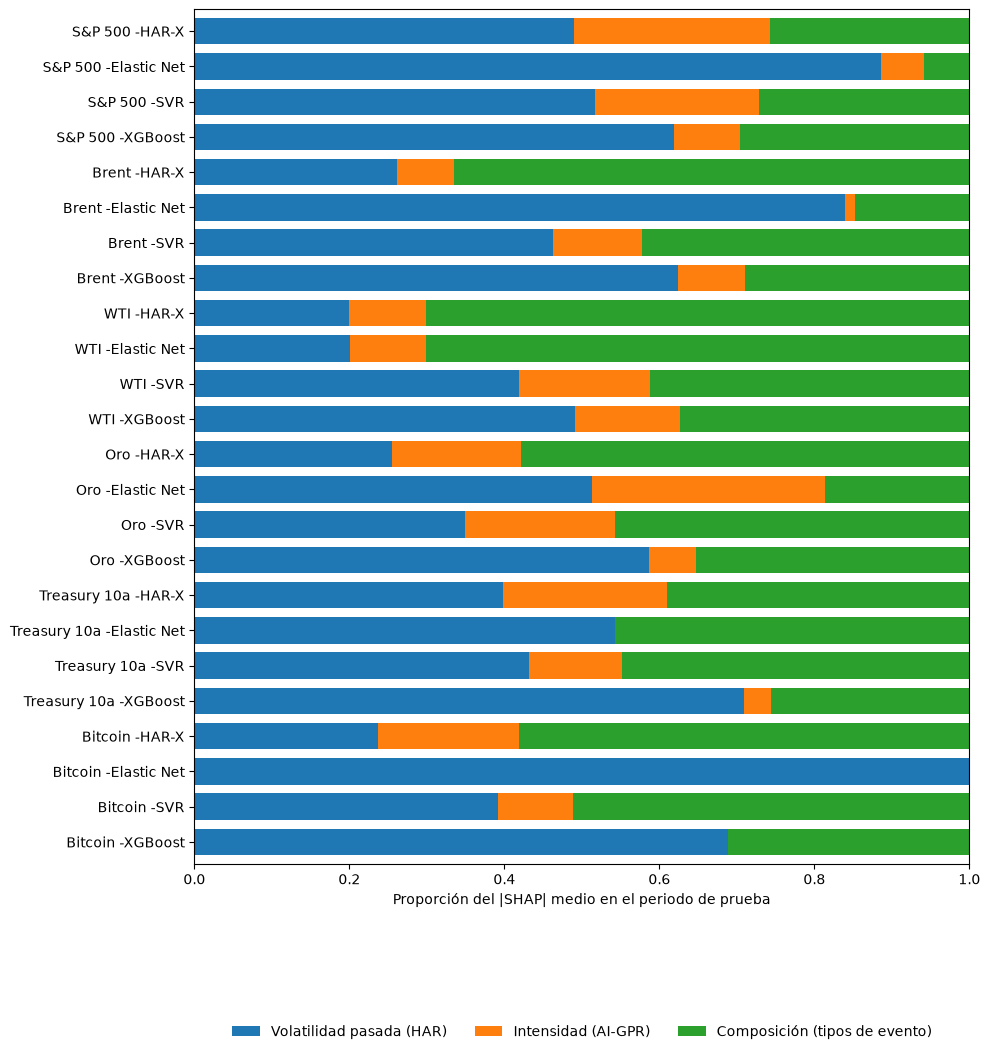

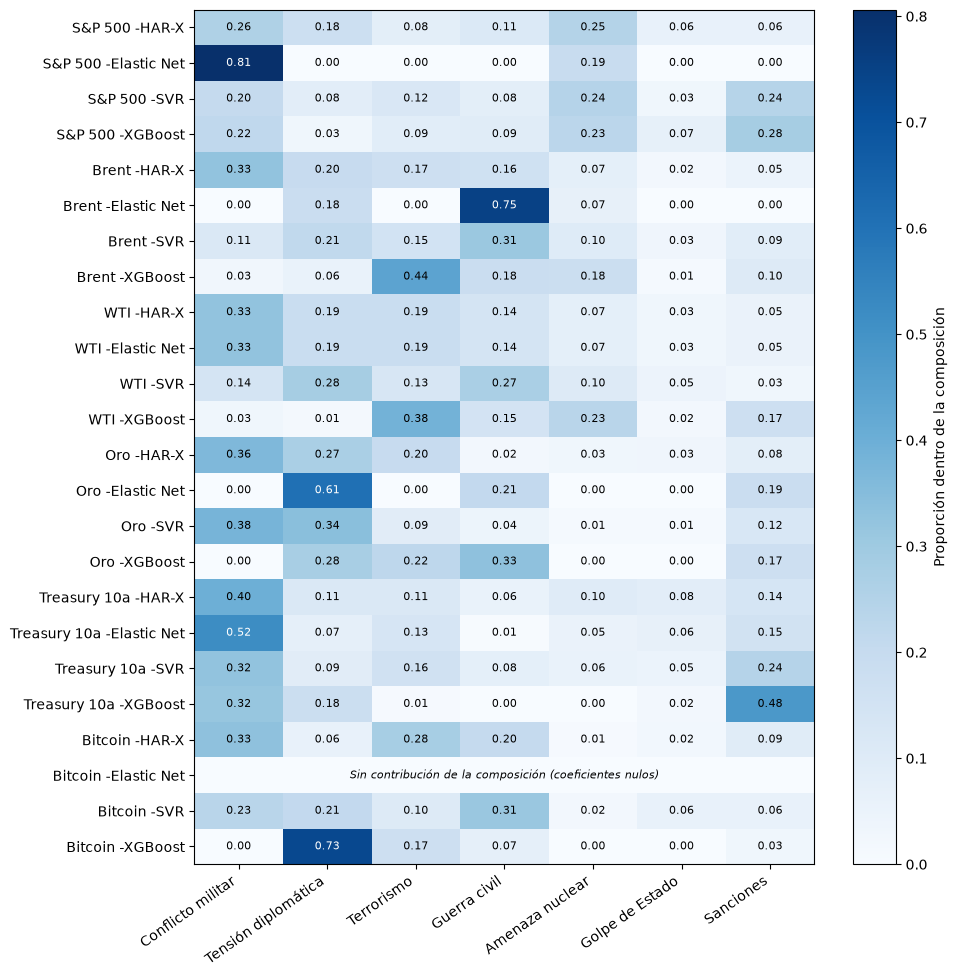

In [74]:
# %% Modelado -23- Gráficos de SHAP
NOMBRE_CASO = {"sp500_m": "S&P 500", "oil_brent_m": "Brent", "oil_wti_m": "WTI",
               "gold_xauusd_m": "Oro", "us10y_m": "Treasury 10a", "btc_m": "Bitcoin"}
NOMBRE_EST = {"lineal": "HAR-X", "enet": "Elastic Net", "svr": "SVR", "xgboost": "XGBoost"}
NOMBRE_TIPO = {"military_conflict": "Conflicto militar", "diplomatic_tension": "Tensión diplomática",
               "terrorism": "Terrorismo", "civil_war": "Guerra civil", "nuclear_threat": "Amenaza nuclear",
               "coup": "Golpe de Estado", "sanctions": "Sanciones"}

# Todos los casos y modelos, incluidos el WTI y los modelos con todos los coeficientes nulos
t = tabla_shap.copy()
t["etiqueta"] = t["caso"].map(NOMBRE_CASO) + " -" + t["estimador"].map(NOMBRE_EST)
t = t.set_index("etiqueta")

# 1. Peso de cada bloque de variables
bloques = t[["bloque_HAR", "bloque_intensidad", "bloque_composicion"]]
nulos = bloques.sum(axis=1) == 0                                             # modelos con todos los coeficientes nulos
bloques = bloques.div(bloques.sum(axis=1), axis=0).fillna(0)
ax = bloques.rename(columns={"bloque_HAR": "Volatilidad pasada (HAR)", "bloque_intensidad": "Intensidad (AI-GPR)",
                             "bloque_composicion": "Composición (tipos de evento)"}).plot.barh(stacked=True, figsize=(10, 0.4 * len(bloques) + 1.5), width=0.75)
for i, es_nulo in enumerate(nulos):
    if es_nulo:
        ax.text(0.01, i, "Todos los coeficientes nulos: predicción constante", va="center", fontsize=8, style="italic")
ax.set_xlabel("Proporción del |SHAP| medio en el periodo de prueba"); ax.set_ylabel(""); ax.set_xlim(0, 1)
ax.invert_yaxis(); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
ax.figure.savefig("figuras/shap_bloques.png", dpi=200, bbox_inches="tight")

# 2. Peso de cada tipo de evento dentro de la composición (cada fila suma 1; filas en blanco: sin contribución)
tipos = t[[f"shap_{k}" for k in NOMBRE_TIPO]]
sin_comp = tipos.sum(axis=1) == 0                                            # la composición no contribuye
tipos = tipos.div(tipos.sum(axis=1), axis=0).fillna(0)
tipos.columns = list(NOMBRE_TIPO.values())
fig, ax = plt.subplots(figsize=(10, 0.4 * len(tipos) + 1.5))
im = ax.imshow(tipos.values, cmap="Blues", vmin=0, vmax=tipos.values.max(), aspect="auto")
ax.set_xticks(range(tipos.shape[1])); ax.set_xticklabels(tipos.columns, rotation=35, ha="right")
ax.set_yticks(range(tipos.shape[0])); ax.set_yticklabels(tipos.index)
for i in range(tipos.shape[0]):
    if sin_comp.iloc[i]:
        ax.text((tipos.shape[1] - 1) / 2, i, "Sin contribución de la composición (coeficientes nulos)",
                ha="center", va="center", fontsize=8, style="italic")
        continue
    for j in range(tipos.shape[1]):
        v = tipos.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * tipos.values.max() else "black")
fig.colorbar(im, ax=ax, label="Proporción dentro de la composición")
fig.savefig("figuras/shap_tipos_evento.png", dpi=200, bbox_inches="tight")

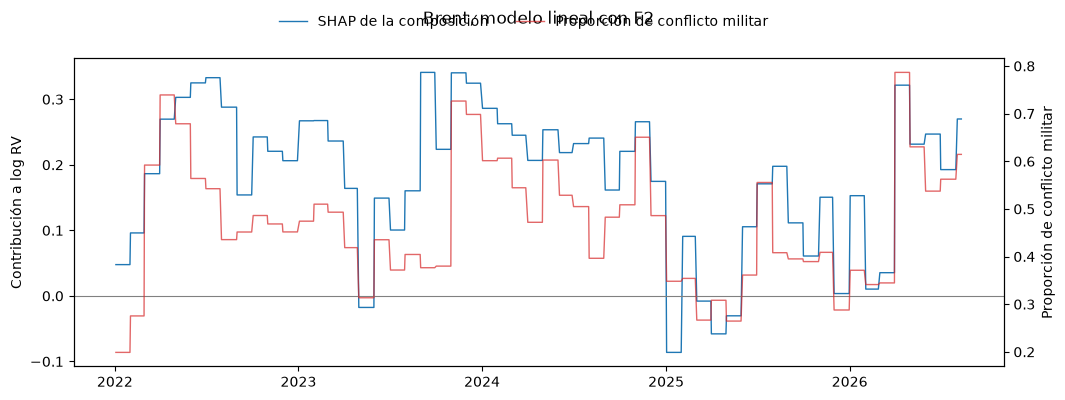

In [75]:
# %% Modelado -24- Contribución de la composición a lo largo del periodo de prueba (un caso)
def grafico_shap_tiempo(shap_df, mat, titulo="", archivo=None):
    """Suma diaria de los SHAP de la composición frente a la proporción de conflicto militar."""
    te = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    te = te[te["periodo"] == "prueba"].loc[shap_df.index]
    comp = shap_df[BLOQUE_COMPOSICION].sum(axis=1).values
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(te["date"], comp, lw=1, label="SHAP de la composición")
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("Contribución a log RV")
    ax2 = ax.twinx()
    ax2.plot(te["date"], te["s_military_conflict"], color="tab:red", lw=1, alpha=0.7, label="Proporción de conflicto militar")
    ax2.set_ylabel("Proporción de conflicto militar")
    fig.legend(loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False); ax.set_title(titulo, pad=25)
    if archivo:
        fig.savefig(archivo, dpi=200, bbox_inches="tight")
    return fig


grafico_shap_tiempo(shap_oil_brent_l, mat_oil_brent, titulo="Brent, modelo lineal con F2",
                    archivo="figuras/shap_tiempo_brent.png");

C:\Users\EinKiGa\AppData\Local\Temp\ipykernel_50396\4146685508.py:15: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(9, 7))


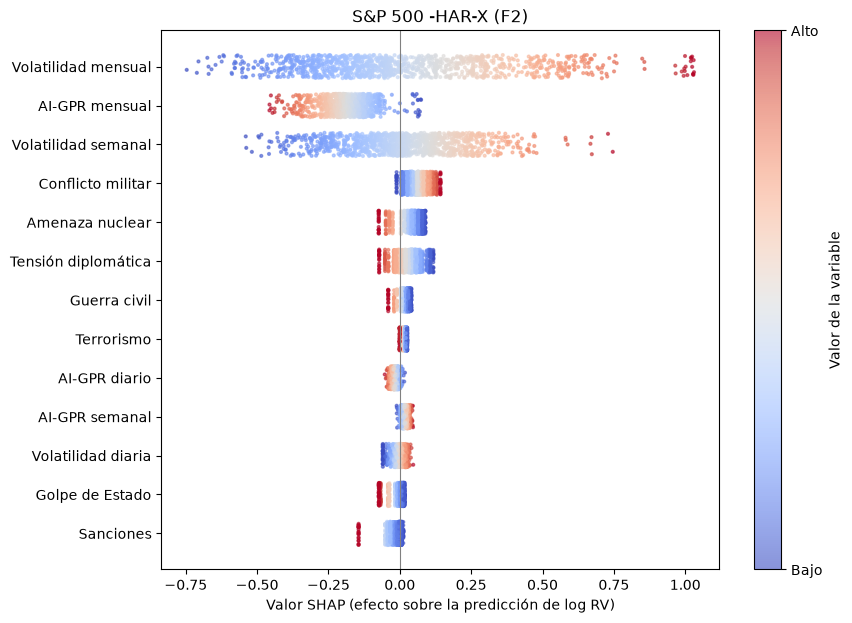

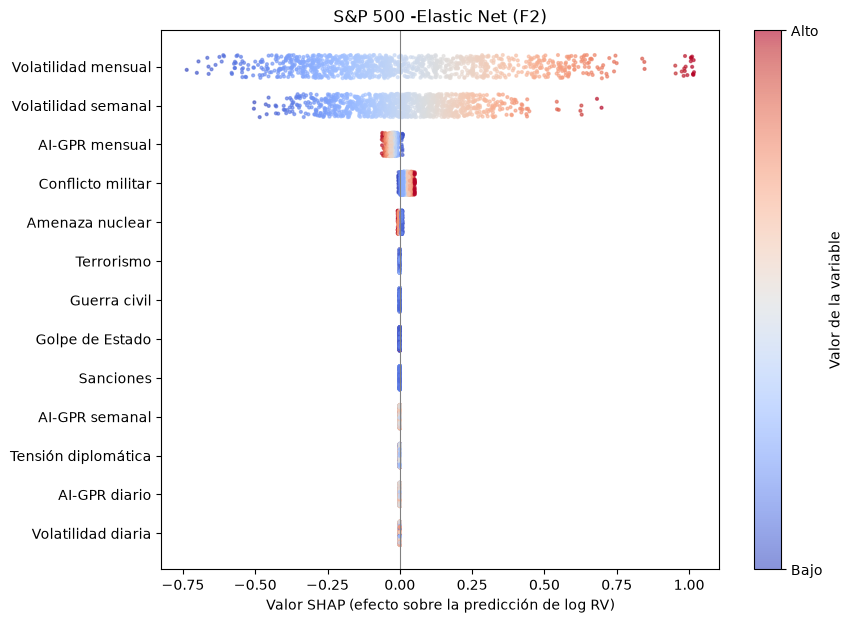

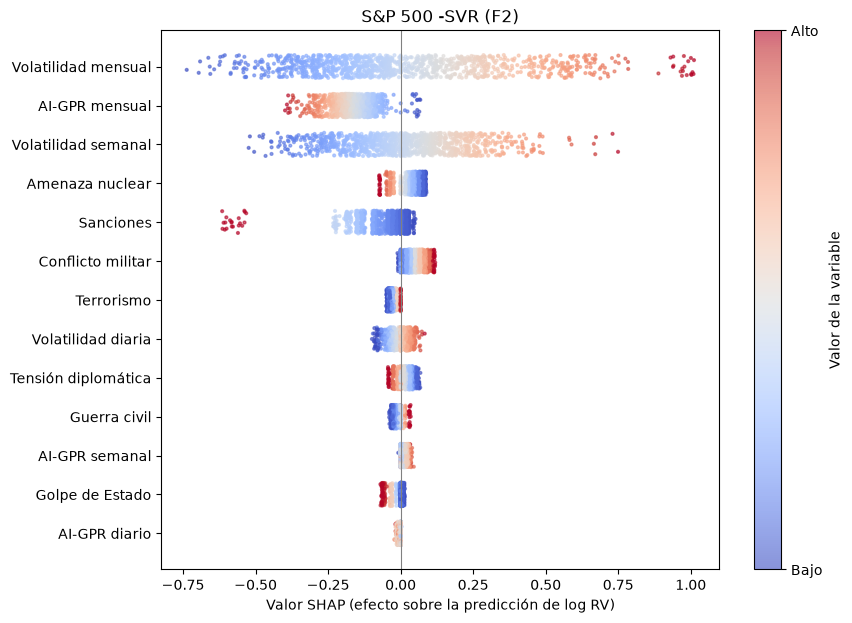

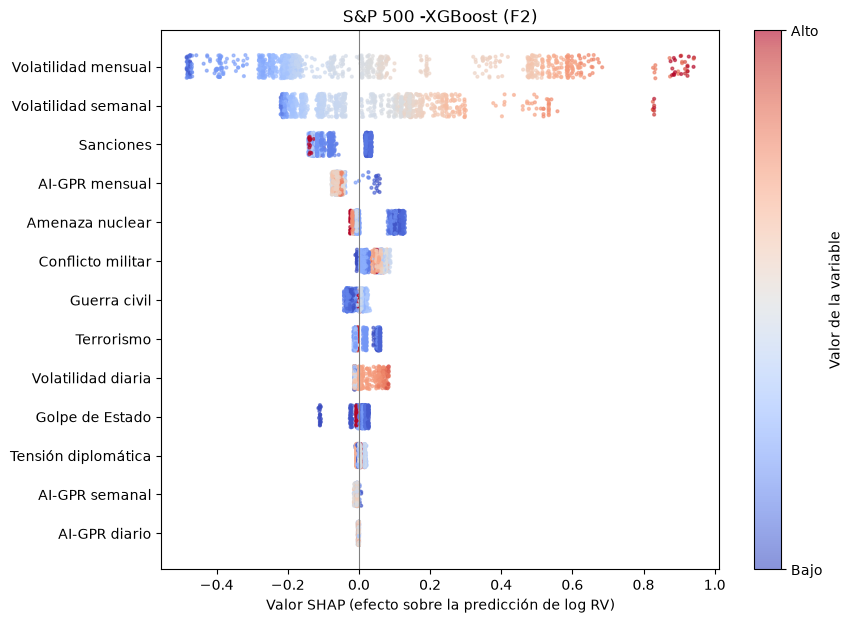

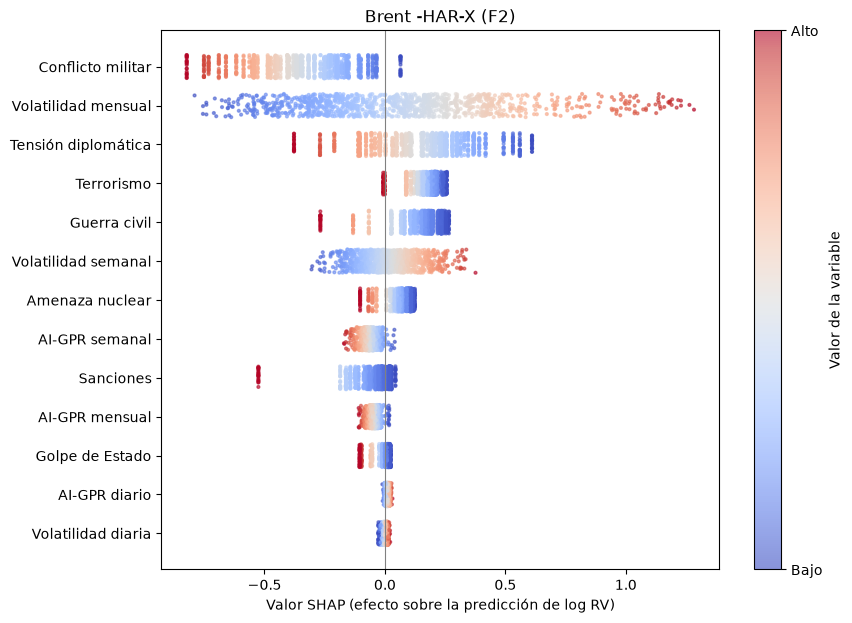

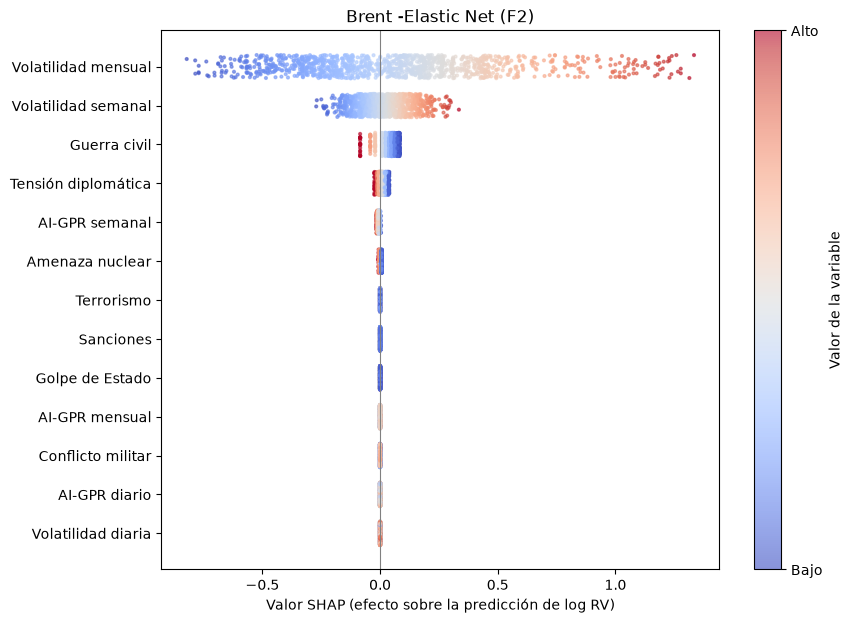

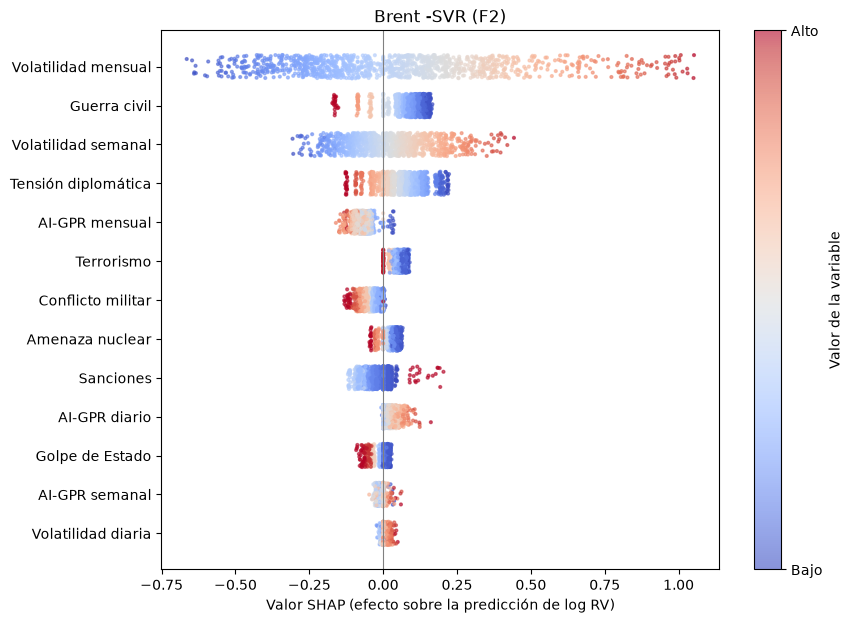

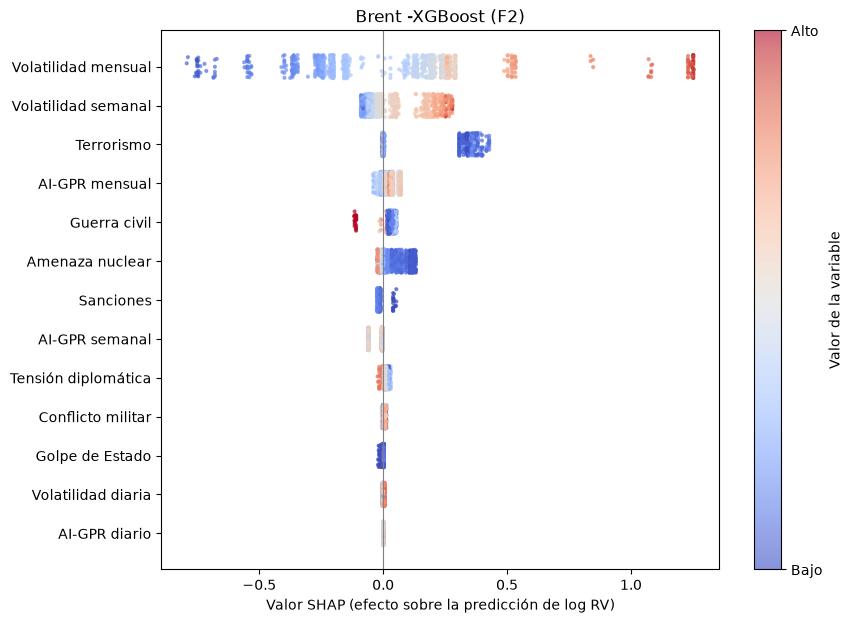

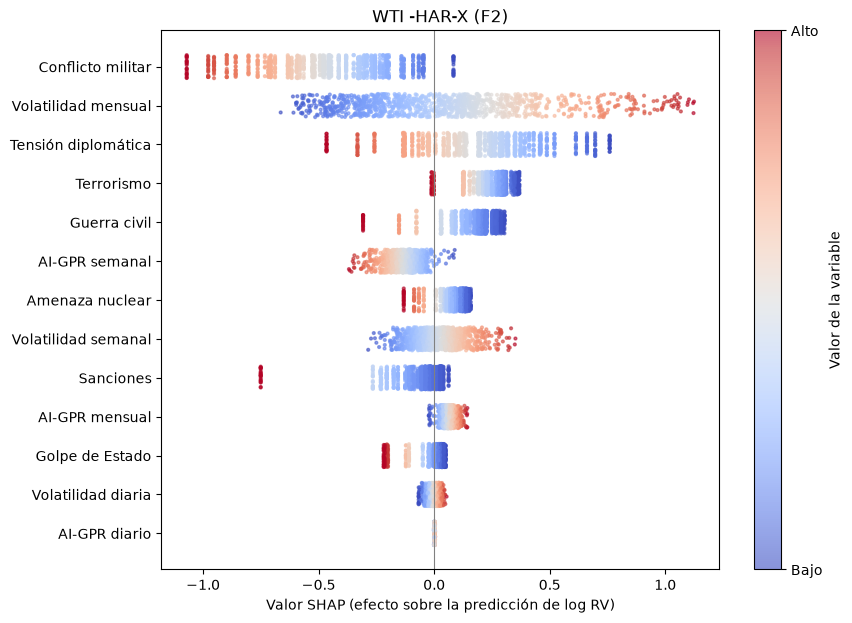

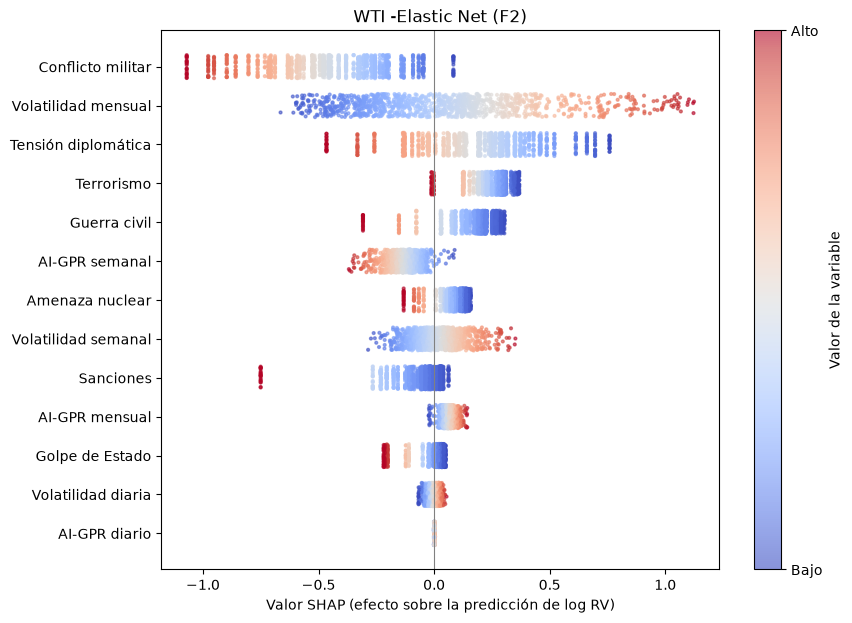

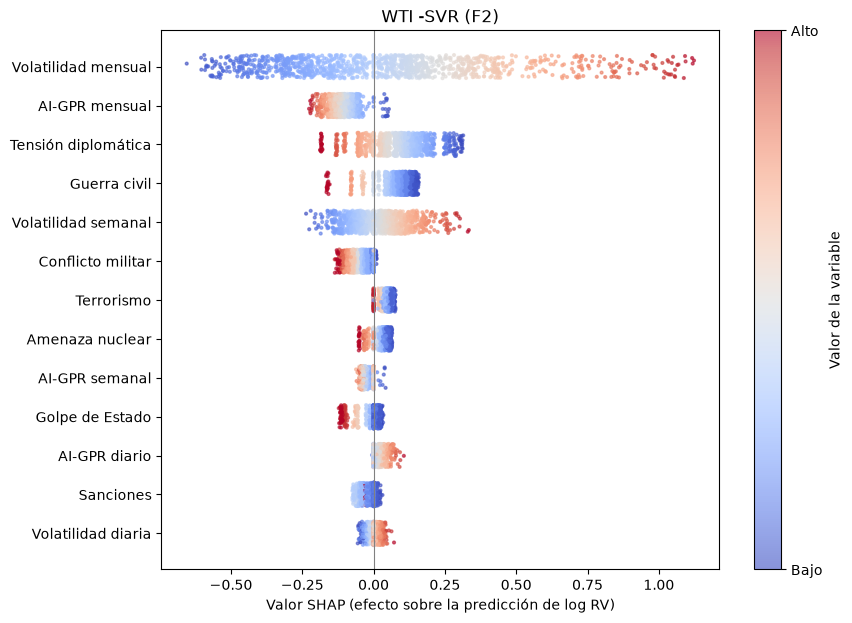

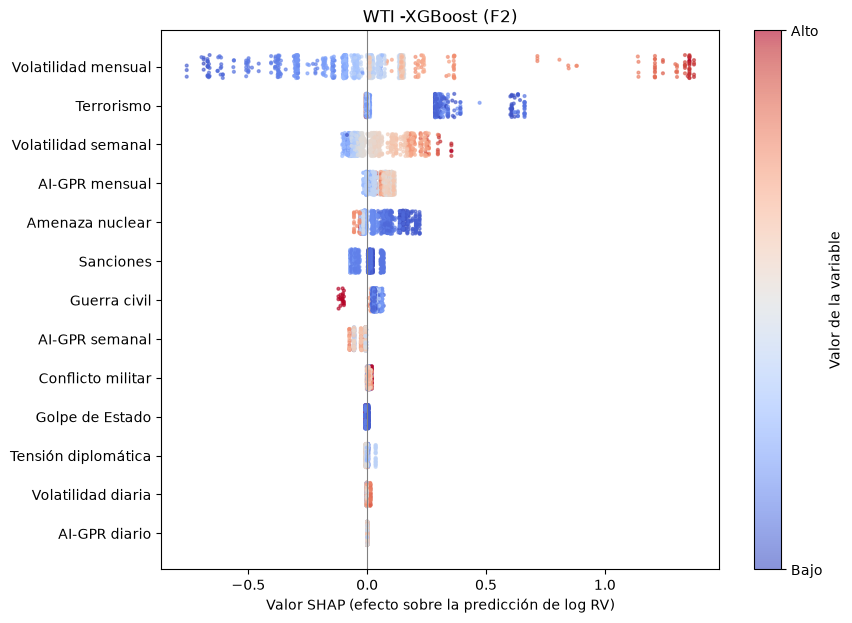

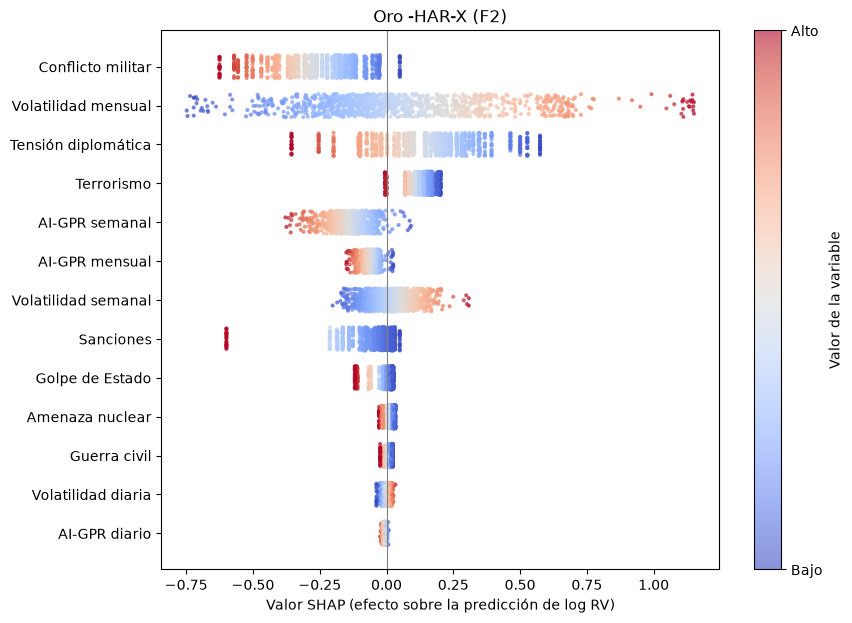

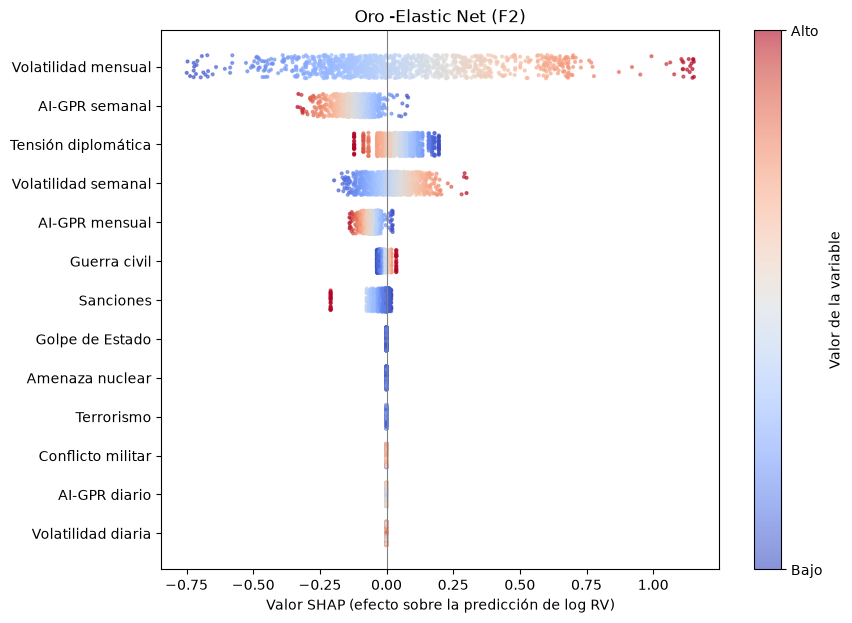

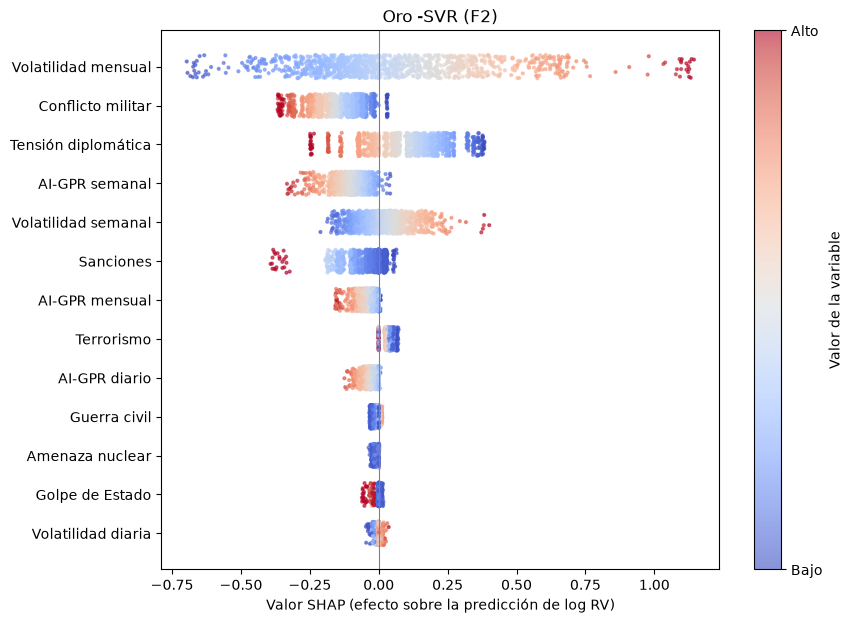

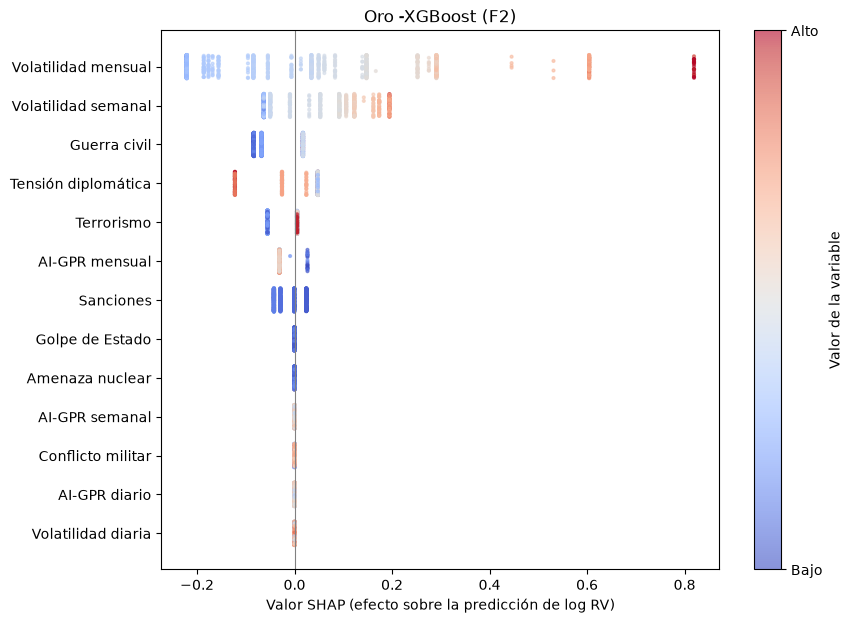

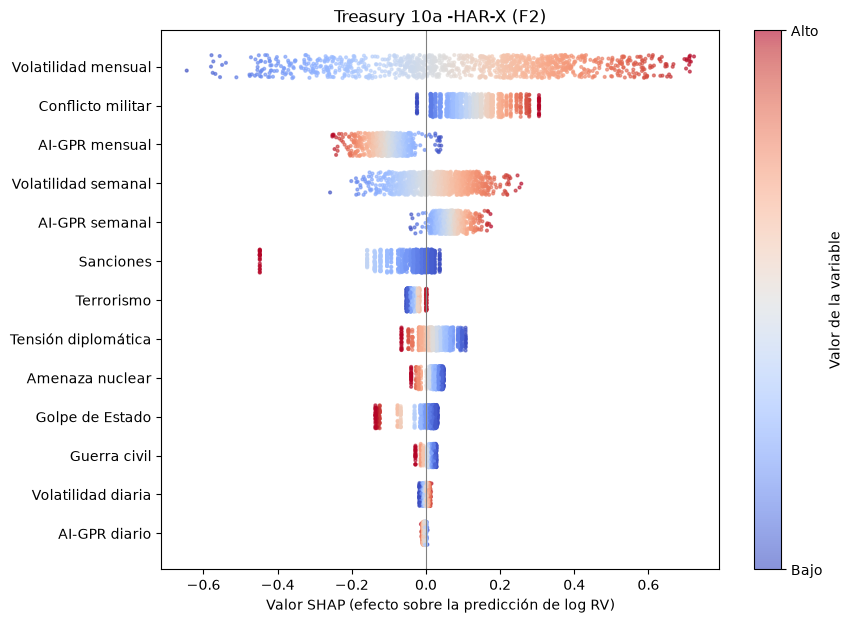

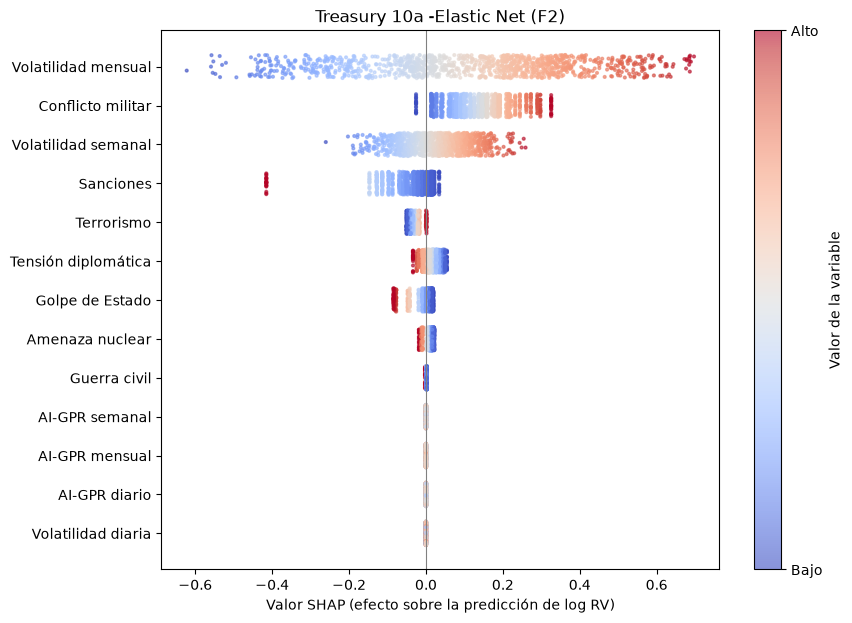

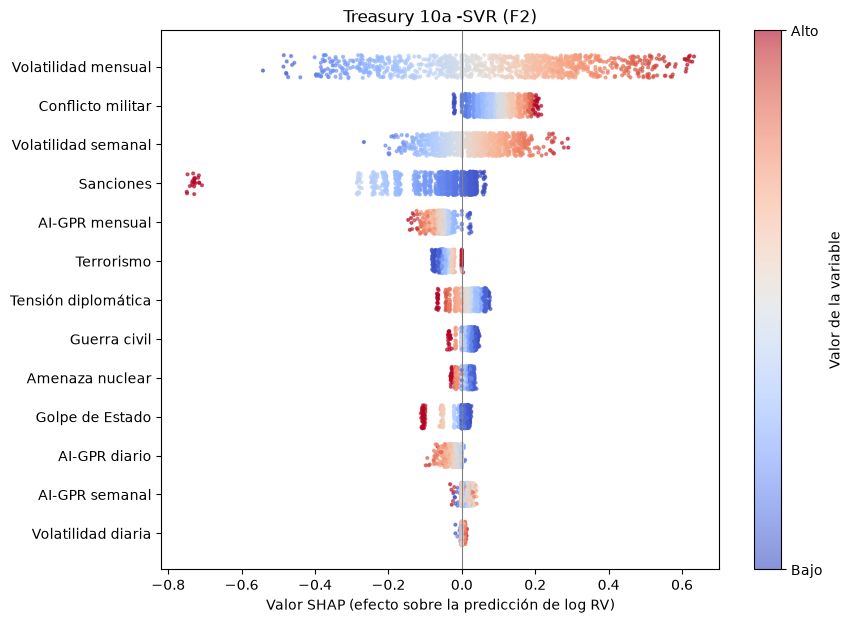

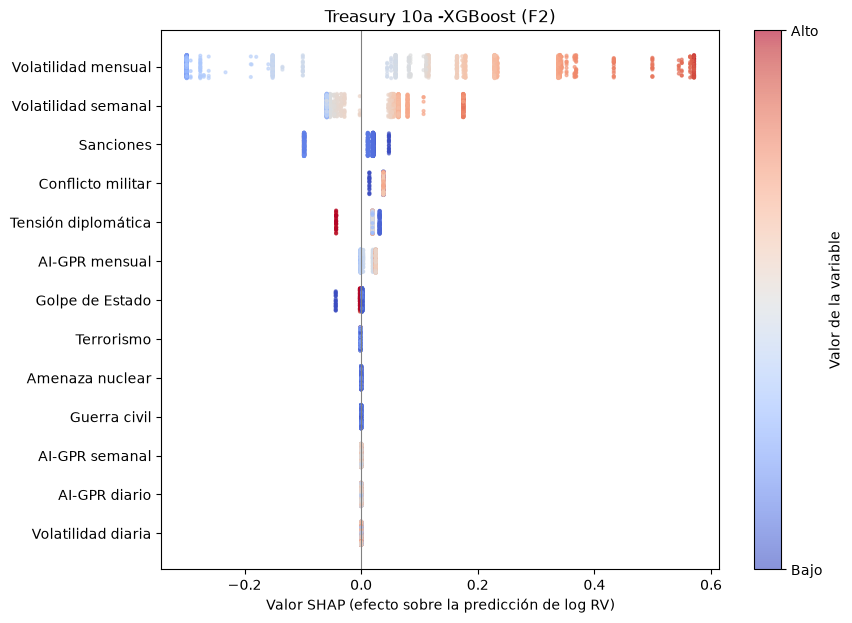

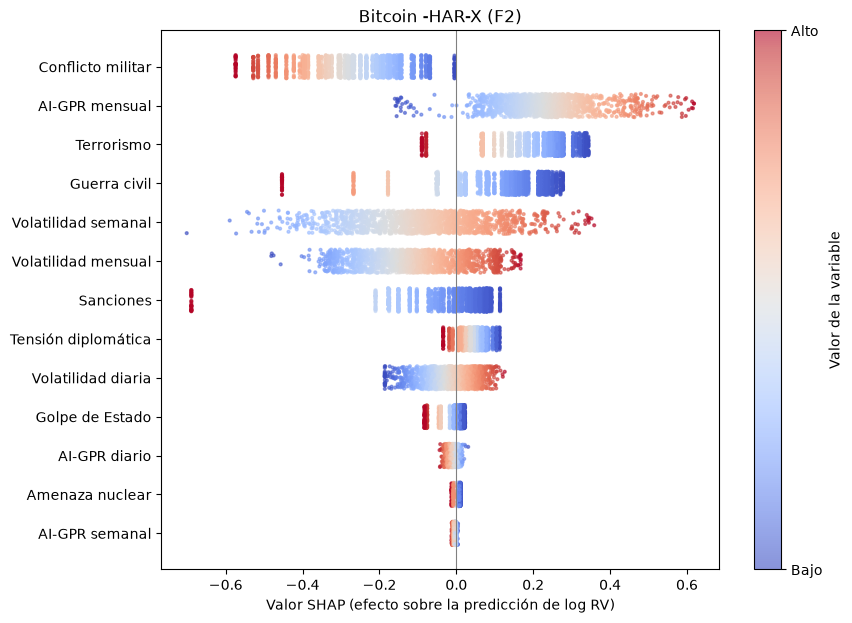

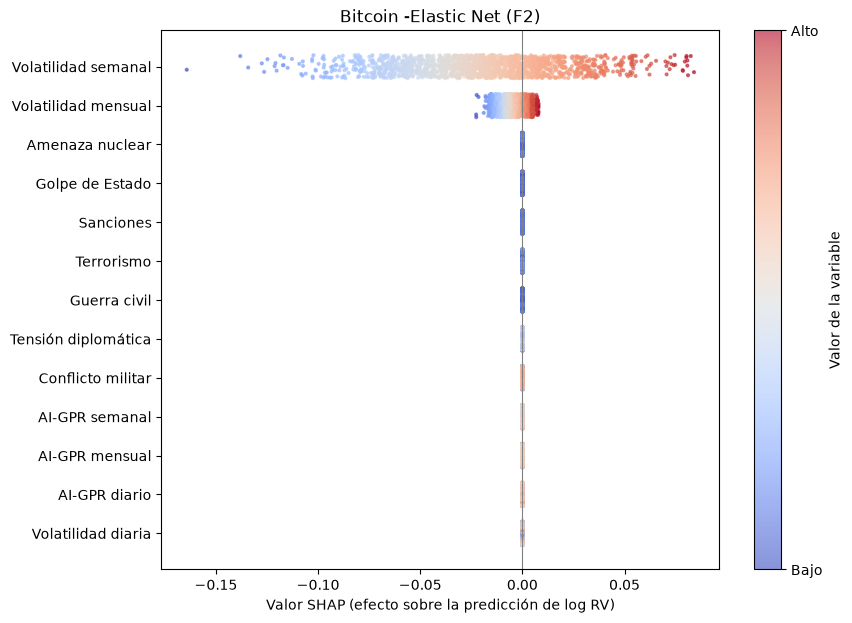

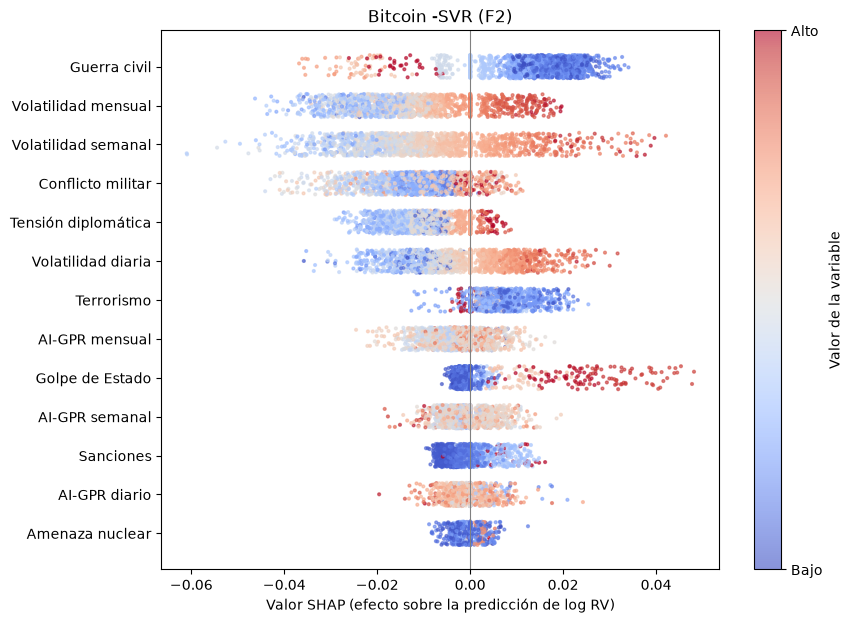

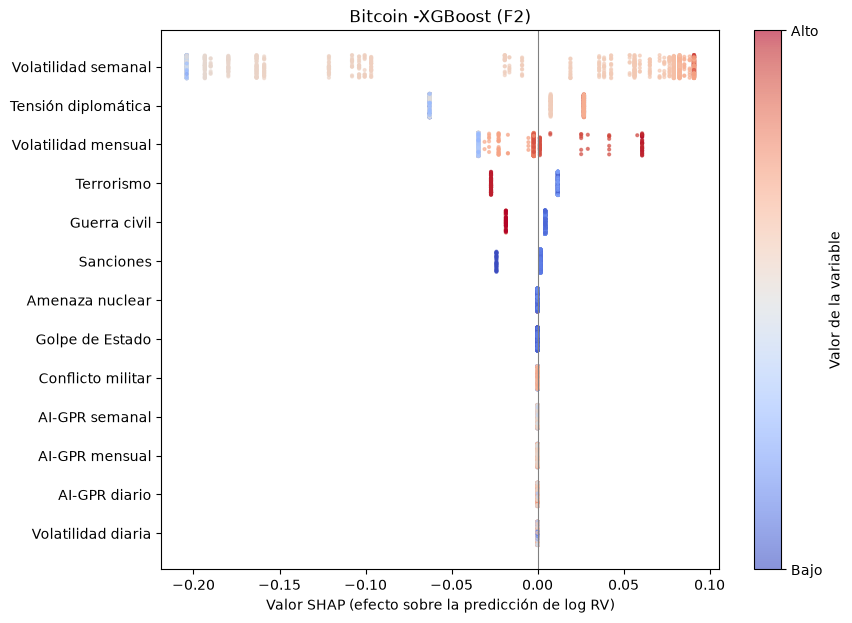

In [76]:
# %% Modelado -25- Resumen SHAP por variable: magnitud, signo y dirección
ETIQUETA_VAR = {"rv_d": "Volatilidad diaria", "rv_w": "Volatilidad semanal", "rv_m": "Volatilidad mensual",
                "gpr_d": "AI-GPR diario", "gpr_w": "AI-GPR semanal", "gpr_m": "AI-GPR mensual",
                **{f"s_{k}": v for k, v in NOMBRE_TIPO.items()}}


def grafico_resumen_shap(shap_df, mat, titulo="", archivo=None):
    """Un punto por día del periodo de prueba y variable. Posición: valor SHAP (efecto sobre la
    predicción de log RV). Color: valor de la variable ese día (azul, bajo; rojo, alto).
    Variables ordenadas por |SHAP| medio, de mayor a menor."""
    te = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    te = te[te["periodo"] == "prueba"].loc[shap_df.index]               # el SVR usa una muestra de días
    orden = shap_df.abs().mean().sort_values().index
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(9, 7))
    for i, v in enumerate(orden):
        x = te[v].values
        color = (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else np.full(len(x), 0.5)
        sc = ax.scatter(shap_df[v].values, i + rng.uniform(-0.3, 0.3, len(x)), c=color,
                        cmap="coolwarm", vmin=0, vmax=1, s=4, alpha=0.6)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_yticks(range(len(orden))); ax.set_yticklabels([ETIQUETA_VAR[v] for v in orden])
    ax.set_xlabel("Valor SHAP (efecto sobre la predicción de log RV)"); ax.set_title(titulo)
    cb = fig.colorbar(sc, ax=ax, ticks=[0, 1]); cb.ax.set_yticklabels(["Bajo", "Alto"]); cb.set_label("Valor de la variable")
    if archivo:
        fig.savefig(archivo, dpi=200, bbox_inches="tight")
    return fig


grafico_resumen_shap(shap_sp500_l, mat_sp500, "S&P 500 -HAR-X (F2)", "figuras/shap_resumen_sp500_l.png");
grafico_resumen_shap(shap_sp500_e, mat_sp500, "S&P 500 -Elastic Net (F2)", "figuras/shap_resumen_sp500_e.png");
grafico_resumen_shap(shap_sp500_s, mat_sp500, "S&P 500 -SVR (F2)", "figuras/shap_resumen_sp500_s.png");
grafico_resumen_shap(shap_sp500_x, mat_sp500, "S&P 500 -XGBoost (F2)", "figuras/shap_resumen_sp500_x.png");
grafico_resumen_shap(shap_oil_brent_l, mat_oil_brent, "Brent -HAR-X (F2)", "figuras/shap_resumen_oil_brent_l.png");
grafico_resumen_shap(shap_oil_brent_e, mat_oil_brent, "Brent -Elastic Net (F2)", "figuras/shap_resumen_oil_brent_e.png");
grafico_resumen_shap(shap_oil_brent_s, mat_oil_brent, "Brent -SVR (F2)", "figuras/shap_resumen_oil_brent_s.png");
grafico_resumen_shap(shap_oil_brent_x, mat_oil_brent, "Brent -XGBoost (F2)", "figuras/shap_resumen_oil_brent_x.png");
grafico_resumen_shap(shap_oil_wti_l, mat_oil_wti, "WTI -HAR-X (F2)", "figuras/shap_resumen_oil_wti_l.png");
grafico_resumen_shap(shap_oil_wti_e, mat_oil_wti, "WTI -Elastic Net (F2)", "figuras/shap_resumen_oil_wti_e.png");
grafico_resumen_shap(shap_oil_wti_s, mat_oil_wti, "WTI -SVR (F2)", "figuras/shap_resumen_oil_wti_s.png");
grafico_resumen_shap(shap_oil_wti_x, mat_oil_wti, "WTI -XGBoost (F2)", "figuras/shap_resumen_oil_wti_x.png");
grafico_resumen_shap(shap_gold_xauusd_l, mat_gold_xauusd, "Oro -HAR-X (F2)", "figuras/shap_resumen_gold_xauusd_l.png");
grafico_resumen_shap(shap_gold_xauusd_e, mat_gold_xauusd, "Oro -Elastic Net (F2)", "figuras/shap_resumen_gold_xauusd_e.png");
grafico_resumen_shap(shap_gold_xauusd_s, mat_gold_xauusd, "Oro -SVR (F2)", "figuras/shap_resumen_gold_xauusd_s.png");
grafico_resumen_shap(shap_gold_xauusd_x, mat_gold_xauusd, "Oro -XGBoost (F2)", "figuras/shap_resumen_gold_xauusd_x.png");
grafico_resumen_shap(shap_us10y_l, mat_us10y, "Treasury 10a -HAR-X (F2)", "figuras/shap_resumen_us10y_l.png");
grafico_resumen_shap(shap_us10y_e, mat_us10y, "Treasury 10a -Elastic Net (F2)", "figuras/shap_resumen_us10y_e.png");
grafico_resumen_shap(shap_us10y_s, mat_us10y, "Treasury 10a -SVR (F2)", "figuras/shap_resumen_us10y_s.png");
grafico_resumen_shap(shap_us10y_x, mat_us10y, "Treasury 10a -XGBoost (F2)", "figuras/shap_resumen_us10y_x.png");
grafico_resumen_shap(shap_btc_l, mat_btc, "Bitcoin -HAR-X (F2)", "figuras/shap_resumen_btc_l.png");
grafico_resumen_shap(shap_btc_e, mat_btc, "Bitcoin -Elastic Net (F2)", "figuras/shap_resumen_btc_e.png");
grafico_resumen_shap(shap_btc_s, mat_btc, "Bitcoin -SVR (F2)", "figuras/shap_resumen_btc_s.png");
grafico_resumen_shap(shap_btc_x, mat_btc, "Bitcoin -XGBoost (F2)", "figuras/shap_resumen_btc_x.png");

In [77]:
# %% Modelado -26- Gráfico de dependencia: valor real de la variable frente a su SHAP
def grafico_dependencia(shap_df, mat, variable, titulo="", archivo=None):
    te = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    te = te[te["periodo"] == "prueba"].loc[shap_df.index]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(te[variable], shap_df[variable], s=6, alpha=0.6)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"{ETIQUETA_VAR[variable]} (valor real)"); ax.set_ylabel("Valor SHAP"); ax.set_title(titulo)
    if archivo:
        fig.savefig(archivo, dpi=200, bbox_inches="tight")
    return fig


grafico_dependencia(shap_us10y_l, mat_us10y, "s_military_conflict", "Treasury 10a -HAR-X: conflicto militar");
grafico_dependencia(shap_gold_xauusd_x, mat_gold_xauusd, "s_civil_war", "Oro -XGBoost: guerra civil");
plt.close("all")

In [80]:
# %% Figuras -0- Estilo, constantes y utilidades comunes
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
 
Path("figuras").mkdir(exist_ok=True)
Path("tablas").mkdir(exist_ok=True)
 
mpl.rcParams.update({
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 8, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})
ANCHO = 6.3                                                     # pulgadas, equivalente a \textwidth
 
# Paleta de Okabe-Ito (apta para daltonismo). Un color fijo por conjunto en todas las figuras
COLOR = {"F0": "#4D4D4D", "F1": "#0072B2", "F2": "#E69F00", "RV": "black"}
COLOR_TIPOS = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
 
SERIES = ["sp500", "oil_brent", "oil_wti", "gold_xauusd", "us10y", "btc"]
NOMBRE_SERIE = {"sp500": "S&P 500", "oil_brent": "Brent", "oil_wti": "WTI", "gold_xauusd": "Oro",
                "us10y": "Bono del Tesoro", "btc": "Bitcoin"}
ESTIMADORES = ["lineal", "enet", "svr", "xgboost"]
NOMBRE_ESTIM = {"lineal": "HAR", "enet": "Elastic Net", "svr": "SVR", "xgboost": "XGBoost"}
NOMBRE_HORIZ = {"m": "mensual", "w": "semanal"}
NOMBRE_TIPO_ES = {"military_conflict": "Conflicto militar", "diplomatic_tension": "Tensión diplomática",
                  "terrorism": "Terrorismo", "civil_war": "Guerra civil", "nuclear_threat": "Amenaza nuclear",
                  "coup": "Golpe de Estado", "sanctions": "Sanciones"}
CASOS_12 = [f"{s}_{h}" for s in SERIES for h in ("m", "w")]
 
# Fechas de episodios: una sola constante por episodio para todas las figuras.
# VERIFICAR las dos marcadas antes de la entrega: el texto solo dice "junio de 2025" y "finales de febrero de 2026".
EP_UCRANIA = pd.Timestamp("2022-02-24")
EP_ISRAEL_IRAN = pd.Timestamp("2025-06-13")                     # VERIFICAR
EP_GUERRA_IRAN = pd.Timestamp("2026-02-28")                     # VERIFICAR
EP_COMUNES = {"Ucrania": EP_UCRANIA, "Israel e Irán": EP_ISRAEL_IRAN, "Guerra contra Irán": EP_GUERRA_IRAN}
EP_MES = {"may. 2022": pd.Timestamp("2022-05-01"), "abr. 2025": pd.Timestamp("2025-04-01"),
          "ene. 2026": pd.Timestamp("2026-01-01")}               # episodios definidos solo por mes
 
 
def serie_horizonte(caso):
    s, h = caso.rsplit("_", 1)
    return s, h
 
 
def rotulo(caso, est=None):
    """Formato 'Serie · horizonte · estimador'."""
    s, h = serie_horizonte(caso)
    partes = [NOMBRE_SERIE[s], NOMBRE_HORIZ[h]] + ([NOMBRE_ESTIM[est]] if est else [])
    return " · ".join(partes)
 
 
def h_caso(caso):
    s, h = serie_horizonte(caso)
    return {("btc", "m"): 30, ("btc", "w"): 7}.get((s, h), 22 if h == "m" else 5)
 
 
PRED = {c: globals()[f"pred_{c}"] for c in CASOS_12}
MEJ = {c: globals()[f"mej_{c}"] for c in CASOS_12}
MAT = {s: globals()[f"mat_{s}"] for s in SERIES}
DF_LIMPIO = {s: globals()[f"df_{s}_limpio"] for s in SERIES}
 
 
def marcar_episodios(ax, eventos, rotular=True):
    for nombre, f in eventos.items():
        ax.axvline(f, color="gray", ls="--", lw=0.8, zorder=1)
        if rotular:
            ax.annotate(nombre, (f, 1), xycoords=("data", "axes fraction"), xytext=(2, -2),
                        textcoords="offset points", rotation=90, va="top", ha="left", color="gray", fontsize=8)
 
 
def sombrear_prueba(ax, fin):
    ax.axvspan(INICIO_PRUEBA, fin, color="0.92", zorder=0, lw=0)
 
 
def guardar(fig, nombre):
    fig.savefig(f"figuras/{nombre}.png", dpi=300)
    plt.close(fig)
 
 
# QLIKE y diferencia acumulada (misma definición que contribucion_mensual)
def qlike_serie(pred, conj, est):
    p = pred[(pred["conjunto"] == conj) & (pred["estimador"] == est)].set_index("date")
    y, f = np.exp(p["y"]), np.exp(p["pred"] + p["sigma2"] / 2)
    return y / f - np.log(y / f) - 1
 
 
def dif_acumulada(pred, est, base="F0", alt="F1"):
    return (qlike_serie(pred, base, est) - qlike_serie(pred, alt, est)).dropna().cumsum()
 
 
def panel_acumulada(ax, dif, color=None, eventos=None, rotular=False):
    ax.plot(dif.index, dif.values, color=color or COLOR["F1"], lw=1)
    ax.axhline(0, color="black", lw=0.6, zorder=1)
    if eventos:
        marcar_episodios(ax, eventos, rotular)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


In [81]:
# %% Modelado -27- Cálculo de SHAP con F1 (12 modelos principales y secundarios con mejora)
def shap_caso_f1(caso, estimador):
    """Igual que shap_caso, pero con F1 y con el objetivo del horizonte del caso (y_m o y_w)."""
    s, hz = serie_horizonte(caso)
    h, y_col = h_caso(caso), f"y_{hz}"
    m = MAT[s].dropna(subset=[y_col]).reset_index(drop=True)
    tr = m[m["periodo"] == "entrenamiento"].iloc[:-h]
    te = m[m["periodo"] == "prueba"]
    params = MEJ[caso].query("conjunto == 'F1' and estimador == @estimador")["params"].iloc[0]
    est = construir_estimador(estimador, params).fit(tr[F1], tr[y_col])
    if estimador == "xgboost":
        sh = shap_xgboost(est, te[F1])
    elif estimador == "svr":
        sh = shap_svr(est, tr[F1], te[F1])
    else:
        sh = shap_lineal(est, tr[F1], te[F1])
    imp = sh.abs().mean()
    fila = {"caso": caso, "estimador": estimador, "bloque_HAR": imp[F0].sum(), "bloque_intensidad": imp[BLOQUE_INTENSIDAD].sum()}
    return fila, sh, te
 
 
secundarios = resumen[(resumen["cw_F1vsF0_p"] < 0.05) & (resumen["qlike_F1"] < resumen["qlike_F0"]) & (~resumen["principal"])]
MODELOS_F1 = [(c, PRINCIPAL[c]) for c in CASOS_12] + list(secundarios[["caso", "estimador"]].itertuples(index=False, name=None))
if ("btc_m", "svr") not in MODELOS_F1:
    MODELOS_F1.append(("btc_m", "svr"))               
print(f"{len(MODELOS_F1)} modelos con F1 ({len(secundarios)} secundarios con mejora; la memoria anuncia 5)")
 
filas_f1, shap_f1, te_f1 = [], {}, {}
for caso, est in MODELOS_F1:
    fila, sh, te = shap_caso_f1(caso, est)
    filas_f1.append(fila); shap_f1[(caso, est)] = sh; te_f1[(caso, est)] = te
    print(datetime.now().strftime("%H:%M:%S"), "F1", caso, est, len(sh))
    if est == "svr":
        sh.to_pickle(f"resultados/shap_f1_svr_{caso}_{ID_EJECUCION}.pkl")     # cada SVR se guarda al terminar
tabla_shap_f1 = pd.DataFrame(filas_f1)
tabla_shap_f1.to_csv(f"resultados/shap_f1_{ID_EJECUCION}.csv", index=False)
pd.to_pickle(shap_f1, f"resultados/shap_f1_valores_{ID_EJECUCION}.pkl")
display(tabla_shap_f1.assign(prop_intensidad=lambda d: d["bloque_intensidad"] / (d["bloque_HAR"] + d["bloque_intensidad"])).round(3))

17 modelos con F1 (5 secundarios con mejora; la memoria anuncia 5)


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   28.4s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   30.8s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:   44.2s
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:   49.8s
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  1.1min remaining:   41.1s
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  1.3min remaining:   27.5s
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:  1.5min remaining:   15.4s
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:  1.5min remaining:    3.5s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  1.5min finished


15:23:09 F1 sp500_m svr 1154


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    9.3s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   10.6s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:   18.0s
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:   20.4s
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:   29.3s remaining:   17.6s
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:   30.7s remaining:   10.8s
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:   37.3s remaining:    6.5s
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:   38.3s remaining:    1.4s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:   38.6s finished


15:23:49 F1 sp500_w svr 1169
15:23:49 F1 oil_brent_m lineal 1189
15:23:49 F1 oil_brent_w lineal 1203


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   45.0s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   48.9s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  2.4min remaining:  1.5min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  2.5min remaining:   53.8s
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:  3.2min remaining:   33.6s
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:  3.2min remaining:    7.4s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  3.2min finished


... (12 outputs left out)

15:42:21 F1 oil_brent_w svr 1203


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   51.3s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   55.3s
[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done  50 out of  80 | elapsed:  2.7min remaining:  1.6min
[Parallel(n_jobs=-1)]: Done  59 out of  80 | elapsed:  2.9min remaining:  1.0min
[Parallel(n_jobs=-1)]: Done  68 out of  80 | elapsed:  3.7min remaining:   38.9s
[Parallel(n_jobs=-1)]: Done  77 out of  80 | elapsed:  3.8min remaining:    8.7s
[Parallel(n_jobs=-1)]: Done  80 out of  80 | elapsed:  3.8min finished


15:46:09 F1 oil_wti_w svr 1203
15:46:10 F1 oil_wti_w xgboost 1203
15:46:10 F1 btc_m lineal 1684
15:46:10 F1 btc_w lineal 1704


,caso,estimador,bloque_HAR,bloque_intensidad,prop_intensidad
0,sp500_m,svr,0.4620,0.1720,0.2710
1,sp500_w,svr,0.5740,0.1960,0.2540
2,oil_brent_m,lineal,0.4670,0.1660,0.2620
3,oil_brent_w,lineal,0.5230,0.1630,0.2380
4,oil_wti_m,svr,0.4220,0.2030,0.3240
5,oil_wti_w,lineal,0.4840,0.1000,0.1720
6,gold_xauusd_m,svr,0.3770,0.2970,0.4410
7,gold_xauusd_w,svr,0.4300,0.1940,0.3110
8,us10y_m,svr,0.3650,0.2150,0.3710
9,us10y_w,svr,0.4240,0.1310,0.2360


In [82]:
# %% Modelado -27b- Componentes de la intensidad en el SVR de Bitcoin mensual (F1)
# Solo consulta: no modifica objetos anteriores y no forma parte de la huella.
from scipy.stats import spearmanr

sh, te = shap_f1[("btc_m", "svr")], te_f1[("btc_m", "svr")]
comp = ["gpr_d", "gpr_w", "gpr_m"]
abs_medio = sh[comp].abs().mean()
tabla_componentes_btc = pd.DataFrame({
    "abs_shap_medio": abs_medio,
    "proporcion_intensidad": abs_medio / abs_medio.sum(),
    "spearman_valor_shap": [spearmanr(te[c], sh[c]).correlation for c in comp]})
display(tabla_componentes_btc.round(3))

,abs_shap_medio,proporcion_intensidad,spearman_valor_shap
gpr_d,0.0060,0.1710,0.3720
gpr_w,0.0110,0.2940,0.5720
gpr_m,0.0200,0.5350,0.6770


# Robustez

In [83]:
# %% Robustez -1- Utilidades comunes
PRINCIPAL = resumen[resumen["principal"]].set_index("caso")["estimador"].to_dict()
MEJ = {"sp500_m": mej_sp500_m, "sp500_w": mej_sp500_w, "oil_brent_m": mej_oil_brent_m, "oil_brent_w": mej_oil_brent_w,
       "oil_wti_m": mej_oil_wti_m, "oil_wti_w": mej_oil_wti_w, "gold_xauusd_m": mej_gold_xauusd_m,
       "gold_xauusd_w": mej_gold_xauusd_w, "us10y_m": mej_us10y_m, "us10y_w": mej_us10y_w,
       "btc_m": mej_btc_m, "btc_w": mej_btc_w}
 
 
def mej_principal(caso):
    """Hiperparámetros del modelo principal del caso (todas sus filas: F0, F1 y F2)."""
    return MEJ[caso][MEJ[caso]["estimador"] == PRINCIPAL[caso]]
 
 
def qlike_media(pred, conjunto, estimador):
    p = pred[(pred["conjunto"] == conjunto) & (pred["estimador"] == estimador)]
    return qlike_niveles(p["y"].values, p["pred"].values, p["sigma2"].values)
 
 
def resumen_robustez(prueba, caso, pred, h):
    """QLIKE por conjunto y Clark-West del modelo principal en una prueba de robustez."""
    est = PRINCIPAL[caso]
    conj = sorted(pred["conjunto"].unique())
    fila = {"prueba": prueba, "caso": caso, "estimador": est,
            "n_predicciones": int(((pred["conjunto"] == "F0") & (pred["estimador"] == est)).sum())}
    for c in conj:
        fila[f"qlike_{c}"] = qlike_media(pred, c, est)
    fila["cw_F1vsF0_p"] = clark_west(pred, est, "F0", "F1", h)[1]
    if "F2" in conj:
        fila["cw_F2vsF1_p"] = clark_west(pred, est, "F1", "F2", h)[1]
    return fila
 
 
def flujo_variables(df_limpio, tipo, w, m, percentil=0.01, ajuste_variacion=None):
    """Repite el cálculo de variables (variación, volatilidad, AI-GPR y composición) y la matriz.
    ajuste_variacion: {fecha: valor} para sustituir la variación de días concretos."""
    d = agregar_variacion(df_limpio.copy(), tipo=tipo)
    if ajuste_variacion:
        for fecha, valor in ajuste_variacion.items():
            d.loc[d["date"] == pd.Timestamp(fecha), "variacion"] = valor
    d = agregar_volatilidad(d, horizontes=(w, m), percentil=percentil)
    d = agregar_gpr_intensidad(d, df_gpr_daily, horizontes=(w, m))
    d = agregar_gpr_composicion(d, df_gpr_eventtype)
    return construir_matriz(d, w, m)
 
 
CONJ_M = {"F0": F0, "F1": F1, "F2": F2}
CONJ_W = {"F0": F0, "F1": F1}
filas_robustez = []

In [84]:
# %% Robustez -2- Prueba 1: agrupación por semana y mes de calendario (sin solapamiento)
def matriz_calendario(df_f2, mat, freq):
    """Una fila por periodo de calendario: variables del último día del periodo anterior y,
    como objetivo, el logaritmo de la volatilidad media del periodo (sin ventanas solapadas)."""
    rv = df_f2.set_index("date")["rv"].dropna().sort_index()
    grupos = rv.resample(freq)
    tabla = pd.DataFrame({"y": np.log(grupos.mean()),
                          "fin_ultimo_dia": grupos.apply(lambda s: s.index.max() if len(s) else pd.NaT)})
    tabla = tabla[tabla.index <= rv.index.max()]                              # quita el periodo incompleto
    tabla["date"] = tabla["fin_ultimo_dia"].shift(1)                          # origen: último día del periodo anterior
    tabla = tabla.dropna(subset=["date", "y"]).rename_axis("fin_periodo").reset_index()
    x = mat.set_index("date")[F2]
    tabla = tabla.join(x, on="date", how="inner")
    tabla["periodo"] = np.where(tabla["fin_periodo"] >= INICIO_PRUEBA, "prueba", "entrenamiento")
    return tabla[["date", "fin_periodo", *F2, "y", "periodo"]].reset_index(drop=True)


cal_sp500_m = matriz_calendario(df_sp500_f2, mat_sp500, "ME");             cal_sp500_w = matriz_calendario(df_sp500_f2, mat_sp500, "W-FRI")
cal_brent_m = matriz_calendario(df_oil_brent_f2, mat_oil_brent, "ME");     cal_brent_w = matriz_calendario(df_oil_brent_f2, mat_oil_brent, "W-FRI")
cal_wti_m   = matriz_calendario(df_oil_wti_f2, mat_oil_wti, "ME");         cal_wti_w   = matriz_calendario(df_oil_wti_f2, mat_oil_wti, "W-FRI")
cal_oro_m   = matriz_calendario(df_gold_xauusd_f2, mat_gold_xauusd, "ME"); cal_oro_w   = matriz_calendario(df_gold_xauusd_f2, mat_gold_xauusd, "W-FRI")
cal_us10y_m = matriz_calendario(df_us10y_f2, mat_us10y, "ME");             cal_us10y_w = matriz_calendario(df_us10y_f2, mat_us10y, "W-FRI")
cal_btc_m   = matriz_calendario(df_btc_f2, mat_btc, "ME");                 cal_btc_w   = matriz_calendario(df_btc_f2, mat_btc, "W-FRI")

# h = 1: un periodo por fila, sin solapamiento (sin purga adicional ni rezagos HAC)
filas_robustez.append(resumen_robustez("calendario", "sp500_m",       ventana_expansiva(cal_sp500_m, "y", 1, CONJ_M, mej_principal("sp500_m"),       "cal sp500 m"), 1))
filas_robustez.append(resumen_robustez("calendario", "sp500_w",       ventana_expansiva(cal_sp500_w, "y", 1, CONJ_W, mej_principal("sp500_w"),       "cal sp500 w"), 1))
filas_robustez.append(resumen_robustez("calendario", "oil_brent_m",   ventana_expansiva(cal_brent_m, "y", 1, CONJ_M, mej_principal("oil_brent_m"),   "cal brent m"), 1))
filas_robustez.append(resumen_robustez("calendario", "oil_brent_w",   ventana_expansiva(cal_brent_w, "y", 1, CONJ_W, mej_principal("oil_brent_w"),   "cal brent w"), 1))
filas_robustez.append(resumen_robustez("calendario", "oil_wti_m",     ventana_expansiva(cal_wti_m,   "y", 1, CONJ_M, mej_principal("oil_wti_m"),     "cal wti m"),   1))
filas_robustez.append(resumen_robustez("calendario", "oil_wti_w",     ventana_expansiva(cal_wti_w,   "y", 1, CONJ_W, mej_principal("oil_wti_w"),     "cal wti w"),   1))
filas_robustez.append(resumen_robustez("calendario", "gold_xauusd_m", ventana_expansiva(cal_oro_m,   "y", 1, CONJ_M, mej_principal("gold_xauusd_m"), "cal oro m"),   1))
filas_robustez.append(resumen_robustez("calendario", "gold_xauusd_w", ventana_expansiva(cal_oro_w,   "y", 1, CONJ_W, mej_principal("gold_xauusd_w"), "cal oro w"),   1))
filas_robustez.append(resumen_robustez("calendario", "us10y_m",       ventana_expansiva(cal_us10y_m, "y", 1, CONJ_M, mej_principal("us10y_m"),       "cal us10y m"), 1))
filas_robustez.append(resumen_robustez("calendario", "us10y_w",       ventana_expansiva(cal_us10y_w, "y", 1, CONJ_W, mej_principal("us10y_w"),       "cal us10y w"), 1))
filas_robustez.append(resumen_robustez("calendario", "btc_m",         ventana_expansiva(cal_btc_m,   "y", 1, CONJ_M, mej_principal("btc_m"),         "cal btc m"),   1))
filas_robustez.append(resumen_robustez("calendario", "btc_w",         ventana_expansiva(cal_btc_w,   "y", 1, CONJ_W, mej_principal("btc_w"),         "cal btc w"),   1))

[15:46:11] Inicio cal sp500 m: 56 reestimaciones
[15:46:11] cal sp500 m 2021-12 (1/56) | transcurrido 0:00:00 | restante estimado 0:00:05
[15:46:11] cal sp500 m 2022-01 (2/56) | transcurrido 0:00:00 | restante estimado 0:00:03
[15:46:12] cal sp500 m 2022-02 (3/56) | transcurrido 0:00:00 | restante estimado 0:00:03
[15:46:12] cal sp500 m 2022-03 (4/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-04 (5/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-05 (6/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-06 (7/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-07 (8/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-08 (9/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-09 (10/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:12] cal sp500 m 2022-10 (11/56) | transcurrido 0:00:0

In [85]:
# %% Robustez -3- Prueba 2: toda la información a frecuencia mensual
def matriz_mensual(df_f2):
    """Volatilidad, AI-GPR y composición mensuales. Componentes: último mes, media de 3 y de 12 meses.
    Las proporciones del mes m se usan para predecir la volatilidad del mes m+1."""
    rv = df_f2.set_index("date")["rv"].dropna().sort_index()
    rvm = rv.resample("ME").mean()
    gm = df_gpr_eventtype.set_index("date")
    gm.index = gm.index + pd.offsets.MonthEnd(0)
    d = pd.DataFrame({"rvm": rvm}).join(gm["GPR_AI"].rename("gpr"), how="inner")
    d = d.join(gm[TIPOS_EVENTO].div(gm["GPR_AI"], axis=0), how="inner")
    x = pd.DataFrame(index=d.index)
    x["rv_d"], x["rv_w"], x["rv_m"] = np.log(d["rvm"]), np.log(d["rvm"].rolling(3).mean()), np.log(d["rvm"].rolling(12).mean())
    x["gpr_d"], x["gpr_w"], x["gpr_m"] = np.log(d["gpr"]), np.log(d["gpr"].rolling(3).mean()), np.log(d["gpr"].rolling(12).mean())
    for t in TIPOS_EVENTO:
        x[f"s_{t}"] = d[t]
    x["y"] = np.log(d["rvm"]).shift(-1)
    x.loc[x.index + pd.offsets.MonthEnd(1) > rv.index.max(), "y"] = np.nan    # mes objetivo incompleto
    x = x.dropna(subset=F2).rename_axis("date").reset_index()
    x["periodo"] = np.where(x["date"] + pd.offsets.MonthEnd(1) >= INICIO_PRUEBA, "prueba", "entrenamiento")
    return x
 
 
men_sp500 = matriz_mensual(df_sp500_f2); men_brent = matriz_mensual(df_oil_brent_f2); men_wti = matriz_mensual(df_oil_wti_f2)
men_oro = matriz_mensual(df_gold_xauusd_f2); men_us10y = matriz_mensual(df_us10y_f2); men_btc = matriz_mensual(df_btc_f2)
display(pd.DataFrame({c: m.dropna(subset=["y"])["periodo"].value_counts() for c, m in {
    "sp500": men_sp500, "brent": men_brent, "wti": men_wti, "oro": men_oro, "us10y": men_us10y, "btc": men_btc}.items()}))   # meses por periodo
 
filas_robustez.append(resumen_robustez("frecuencia_mensual", "sp500_m",       ventana_expansiva(men_sp500, "y", 1, CONJ_M, mej_principal("sp500_m"),       "men sp500"), 1))
filas_robustez.append(resumen_robustez("frecuencia_mensual", "oil_brent_m",   ventana_expansiva(men_brent, "y", 1, CONJ_M, mej_principal("oil_brent_m"),   "men brent"), 1))
filas_robustez.append(resumen_robustez("frecuencia_mensual", "oil_wti_m",     ventana_expansiva(men_wti,   "y", 1, CONJ_M, mej_principal("oil_wti_m"),     "men wti"),   1))
filas_robustez.append(resumen_robustez("frecuencia_mensual", "gold_xauusd_m", ventana_expansiva(men_oro,   "y", 1, CONJ_M, mej_principal("gold_xauusd_m"), "men oro"),   1))
filas_robustez.append(resumen_robustez("frecuencia_mensual", "us10y_m",       ventana_expansiva(men_us10y, "y", 1, CONJ_M, mej_principal("us10y_m"),       "men us10y"), 1))
filas_robustez.append(resumen_robustez("frecuencia_mensual", "btc_m",         ventana_expansiva(men_btc,   "y", 1, CONJ_M, mej_principal("btc_m"),         "men btc"),   1))

,sp500,brent,wti,oro,us10y,btc
periodo,,,,,,
entrenamiento,264,264,264,264,264,82
prueba,56,56,56,56,56,56


[15:46:46] Inicio men sp500: 56 reestimaciones
[15:46:46] men sp500 2021-12 (1/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:46] men sp500 2022-01 (2/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:46] men sp500 2022-02 (3/56) | transcurrido 0:00:00 | restante estimado 0:00:02
[15:46:46] men sp500 2022-03 (4/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-04 (5/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-05 (6/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-06 (7/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-07 (8/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-08 (9/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-09 (10/56) | transcurrido 0:00:00 | restante estimado 0:00:01
[15:46:47] men sp500 2022-10 (11/56) | transcurrido 0:00:00 | restante estimado 0:

In [86]:
# %% Robustez -4- Prueba 3: activos tradicionales desde la fecha de inicio de Bitcoin
INICIO_COMUN = mat_btc["date"].min()
filas_robustez.append(resumen_robustez("muestra_comun", "sp500_m",       ventana_expansiva(mat_sp500[mat_sp500["date"] >= INICIO_COMUN],             "y_m", 22, CONJ_M, mej_principal("sp500_m"),       "com sp500 m"), 22))
filas_robustez.append(resumen_robustez("muestra_comun", "sp500_w",       ventana_expansiva(mat_sp500[mat_sp500["date"] >= INICIO_COMUN],             "y_w", 5,  CONJ_W, mej_principal("sp500_w"),       "com sp500 w"), 5))
filas_robustez.append(resumen_robustez("muestra_comun", "oil_brent_m",   ventana_expansiva(mat_oil_brent[mat_oil_brent["date"] >= INICIO_COMUN],     "y_m", 22, CONJ_M, mej_principal("oil_brent_m"),   "com brent m"), 22))
filas_robustez.append(resumen_robustez("muestra_comun", "oil_brent_w",   ventana_expansiva(mat_oil_brent[mat_oil_brent["date"] >= INICIO_COMUN],     "y_w", 5,  CONJ_W, mej_principal("oil_brent_w"),   "com brent w"), 5))
filas_robustez.append(resumen_robustez("muestra_comun", "oil_wti_m",     ventana_expansiva(mat_oil_wti[mat_oil_wti["date"] >= INICIO_COMUN],         "y_m", 22, CONJ_M, mej_principal("oil_wti_m"),     "com wti m"),   22))
filas_robustez.append(resumen_robustez("muestra_comun", "oil_wti_w",     ventana_expansiva(mat_oil_wti[mat_oil_wti["date"] >= INICIO_COMUN],         "y_w", 5,  CONJ_W, mej_principal("oil_wti_w"),     "com wti w"),   5))
filas_robustez.append(resumen_robustez("muestra_comun", "gold_xauusd_m", ventana_expansiva(mat_gold_xauusd[mat_gold_xauusd["date"] >= INICIO_COMUN], "y_m", 22, CONJ_M, mej_principal("gold_xauusd_m"), "com oro m"),   22))
filas_robustez.append(resumen_robustez("muestra_comun", "gold_xauusd_w", ventana_expansiva(mat_gold_xauusd[mat_gold_xauusd["date"] >= INICIO_COMUN], "y_w", 5,  CONJ_W, mej_principal("gold_xauusd_w"), "com oro w"),   5))
filas_robustez.append(resumen_robustez("muestra_comun", "us10y_m",       ventana_expansiva(mat_us10y[mat_us10y["date"] >= INICIO_COMUN],             "y_m", 22, CONJ_M, mej_principal("us10y_m"),       "com us10y m"), 22))
filas_robustez.append(resumen_robustez("muestra_comun", "us10y_w",       ventana_expansiva(mat_us10y[mat_us10y["date"] >= INICIO_COMUN],             "y_w", 5,  CONJ_W, mej_principal("us10y_w"),       "com us10y w"), 5))

[15:47:00] Inicio com sp500 m: 56 reestimaciones
[15:47:00] com sp500 m 2022-01 (1/56) | transcurrido 0:00:00 | restante estimado 0:00:15
[15:47:00] com sp500 m 2022-02 (2/56) | transcurrido 0:00:00 | restante estimado 0:00:15
[15:47:00] com sp500 m 2022-03 (3/56) | transcurrido 0:00:00 | restante estimado 0:00:15
[15:47:01] com sp500 m 2022-04 (4/56) | transcurrido 0:00:01 | restante estimado 0:00:15
[15:47:01] com sp500 m 2022-05 (5/56) | transcurrido 0:00:01 | restante estimado 0:00:14
[15:47:01] com sp500 m 2022-06 (6/56) | transcurrido 0:00:01 | restante estimado 0:00:14
[15:47:02] com sp500 m 2022-07 (7/56) | transcurrido 0:00:02 | restante estimado 0:00:14
[15:47:02] com sp500 m 2022-08 (8/56) | transcurrido 0:00:02 | restante estimado 0:00:14
[15:47:02] com sp500 m 2022-09 (9/56) | transcurrido 0:00:02 | restante estimado 0:00:14
[15:47:03] com sp500 m 2022-10 (10/56) | transcurrido 0:00:03 | restante estimado 0:00:13
[15:47:03] com sp500 m 2022-11 (11/56) | transcurrido 0:00:0

In [87]:
# %% Robustez -5- Prueba 4: Bitcoin alineado al calendario hábil del S&P 500
df_btc_alineado = df_btc_limpio[df_btc_limpio["date"].isin(df_sp500_limpio["date"])].copy()   # cierres en sesiones del S&P 500
mat_btc_alineado = flujo_variables(df_btc_alineado, "log", 5, 22)
filas_robustez.append(resumen_robustez("btc_alineado", "btc_m", ventana_expansiva(mat_btc_alineado, "y_m", 22, CONJ_M, mej_principal("btc_m"), "btc alineado m"), 22))
filas_robustez.append(resumen_robustez("btc_alineado", "btc_w", ventana_expansiva(mat_btc_alineado, "y_w", 5,  CONJ_W, mej_principal("btc_w"), "btc alineado w"), 5))

[15:49:57] Inicio btc alineado m: 56 reestimaciones
[15:49:57] btc alineado m 2022-01 (1/56) | transcurrido 0:00:00 | restante estimado 0:00:29
[15:49:58] btc alineado m 2022-02 (2/56) | transcurrido 0:00:00 | restante estimado 0:00:26
[15:49:58] btc alineado m 2022-03 (3/56) | transcurrido 0:00:01 | restante estimado 0:00:26
[15:49:59] btc alineado m 2022-04 (4/56) | transcurrido 0:00:01 | restante estimado 0:00:25
[15:49:59] btc alineado m 2022-05 (5/56) | transcurrido 0:00:02 | restante estimado 0:00:24
[15:50:00] btc alineado m 2022-06 (6/56) | transcurrido 0:00:03 | restante estimado 0:00:25
[15:50:00] btc alineado m 2022-07 (7/56) | transcurrido 0:00:03 | restante estimado 0:00:24
[15:50:01] btc alineado m 2022-08 (8/56) | transcurrido 0:00:04 | restante estimado 0:00:24
[15:50:01] btc alineado m 2022-09 (9/56) | transcurrido 0:00:04 | restante estimado 0:00:23
[15:50:02] btc alineado m 2022-10 (10/56) | transcurrido 0:00:05 | restante estimado 0:00:23
[15:50:02] btc alineado m 2

In [88]:
# %% Robustez -6- Prueba 5: WTI con la variación del 22 de abril de 2020 medida en el contrato de junio
mat_wti_corregido = flujo_variables(df_oil_wti_limpio, "log", 5, 22, ajuste_variacion={"2020-04-22": np.log(13.78 / 11.57)})
filas_robustez.append(resumen_robustez("wti_corregido", "oil_wti_m", ventana_expansiva(mat_wti_corregido, "y_m", 22, CONJ_M, mej_principal("oil_wti_m"), "wti corr m"), 22))
filas_robustez.append(resumen_robustez("wti_corregido", "oil_wti_w", ventana_expansiva(mat_wti_corregido, "y_w", 5,  CONJ_W, mej_principal("oil_wti_w"), "wti corr w"), 5))

[15:50:37] Inicio wti corr m: 56 reestimaciones
[15:50:41] wti corr m 2022-01 (1/56) | transcurrido 0:00:03 | restante estimado 0:02:54
[15:50:44] wti corr m 2022-02 (2/56) | transcurrido 0:00:06 | restante estimado 0:02:45
[15:50:47] wti corr m 2022-03 (3/56) | transcurrido 0:00:09 | restante estimado 0:02:40
[15:50:49] wti corr m 2022-04 (4/56) | transcurrido 0:00:12 | restante estimado 0:02:36
[15:50:53] wti corr m 2022-05 (5/56) | transcurrido 0:00:15 | restante estimado 0:02:33
[15:50:56] wti corr m 2022-06 (6/56) | transcurrido 0:00:18 | restante estimado 0:02:30
[15:50:59] wti corr m 2022-07 (7/56) | transcurrido 0:00:21 | restante estimado 0:02:28
[15:51:02] wti corr m 2022-08 (8/56) | transcurrido 0:00:24 | restante estimado 0:02:24
[15:51:05] wti corr m 2022-09 (9/56) | transcurrido 0:00:27 | restante estimado 0:02:23
[15:51:08] wti corr m 2022-10 (10/56) | transcurrido 0:00:30 | restante estimado 0:02:20
[15:51:11] wti corr m 2022-11 (11/56) | transcurrido 0:00:33 | restante

In [89]:
# %% Robustez -7- Prueba 6: valor mínimo en los percentiles 0,5 y 5 (horizonte mensual)
for pct, etiqueta in [(0.005, "eps_p0.5"), (0.05, "eps_p5")]:
    filas_robustez.append(resumen_robustez(etiqueta, "sp500_m",       ventana_expansiva(flujo_variables(df_sp500_limpio,       "log", 5, 22, pct), "y_m", 22, CONJ_M, mej_principal("sp500_m"),       f"{etiqueta} sp500"), 22))
    filas_robustez.append(resumen_robustez(etiqueta, "oil_brent_m",   ventana_expansiva(flujo_variables(df_oil_brent_limpio,   "log", 5, 22, pct), "y_m", 22, CONJ_M, mej_principal("oil_brent_m"),   f"{etiqueta} brent"), 22))
    filas_robustez.append(resumen_robustez(etiqueta, "oil_wti_m",     ventana_expansiva(flujo_variables(df_oil_wti_limpio,     "log", 5, 22, pct), "y_m", 22, CONJ_M, mej_principal("oil_wti_m"),     f"{etiqueta} wti"),   22))
    filas_robustez.append(resumen_robustez(etiqueta, "gold_xauusd_m", ventana_expansiva(flujo_variables(df_gold_xauusd_limpio, "log", 5, 22, pct), "y_m", 22, CONJ_M, mej_principal("gold_xauusd_m"), f"{etiqueta} oro"),   22))
    filas_robustez.append(resumen_robustez(etiqueta, "us10y_m",       ventana_expansiva(flujo_variables(df_us10y_limpio,       "dif", 5, 22, pct), "y_m", 22, CONJ_M, mej_principal("us10y_m"),       f"{etiqueta} us10y"), 22))
    filas_robustez.append(resumen_robustez(etiqueta, "btc_m",         ventana_expansiva(flujo_variables(df_btc_limpio,         "log", 7, 30, pct), "y_m", 30, CONJ_M, mej_principal("btc_m"),         f"{etiqueta} btc"),   30))

[15:54:05] Inicio eps_p0.5 sp500: 56 reestimaciones
[15:54:07] eps_p0.5 sp500 2022-01 (1/56) | transcurrido 0:00:01 | restante estimado 0:01:33
[15:54:08] eps_p0.5 sp500 2022-02 (2/56) | transcurrido 0:00:03 | restante estimado 0:01:29
[15:54:10] eps_p0.5 sp500 2022-03 (3/56) | transcurrido 0:00:05 | restante estimado 0:01:31
[15:54:12] eps_p0.5 sp500 2022-04 (4/56) | transcurrido 0:00:06 | restante estimado 0:01:28
[15:54:13] eps_p0.5 sp500 2022-05 (5/56) | transcurrido 0:00:08 | restante estimado 0:01:26
[15:54:15] eps_p0.5 sp500 2022-06 (6/56) | transcurrido 0:00:10 | restante estimado 0:01:24
[15:54:17] eps_p0.5 sp500 2022-07 (7/56) | transcurrido 0:00:11 | restante estimado 0:01:22
[15:54:18] eps_p0.5 sp500 2022-08 (8/56) | transcurrido 0:00:13 | restante estimado 0:01:20
[15:54:20] eps_p0.5 sp500 2022-09 (9/56) | transcurrido 0:00:14 | restante estimado 0:01:18
[15:54:22] eps_p0.5 sp500 2022-10 (10/56) | transcurrido 0:00:16 | restante estimado 0:01:16
[15:54:24] eps_p0.5 sp500 2

In [90]:
# %% Robustez -8- Tabla de robustez frente a los resultados principales
tabla_robustez = pd.DataFrame(filas_robustez)
principal_base = pd.DataFrame([resumen_robustez("principal", c, p, h) for c, p, h in [
    ("sp500_m", pred_sp500_m, 22), ("sp500_w", pred_sp500_w, 5), ("oil_brent_m", pred_oil_brent_m, 22),
    ("oil_brent_w", pred_oil_brent_w, 5), ("oil_wti_m", pred_oil_wti_m, 22), ("oil_wti_w", pred_oil_wti_w, 5),
    ("gold_xauusd_m", pred_gold_xauusd_m, 22), ("gold_xauusd_w", pred_gold_xauusd_w, 5), ("us10y_m", pred_us10y_m, 22),
    ("us10y_w", pred_us10y_w, 5), ("btc_m", pred_btc_m, 30), ("btc_w", pred_btc_w, 7)]])
tabla_robustez = pd.concat([principal_base, tabla_robustez], ignore_index=True)
tabla_robustez["F1_mejora"] = (tabla_robustez["cw_F1vsF0_p"] < 0.05) & (tabla_robustez["qlike_F1"] < tabla_robustez["qlike_F0"])
tabla_robustez["F2_mejora"] = (tabla_robustez["cw_F2vsF1_p"] < 0.05) & (tabla_robustez["qlike_F2"] < tabla_robustez["qlike_F1"])
tabla_robustez.to_csv(f"resultados/robustez_{ID_EJECUCION}.csv", index=False)
display(tabla_robustez.round(4))

,prueba,caso,estimador,n_predicciones,qlike_F0,qlike_F1,qlike_F2,cw_F1vsF0_p,cw_F2vsF1_p,F1_mejora,F2_mejora
0,principal,sp500_m,svr,1154,0.2203,0.2280,0.2638,0.2299,0.9078,False,False
1,principal,sp500_w,svr,1169,0.3598,0.3664,NaN,0.7792,NaN,False,False
2,principal,oil_brent_m,lineal,1189,0.2524,0.2604,0.2812,0.9483,0.4263,False,False
3,principal,oil_brent_w,lineal,1203,0.3792,0.3796,NaN,0.4924,NaN,False,False
4,principal,oil_wti_m,svr,1189,0.2213,0.2195,0.2535,0.0503,0.9109,False,False
5,principal,oil_wti_w,lineal,1203,0.3321,0.3330,NaN,0.7734,NaN,False,False
6,principal,gold_xauusd_m,svr,1196,0.2533,0.2995,0.3373,0.8143,0.7909,False,False
7,principal,gold_xauusd_w,svr,1210,0.3923,0.4148,NaN,0.8504,NaN,False,False
8,principal,us10y_m,svr,1149,0.1113,0.1174,0.1217,0.0532,0.0809,False,False
9,principal,us10y_w,svr,1164,0.2584,0.2622,NaN,0.8415,NaN,False,False


In [91]:
# %% Robustez -9- Permutation importance por bloques de mes (horizonte mensual, F2, periodo de prueba)
GRUPOS_PI = {"HAR": F0, "intensidad": ["gpr_d", "gpr_w", "gpr_m"], "composicion": BLOQUE_COMPOSICION,
             **{t: [f"s_{t}"] for t in TIPOS_EVENTO}}
 
 
def importancia_permutacion(caso, mat, mej, estimador, h, n_rep=20, semilla=SEED):
    """Aumento de la QLIKE en la prueba al permutar cada grupo de variables por bloques de mes
    (cada mes recibe los valores de otro mes). Positivo: la variable mejora la predicción;
    negativo: la predicción mejora al desordenarla."""
    m = mat.dropna(subset=["y_m"]).reset_index(drop=True)
    tr = m[m["periodo"] == "entrenamiento"].iloc[:-h]
    te = m[m["periodo"] == "prueba"]
    params = mej.query("conjunto == 'F2' and estimador == @estimador")["params"].iloc[0]
    est = construir_estimador(estimador, params).fit(tr[F2], tr["y_m"])
    cola = tr.iloc[-500:]
    s2 = float(np.var(cola["y_m"] - est.predict(cola[F2])))
    base = qlike_niveles(te["y_m"].values, est.predict(te[F2]), s2)
    meses = te["date"].dt.to_period("M").to_numpy()
    unicos = pd.unique(meses)
    rng = np.random.default_rng(semilla)
    fila = {"caso": caso, "estimador": estimador, "qlike_base": base}
    for nombre, cols in GRUPOS_PI.items():
        aumentos = []
        for _ in range(n_rep):
            destino = dict(zip(unicos, rng.permutation(unicos)))
            Xp = te[F2].copy()
            for u in unicos:
                origen = te.loc[meses == destino[u], cols].to_numpy()
                Xp.loc[meses == u, cols] = np.resize(origen, ((meses == u).sum(), len(cols)))
            aumentos.append(qlike_niveles(te["y_m"].values, est.predict(Xp), s2) - base)
        fila[f"pi_{nombre}"] = float(np.mean(aumentos))
    print(f"[{datetime.now():%H:%M:%S}] permutación {caso} {estimador}")
    return fila
 
 
filas_pi = []
for caso, mat, mej, h in [("sp500_m", mat_sp500, mej_sp500_m, 22), ("oil_brent_m", mat_oil_brent, mej_oil_brent_m, 22),
                          ("oil_wti_m", mat_oil_wti, mej_oil_wti_m, 22), ("gold_xauusd_m", mat_gold_xauusd, mej_gold_xauusd_m, 22),
                          ("us10y_m", mat_us10y, mej_us10y_m, 22), ("btc_m", mat_btc, mej_btc_m, 30)]:
    for est in ["lineal", "enet", "svr", "xgboost"]:
        filas_pi.append(importancia_permutacion(caso, mat, mej, est, h))
tabla_pi = pd.DataFrame(filas_pi)
tabla_pi.to_csv(f"resultados/permutacion_{ID_EJECUCION}.csv", index=False)
display(tabla_pi.round(4))
negativos = tabla_pi[tabla_pi["pi_composicion"] < 0]
print(f"Bloque de composición con importancia negativa: {len(negativos)} de {len(tabla_pi)} modelos")
display(negativos.groupby("caso").size().reindex(tabla_pi["caso"].unique(), fill_value=0).rename("modelos con importancia negativa"))

[16:14:41] permutación sp500_m lineal
[16:15:03] permutación sp500_m enet
[16:16:34] permutación sp500_m svr
[16:17:03] permutación sp500_m xgboost
[16:17:25] permutación oil_brent_m lineal
[16:17:49] permutación oil_brent_m enet
[16:19:41] permutación oil_brent_m svr
[16:20:33] permutación oil_brent_m xgboost
[16:21:37] permutación oil_wti_m lineal
[16:22:39] permutación oil_wti_m enet
[16:26:43] permutación oil_wti_m svr
[16:27:13] permutación oil_wti_m xgboost
[16:27:40] permutación gold_xauusd_m lineal
[16:28:03] permutación gold_xauusd_m enet
[16:29:06] permutación gold_xauusd_m svr
[16:29:35] permutación gold_xauusd_m xgboost
[16:29:58] permutación us10y_m lineal
[16:30:20] permutación us10y_m enet
[16:30:59] permutación us10y_m svr
[16:31:30] permutación us10y_m xgboost
[16:31:59] permutación btc_m lineal
[16:32:27] permutación btc_m enet
[16:33:46] permutación btc_m svr
[16:34:19] permutación btc_m xgboost


,caso,estimador,qlike_base,pi_HAR,pi_intensidad,pi_composicion,pi_military_conflict,pi_diplomatic_tension,pi_terrorism,pi_civil_war,pi_nuclear_threat,pi_coup,pi_sanctions
0,sp500_m,lineal,0.2603,0.2315,-0.0002,-0.0068,-0.0049,-0.0074,0.0002,0.0010,-0.0027,0.0002,-0.0015
1,sp500_m,enet,0.2482,0.2042,-0.0002,-0.0011,-0.0013,0.0000,0.0000,0.0000,-0.0003,0.0000,0.0000
2,sp500_m,svr,0.2501,0.2904,-0.0033,-0.0144,-0.0050,-0.0061,-0.0006,-0.0011,-0.0031,0.0007,-0.0072
3,sp500_m,xgboost,0.2209,0.2908,0.0021,-0.0099,-0.0039,0.0004,0.0024,0.0005,-0.0045,-0.0040,-0.0112
4,oil_brent_m,lineal,0.2930,0.2610,-0.0039,-0.0165,0.0964,-0.0254,0.0052,-0.0011,0.0009,-0.0081,-0.0029
5,oil_brent_m,enet,0.2702,0.2461,-0.0004,-0.0042,0.0000,-0.0031,0.0000,-0.0015,-0.0000,0.0000,0.0000
6,oil_brent_m,svr,0.2847,0.2035,0.0065,-0.0172,0.0109,-0.0148,0.0005,-0.0024,0.0011,-0.0091,-0.0036
7,oil_brent_m,xgboost,0.2596,0.2188,-0.0025,0.0101,-0.0001,-0.0005,0.0104,0.0016,0.0014,0.0004,-0.0009
8,oil_wti_m,lineal,0.3339,0.1731,-0.0054,-0.0209,0.1173,-0.0173,0.0076,-0.0015,0.0020,-0.0131,-0.0022
9,oil_wti_m,enet,0.3339,0.1731,-0.0054,-0.0209,0.1172,-0.0173,0.0076,-0.0015,0.0020,-0.0131,-0.0022


Bloque de composición con importancia negativa: 15 de 24 modelos


caso
sp500_m          4
oil_brent_m      3
oil_wti_m        3
gold_xauusd_m    4
us10y_m          0
btc_m            1
Name: modelos con importancia negativa, dtype: int64

In [92]:
# %% Robustez -10- Volatilidad en los días previos al cambio de contrato del petróleo
from scipy.stats import mannwhitneyu


def vencimientos_wti(sesiones):
    """Último día de negociación del futuro de WTI (regla de NYMEX): tres sesiones antes del día 25
    del mes previo a la entrega, o de la última sesión anterior si el 25 no es sesión."""
    s = pd.DatetimeIndex(sorted(sesiones))
    meses = pd.period_range(s.min(), s.max(), freq="M")
    venc = []
    for p in meses:
        pos = s.searchsorted(pd.Timestamp(p.year, p.month, 25), side="right") - 1
        if pos - 3 >= 0:
            venc.append(s[pos - 3])
    return pd.DatetimeIndex(venc)


def vencimientos_brent(sesiones):
    """Último día de negociación del futuro de Brent (regla de ICE): última sesión de cada mes."""
    s = pd.Series(pd.DatetimeIndex(sorted(sesiones)))
    return pd.DatetimeIndex(s.groupby(s.dt.to_period("M")).max())


def comparar_cambio_contrato(df_limpio, vencimientos, ventana=5):
    """Compara la volatilidad diaria (log, con valor mínimo) de las ventana sesiones previas a cada
    vencimiento, incluido este, con la del resto de sesiones."""
    d = df_limpio.sort_values("date").reset_index(drop=True)
    marca = np.zeros(len(d), dtype=bool)
    pos = d["date"].searchsorted(vencimientos)
    for p in pos:
        if p < len(d):
            marca[max(0, p - ventana + 1): p + 1] = True
    lv = d["log_rv_d"]
    return {"sesiones_cambio": int(marca.sum()), "media_cambio": lv[marca].mean(), "media_resto": lv[~marca].mean(),
            "mannwhitney_p": mannwhitneyu(lv[marca].dropna(), lv[~marca].dropna()).pvalue}


tabla_contratos = pd.DataFrame([
    {"serie": "WTI", **comparar_cambio_contrato(df_oil_wti_limpio, vencimientos_wti(df_oil_wti_limpio["date"]))},
    {"serie": "Brent", **comparar_cambio_contrato(df_oil_brent_limpio, vencimientos_brent(df_oil_brent_limpio["date"]))}])
display(tabla_contratos.round(4))

,serie,sesiones_cambio,media_cambio,media_resto,mannwhitney_p
0,WTI,1665,-9.2140,-8.9886,0.0008
1,Brent,1665,-9.4396,-9.1394,0.0000


In [93]:
# %% Robustez -10b- Volatilidad en las sesiones siguientes al vencimiento
# Solo consulta: no modifica objetos anteriores y no forma parte de la huella.
def comparar_ventana(df_limpio, vencimientos, desde, hasta):
    """Compara la volatilidad diaria (log) de las sesiones entre vencimiento+desde y
    vencimiento+hasta con la del resto de sesiones."""
    d = df_limpio.sort_values("date").reset_index(drop=True)
    marca = np.zeros(len(d), dtype=bool)
    for p in d["date"].searchsorted(vencimientos):
        a, b = p + desde, p + hasta
        if a >= 0 and b < len(d):
            marca[a:b + 1] = True
    lv = d["log_rv_d"]
    return {"sesiones": int(marca.sum()), "media_ventana": lv[marca].mean(), "media_resto": lv[~marca].mean(),
            "mannwhitney_p": mannwhitneyu(lv[marca].dropna(), lv[~marca].dropna()).pvalue}


filas_post = []
for serie, df, venc in [("WTI", df_oil_wti_limpio, vencimientos_wti(df_oil_wti_limpio["date"])),
                        ("Brent", df_oil_brent_limpio, vencimientos_brent(df_oil_brent_limpio["date"]))]:
    for ventana, desde, hasta in [("sesión siguiente", 1, 1), ("dos sesiones siguientes", 1, 2),
                                  ("de -4 a +2", -4, 2)]:
        filas_post.append({"serie": serie, "ventana": ventana, **comparar_ventana(df, venc, desde, hasta)})
tabla_contratos_post = pd.DataFrame(filas_post)
display(tabla_contratos_post.round(4))

,serie,ventana,sesiones,media_ventana,media_resto,mannwhitney_p
0,WTI,sesión siguiente,333,-8.4840,-9.0694,0.0000
1,WTI,dos sesiones siguientes,666,-8.7100,-9.0764,0.0007
2,WTI,de -4 a +2,2331,-9.0700,-9.0279,0.3555
3,Brent,sesión siguiente,332,-8.5947,-9.2399,0.0000
4,Brent,dos sesiones siguientes,664,-8.7425,-9.2579,0.0000
5,Brent,de -4 a +2,2324,-9.2430,-9.1936,0.9789


In [94]:
# %% Robustez -10c- Mejora de F1 en la energía semanal con y sin sesiones de cambio de contrato
# Solo consulta: no modifica objetos anteriores y no forma parte de la huella.
def mejora_sin_cambio(pred, df_limpio, vencimientos, est, h=5):
    """Reparte la diferencia QLIKE(F0) - QLIKE(F1) entre las predicciones cuya ventana objetivo
    contiene una sesión de cambio de contrato y las que no la contienen."""
    sesiones = pd.DatetimeIndex(sorted(df_limpio["date"]))
    pos_venc = sesiones.searchsorted(vencimientos)
    cambio = set(sesiones[[p + 1 for p in pos_venc if p + 1 < len(sesiones)]])

    def qlike(c):
        p = pred[(pred["conjunto"] == c) & (pred["estimador"] == est)].set_index("date")
        y, f = np.exp(p["y"]), np.exp(p["pred"] + p["sigma2"] / 2)
        return y / f - np.log(y / f) - 1

    dif = (qlike("F0") - qlike("F1")).dropna()
    pos = sesiones.searchsorted(dif.index)
    afectada = np.array([any(s in cambio for s in sesiones[i + 1:i + 1 + h]) for i in pos])
    return {"total": dif.sum(), "con_cambio": dif[afectada].sum(), "sin_cambio": dif[~afectada].sum(),
            "pred_con_cambio": int(afectada.sum()), "predicciones": len(dif)}


venc_wti, venc_brent = vencimientos_wti(df_oil_wti_limpio["date"]), vencimientos_brent(df_oil_brent_limpio["date"])
tabla_cambio_energia = pd.DataFrame([
    {"modelo": "Brent semanal SVR", **mejora_sin_cambio(pred_oil_brent_w, df_oil_brent_limpio, venc_brent, "svr")},
    {"modelo": "WTI semanal SVR", **mejora_sin_cambio(pred_oil_wti_w, df_oil_wti_limpio, venc_wti, "svr")},
    {"modelo": "WTI semanal XGBoost", **mejora_sin_cambio(pred_oil_wti_w, df_oil_wti_limpio, venc_wti, "xgboost")}])
display(tabla_cambio_energia.round(3))

,modelo,total,con_cambio,sin_cambio,pred_con_cambio,predicciones
0,Brent semanal SVR,11.8080,2.4620,9.3460,280,1203
1,WTI semanal SVR,8.6000,0.0740,8.5260,280,1203
2,WTI semanal XGBoost,18.5660,-6.3500,24.9170,280,1203


# Figuras

In [95]:
# %% Figuras -0- Estilo, constantes y utilidades comunes

# Ya fue definido previamente para el SHAP de F1.

In [96]:
# %% Figuras -1- AI-GPR diario
EP_AIGPR = {"11-S": pd.Timestamp("2001-09-11"), "Irak": pd.Timestamp("2003-03-20"),
            "París": pd.Timestamp("2015-11-13"), "Ucrania": EP_UCRANIA,
            "Israel y Hamás": pd.Timestamp("2023-10-07"), "Ataque de Irán": pd.Timestamp("2024-04-13"),
            "Israel e Irán": EP_ISRAEL_IRAN, "Guerra contra Irán": EP_GUERRA_IRAN}
 
g = np.log(df_gpr_daily.set_index("date").loc["1999-01-01":, "GPR_AI"])
media_ent, media_prueba = g.loc[:"2021-12-31"].mean(), g.loc["2022-01-01":].mean()
print(f"Media del log AI-GPR: entrenamiento {media_ent:.2f}, prueba {media_prueba:.2f} (el texto dice 4,52 y 5,04)")
 
fig, ax = plt.subplots(figsize=(ANCHO, 3.2))
sombrear_prueba(ax, g.index[-1])
ax.plot(g.index, g.values, color="0.75", lw=0.4, label="Diario")
ax.plot(g.index, g.rolling(30).mean(), color=COLOR["F1"], lw=1, label="Media móvil de 30 días")
ax.hlines(media_ent, g.index[0], INICIO_PRUEBA, color=COLOR["F0"], lw=1.2, ls=":", label="Media 1999-2021")
ax.hlines(media_prueba, INICIO_PRUEBA, g.index[-1], color=COLOR["F2"], lw=1.2, ls=":", label="Media 2022-2026")
marcar_episodios(ax, EP_AIGPR)
ax.set_ylabel("Logaritmo del AI-GPR"); ax.set_xlabel("")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
guardar(fig, "aigpr_diario")

Media del log AI-GPR: entrenamiento 4.52, prueba 5.04 (el texto dice 4,52 y 5,04)


In [97]:
# %% Figuras -2- Composición por tipo de evento
orden = list(NOMBRE_TIPO_ES)
comp = prop.loc["1999-01-01":, orden]                           # proporciones mensuales (cada fila suma menos de 1: 'other')
fig, ax = plt.subplots(figsize=(ANCHO, 3))
ax.stackplot(comp.index, comp.T.values, labels=[NOMBRE_TIPO_ES[t] for t in orden], colors=COLOR_TIPOS)
ax.axvline(INICIO_PRUEBA, color="gray", ls="--", lw=0.8)
ax.set_ylabel("Proporción del AI-GPR mensual"); ax.set_xlabel(""); ax.set_xlim(comp.index[0], comp.index[-1])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
guardar(fig, "composicion_tipos_evento")

In [98]:
# %% Figuras -3- Volatilidad de las seis series
fig, axes = plt.subplots(3, 2, figsize=(ANCHO, 6.2), sharex=True)
for ax, s in zip(axes.flat, SERIES):
    col = "log_rv_30" if s == "btc" else "log_rv_22"
    d = DF_LIMPIO[s].set_index("date")[col].loc["2014-03-01":]
    sombrear_prueba(ax, d.index[-1])
    ax.plot(d.index, d.values, color=COLOR["RV"], lw=0.6)
    ax.set_title(NOMBRE_SERIE[s]); ax.set_xlabel("")
fig.supylabel("Logaritmo de la volatilidad realizada", fontsize=8)
fig.tight_layout()
guardar(fig, "volatilidad_series")

In [99]:
# %% Figuras -4- Diferencia acumulada de los doce casos
fig, axes = plt.subplots(6, 2, figsize=(ANCHO, 8.5), sharex=True)
for i, s in enumerate(SERIES):
    for j, h in enumerate(("m", "w")):
        caso, ax = f"{s}_{h}", axes[i, j]
        est = PRINCIPAL[caso]
        panel_acumulada(ax, dif_acumulada(PRED[caso], est), eventos=EP_COMUNES, rotular=(i == 0))
        ax.set_title(rotulo(caso, est), fontsize=8)
fig.supylabel("QLIKE F0 − F1 acumulada", fontsize=8)
fig.tight_layout()
guardar(fig, "acumulada_principales")

In [100]:
# %% Figuras -5- Energía semanal
EP_ENERGIA = {"Ucrania": EP_UCRANIA, "abr. 2025": EP_MES["abr. 2025"], "Israel e Irán": EP_ISRAEL_IRAN,
              "Guerra contra Irán": EP_GUERRA_IRAN}
CASOS_ENERGIA = [("oil_brent_w", "svr"), ("oil_wti_w", "svr"), ("oil_wti_w", "xgboost")]
fig, axes = plt.subplots(3, 1, figsize=(ANCHO, 6), sharex=True)
for k, (ax, (caso, est)) in enumerate(zip(axes, CASOS_ENERGIA)):
    dif = dif_acumulada(PRED[caso], est)
    panel_acumulada(ax, dif, eventos=EP_ENERGIA, rotular=(k == 0))
    mensual, _ = contribucion_mensual(PRED[caso], est)
    for mes in mensual[mensual > 0].nlargest(3).index:          # tres meses de mayor mejora
        ax.axvspan(mes.start_time, mes.end_time, color=COLOR["F1"], alpha=0.18, lw=0)
    ax.set_title(rotulo(caso, est), fontsize=8)
fig.supylabel("QLIKE F0 − F1 acumulada", fontsize=8)
fig.tight_layout()
guardar(fig, "acumulada_energia_semanal")

In [101]:
# %% Figuras -6- Oro mensual
EP_ORO = {"Ucrania": EP_UCRANIA, "abr. 2025": EP_MES["abr. 2025"], "ene. 2026": EP_MES["ene. 2026"]}
fig, ax = plt.subplots(figsize=(ANCHO, 2.8))
panel_acumulada(ax, dif_acumulada(PRED["gold_xauusd_m"], "svr"), eventos=EP_ORO, rotular=True)
ax.set_ylabel("QLIKE F0 − F1 acumulada")
guardar(fig, "acumulada_oro_mensual")

In [102]:
# %% Figuras -7- Bitcoin mensual
est = PRINCIPAL["btc_m"]; pred = PRED["btc_m"]
print("Estimador principal de Bitcoin mensual:", est)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(ANCHO, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
base = pred[(pred["conjunto"] == "F0") & (pred["estimador"] == est)].set_index("date")
a1.plot(base.index, 100 * np.sqrt(365 * np.exp(base["y"])), color=COLOR["RV"], lw=1.1, label="Realizada")
for c, kw in [("F0", {}), ("F1", {}), ("F2", {"ls": "--", "alpha": 0.6})]:
    p = pred[(pred["conjunto"] == c) & (pred["estimador"] == est)].set_index("date")
    a1.plot(p.index, 100 * np.sqrt(365 * np.exp(p["pred"] + p["sigma2"] / 2)), color=COLOR[c], lw=1,
            label=f"{NOMBRE_ESTIM[est]} con {c}", **kw)
a1.set_ylabel("Volatilidad anualizada (%)")
a1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False)
panel_acumulada(a2, dif_acumulada(pred, est), eventos={k: EP_MES[k] for k in ("may. 2022", "ene. 2026")}, rotular=True)
a2.set_ylabel("QLIKE F0 − F1 acumulada")
fig.tight_layout()
guardar(fig, "bitcoin_mensual")

Estimador principal de Bitcoin mensual: svr


In [103]:
# %% Figuras -8- SHAP con F1
t = tabla_shap_f1.copy()
t["orden"] = t["caso"].map(lambda c: CASOS_12.index(c) if c in CASOS_12 else 99)
t = t.sort_values(["orden", "estimador"]).drop_duplicates(["caso", "estimador"])
t["etiqueta"] = [rotulo(c, e) for c, e in zip(t["caso"], t["estimador"])]
pesos = t.set_index("etiqueta")[["bloque_HAR", "bloque_intensidad"]]
pesos = pesos.div(pesos.sum(axis=1), axis=0).fillna(0)
 
fig = plt.figure(figsize=(ANCHO, 8))
gs = fig.add_gridspec(2, 3, height_ratios=[2.4, 1], hspace=0.45)
ax = fig.add_subplot(gs[0, :])
ax.barh(pesos.index, pesos["bloque_HAR"], color=COLOR["F0"], label="Volatilidad pasada")
ax.barh(pesos.index, pesos["bloque_intensidad"], left=pesos["bloque_HAR"], color=COLOR["F1"], label="Intensidad (AI-GPR)")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Proporción del |SHAP| medio en el periodo de prueba")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
 
sh, te = shap_f1[("btc_m", "svr")], te_f1[("btc_m", "svr")]
for k, (v, tit) in enumerate([("gpr_d", r"$g^{(d)}$"), ("gpr_w", r"$g^{(w)}$"), ("gpr_m", r"$g^{(m)}$")]):
    a = fig.add_subplot(gs[1, k])
    a.scatter(te[v], sh[v], s=5, alpha=0.6, color=COLOR["F1"], lw=0)
    a.axhline(0, color="gray", lw=0.8); a.set_title(tit)
    a.set_xlabel("Valor de la variable")
    a.set_ylabel("Valor SHAP" if k == 0 else "")
guardar(fig, "shap_f1")

In [104]:
# %% Figuras -9- Dependencia SHAP del oro mensual con F2
te_o = MAT["gold_xauusd"].dropna(subset=["y_m"]).reset_index(drop=True)
te_o = te_o[te_o["periodo"] == "prueba"].loc[shap_gold_xauusd_s.index]
PANELES_ORO = [("gpr_m", r"AI-GPR mensual $g^{(m)}$"), ("s_military_conflict", "Proporción del conflicto militar"),
               ("s_sanctions", "Proporción de sanciones")]
fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 2.5))
for k, (ax, (v, etq)) in enumerate(zip(axes, PANELES_ORO)):
    ax.scatter(te_o[v], shap_gold_xauusd_s[v], s=5, alpha=0.6, color=COLOR["F2"], lw=0)
    ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel(etq)
    ax.set_ylabel("Valor SHAP" if k == 0 else "")
fig.tight_layout()
guardar(fig, "shap_dependencia_oro")

In [105]:
# %% Figuras -10- SHAP por bloques y por tipo de evento
t = tabla_shap.copy()
t["s"] = t["caso"].map(lambda c: SERIES.index(serie_horizonte(c)[0]))
t["e"] = t["estimador"].map(ESTIMADORES.index)
t = t.sort_values(["s", "e"])
t["etiqueta"] = [f"{NOMBRE_SERIE[serie_horizonte(c)[0]]} · {NOMBRE_ESTIM[e]}" for c, e in zip(t["caso"], t["estimador"])]
t = t.set_index("etiqueta")
 
# 1. Bloques
b = t[["bloque_HAR", "bloque_intensidad", "bloque_composicion"]]
nulos = b.sum(axis=1) == 0
b = b.div(b.sum(axis=1), axis=0).fillna(0)
fig, ax = plt.subplots(figsize=(ANCHO, 0.24 * len(b) + 1.2))
izq = np.zeros(len(b))
for col, nom, c in [("bloque_HAR", "Volatilidad pasada", COLOR["F0"]), ("bloque_intensidad", "Intensidad (AI-GPR)", COLOR["F1"]),
                    ("bloque_composicion", "Composición (tipos de evento)", COLOR["F2"])]:
    ax.barh(b.index, b[col], left=izq, color=c, label=nom, height=0.75); izq += b[col].values
for i, nulo in enumerate(nulos):
    if nulo:
        ax.text(0.01, i, "Coeficientes nulos: predicción constante", va="center", fontsize=8, style="italic")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Proporción del |SHAP| medio en el periodo de prueba")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
guardar(fig, "shap_bloques")
 
# 2. Tipos de evento, ordenados por persistencia (persistentes, transitorios, variables)
ORDEN_TIPOS = ["military_conflict", "sanctions", "terrorism", "coup", "diplomatic_tension", "civil_war", "nuclear_threat"]
GRUPOS_TIPOS = [2, 4]                                            # separadores tras 'persistentes' y 'transitorios'
tp = t[[f"shap_{k}" for k in ORDEN_TIPOS]]
sin_comp = tp.sum(axis=1) == 0
tp = tp.div(tp.sum(axis=1), axis=0).fillna(0)
fig, ax = plt.subplots(figsize=(ANCHO, 0.24 * len(tp) + 1.4))
im = ax.imshow(tp.values, cmap="Blues", vmin=0, vmax=tp.values.max(), aspect="auto")
ax.set_xticks(range(len(ORDEN_TIPOS))); ax.set_xticklabels([NOMBRE_TIPO_ES[k] for k in ORDEN_TIPOS], rotation=35, ha="right")
ax.set_yticks(range(len(tp))); ax.set_yticklabels(tp.index)
for x in GRUPOS_TIPOS:
    ax.axvline(x - 0.5, color="black", lw=1)
for i in range(len(tp)):
    if sin_comp.iloc[i]:
        ax.text((len(ORDEN_TIPOS) - 1) / 2, i, "Sin contribución de la composición", ha="center", va="center", fontsize=8, style="italic")
        continue
    for j in range(len(ORDEN_TIPOS)):
        v = tp.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=8, color="white" if v > 0.6 * tp.values.max() else "black")
fig.colorbar(im, ax=ax, label="Proporción dentro de la composición", fraction=0.04, pad=0.02)
guardar(fig, "shap_tipos_evento")

# Tablas

In [106]:
# %% Tablas -1- Estadísticos descriptivos de la volatilidad
def descriptivos(nombre, d, dias_anuales=252, unidad="%"):
    """Descriptivos de la volatilidad diaria (rv) y de su logaritmo. vol_anualizada: raíz de
    (días al año x media de rv) x 100, en % para rendimientos logarítmicos y en puntos básicos
    para el Treasury (variación del rendimiento en puntos porcentuales)."""
    rv, lrv = d["rv"].dropna(), d["log_rv_d"].dropna()
    return {"activo": nombre, "inicio": d["date"].min().date(), "fin": d["date"].max().date(), "n": len(rv),
            "media_rv": rv.mean(), "desv_rv": rv.std(), "asimetria_rv": rv.skew(), "curtosis_rv": rv.kurt(),
            "asimetria_log": lrv.skew(), "curtosis_log": lrv.kurt(), "eps": d.attrs.get("eps"),
            "vol_anualizada": 100 * np.sqrt(dias_anuales * rv.mean()), "unidad": unidad}
 
 
tabla_desc = pd.DataFrame([descriptivos("S&P 500", df_sp500_limpio), descriptivos("Brent", df_oil_brent_limpio),
                           descriptivos("WTI", df_oil_wti_limpio), descriptivos("Oro", df_gold_xauusd_limpio),
                           descriptivos("Treasury 10a", df_us10y_limpio, unidad="pb"),
                           descriptivos("Bitcoin", df_btc_limpio, dias_anuales=365)])
tabla_desc.to_csv(f"resultados/descriptivos_{ID_EJECUCION}.csv", index=False)     # valores con precisión completa
# Vista: magnitudes pequeñas en notación científica y el resto con dos decimales
vista_desc = tabla_desc.copy()
for c in ["media_rv", "desv_rv", "eps"]:
    vista_desc[c] = vista_desc[c].map(lambda v: f"{v:.3e}")
for c in ["asimetria_rv", "curtosis_rv", "asimetria_log", "curtosis_log", "vol_anualizada"]:
    vista_desc[c] = vista_desc[c].map(lambda v: f"{v:.2f}")
display(vista_desc)

,activo,inicio,fin,n,media_rv,desv_rv,asimetria_rv,curtosis_rv,asimetria_log,curtosis_log,eps,vol_anualizada,unidad
0,S&P 500,1999-01-04,2026-09-10,6963,1.466e-04,5.147e-04,14.15,293.87,-0.79,0.68,9.722e-09,19.22,%
1,Brent,1999-01-04,2026-09-10,7109,5.465e-04,1.861e-03,23.16,846.35,-0.79,0.63,1.055e-07,37.11,%
2,WTI,1999-01-04,2026-09-10,7050,7.242e-04,5.952e-03,49.19,2690.84,-0.85,0.88,1.003e-07,42.72,%
3,Oro,1999-01-04,2026-09-10,7203,1.178e-04,3.577e-04,15.07,351.17,-0.82,0.66,1.435e-08,17.23,%
4,Treasury 10a,1999-01-04,2026-09-10,6920,3.555e-03,7.267e-03,8.19,143.63,-0.76,0.27,4.000e-06,94.65,pb
5,Bitcoin,2014-03-01,2026-09-10,4576,1.256e-03,4.995e-03,29.05,1316.62,-0.62,0.21,1.012e-07,67.71,%


In [107]:
# %% Tablas -2- Anomalías por activo y acción
tabla_anomalias = pd.concat({
    "S&P 500": marcas_sp500["accion"].value_counts(), "Brent": marcas_oil_brent["accion"].value_counts(),
    "WTI": marcas_oil_wti["accion"].value_counts(), "Oro": marcas_gold_xauusd["accion"].value_counts(),
    "Treasury 10a": marcas_us10y["accion"].value_counts(), "Bitcoin": marcas_btc["accion"].value_counts()}, axis=1).fillna(0).astype(int)
tabla_anomalias.to_csv(f"resultados/anomalias_{ID_EJECUCION}.csv")
display(tabla_anomalias)

,S&P 500,Brent,WTI,Oro,Treasury 10a,Bitcoin
accion,,,,,,
conservar,6937,7087,7030,7174,6851,4569
valor_minimo,27,23,21,30,70,8
eliminar,0,1,49,4,217,0


In [108]:
# %% Tablas -3- Hiperparámetros elegidos (tabla completa y tabla del anexo en LaTeX)
tabla_hiper = pd.concat([m.assign(caso=c) for c, m in MEJ.items()], ignore_index=True)
tabla_hiper["params"] = tabla_hiper["params"].astype(str)
tabla_hiper = tabla_hiper[["caso", "conjunto", "estimador", "params", "qlike_cv"]]
tabla_hiper.to_csv(f"resultados/hiperparametros_{ID_EJECUCION}.csv", index=False)
display(tabla_hiper)
 
# Tabla del anexo: solo el modelo principal de cada caso, con sus versiones F0, F1 y F2
NOMBRE_CASO = {"sp500": "S\\&P 500", "oil_brent": "Brent", "oil_wti": "WTI", "gold_xauusd": "Oro",
               "us10y": "Treasury 10a", "btc": "Bitcoin"}
NOMBRE_MODELO = {"lineal": "HAR", "enet": "Elastic Net", "svr": "SVR", "xgboost": "XGBoost"}
NOMBRE_PARAM = {"alpha": "$\\alpha$", "l1_ratio": "L1", "C": "$C$", "epsilon": "$\\varepsilon$", "gamma": "$\\gamma$",
                "max_depth": "prof.", "n_estimators": "árboles", "learning_rate": "tasa", "min_child_weight": "peso mín.",
                "subsample": "subm.\\ filas", "colsample_bytree": "subm.\\ col.", "reg_lambda": "L2"}
 
 
def numero_latex(v):
    """Tres cifras significativas, coma decimal y potencias de diez en LaTeX."""
    if isinstance(v, (int, np.integer)):
        return f"${int(v)}$"
    s = f"{v:.3g}"
    if "e" in s:
        mantisa, exponente = s.split("e")
        return f"${mantisa.replace('.', '{,}')} \\times 10^{{{int(exponente)}}}$"
    return f"${s.replace('.', '{,}')}$"
 
 
filas = []
for caso, est in PRINCIPAL.items():
    activo, horizonte = caso.rsplit("_", 1)
    for r in MEJ[caso][MEJ[caso]["estimador"] == est].itertuples():
        params = "; ".join(f"{NOMBRE_PARAM[k]}: {numero_latex(v)}" for k, v in sorted(r.params.items())) or "---"
        filas.append({"Caso": NOMBRE_CASO[activo], "Horizonte": "mensual" if horizonte == "m" else "semanal",
                      "Modelo": NOMBRE_MODELO[est], "Conjunto": r.conjunto, "Hiperparámetros": params,
                      "QLIKE_CV": f"{r.qlike_cv:.4f}".replace(".", ",")})
anexo_hiper = pd.DataFrame(filas)
lineas = ["\\begin{longtable}{@{}lllp{0.5\\textwidth}r@{}}",
          "\\caption{Hiperparámetros del modelo principal de cada caso}\\label{tab:anexo_hiperparametros}\\\\",
          "\\toprule", "Caso & Modelo & Conj. & Hiperparámetros & QLIKE CV \\\\", "\\midrule", "\\endhead"]
for f in anexo_hiper.itertuples():
    lineas.append(f"{f.Caso}, {f.Horizonte} & {f.Modelo} & {f.Conjunto} & {f.Hiperparámetros} & {f.QLIKE_CV} \\\\")
lineas += ["\\bottomrule", "\\end{longtable}"]
with open("resultados/anexo_hiperparametros.tex", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lineas) + "\n")
print(f"Tabla del anexo: {len(anexo_hiper)} filas -> resultados/anexo_hiperparametros.tex")
display(anexo_hiper)

,caso,conjunto,estimador,params,qlike_cv
0,sp500_m,F0,lineal,{},0.4209
1,sp500_m,F0,enet,"{'alpha': 0.035849855803404704, 'l1_ratio': 0.023225206359998862}",0.4204
2,sp500_m,F0,svr,"{'C': 47.32308012920634, 'epsilon': 1.1905460491647948, 'gamma': 0.0016677615430197913}",0.4095
3,sp500_m,F0,xgboost,"{'colsample_bytree': 0.5442462510259598, 'learning_rate': 0.011154681546966926, 'max_depth': 1, 'min_child_weight': 83.62652463906241, 'n_estimators': 819, 'reg_lambda': 17.456626922659325, 'subsample': 0.7698460661945399}",0.4840
4,sp500_m,F1,lineal,{},0.4184
5,sp500_m,F1,enet,"{'alpha': 0.07169971160680941, 'l1_ratio': 0.023225206359998862}",0.4172
6,sp500_m,F1,svr,"{'C': 47.32308012920634, 'epsilon': 0.5952730245823974, 'gamma': 0.0008338807715098956}",0.4227
7,sp500_m,F1,xgboost,"{'colsample_bytree': 0.5442462510259598, 'learning_rate': 0.011154681546966926, 'max_depth': 1, 'min_child_weight': 83.62652463906241, 'n_estimators': 819, 'reg_lambda': 17.456626922659325, 'subsample': 0.7698460661945399}",0.5022
8,sp500_m,F2,lineal,{},0.5026
9,sp500_m,F2,enet,"{'alpha': 0.06373355789107522, 'l1_ratio': 0.8803049874792026}",0.4466


Tabla del anexo: 30 filas -> resultados/anexo_hiperparametros.tex


,Caso,Horizonte,Modelo,Conjunto,Hiperparámetros,QLIKE_CV
0,S\&P 500,mensual,SVR,F0,"$C$: $47{,}3$; $\varepsilon$: $1{,}19$; $\gamma$: $0{,}00167$","0,4095"
1,S\&P 500,mensual,SVR,F1,"$C$: $47{,}3$; $\varepsilon$: $0{,}595$; $\gamma$: $0{,}000834$","0,4227"
2,S\&P 500,mensual,SVR,F2,"$C$: $0{,}684$; $\varepsilon$: $0{,}0963$; $\gamma$: $0{,}00119$","0,4586"
3,S\&P 500,semanal,SVR,F0,"$C$: $23{,}7$; $\varepsilon$: $1{,}19$; $\gamma$: $0{,}00167$","0,4700"
4,S\&P 500,semanal,SVR,F1,"$C$: $23{,}7$; $\varepsilon$: $1{,}19$; $\gamma$: $0{,}00167$","0,4731"
5,Brent,mensual,HAR,F0,---,"0,2571"
6,Brent,mensual,HAR,F1,---,"0,2574"
7,Brent,mensual,HAR,F2,---,"0,3006"
8,Brent,semanal,HAR,F0,---,"0,4068"
9,Brent,semanal,HAR,F1,---,"0,4063"


In [109]:
# %% Tablas -4- Diagnóstico de la búsqueda en dos fases (evidencia de trazabilidad)
RANGOS_FASE1 = {"enet": {"alpha": (1e-5, 10), "l1_ratio": (0, 1)},
                "svr": {"C": (1e-3, 1e3), "epsilon": (0.01, 2), "gamma": (1e-3, 1)},
                "xgboost": {"max_depth": (1, 6), "n_estimators": (100, 1500), "learning_rate": (0.005, 0.3),
                            "min_child_weight": (1, 100), "subsample": (0.5, 1), "colsample_bytree": (0.5, 1),
                            "reg_lambda": (0.1, 100)}}
RES_BUSQUEDA = {"sp500_m": res2_sp500_m, "sp500_w": res2_sp500_w, "oil_brent_m": res2_oil_brent_m,
                "oil_brent_w": res2_oil_brent_w, "oil_wti_m": res2_oil_wti_m, "oil_wti_w": res2_oil_wti_w,
                "gold_xauusd_m": res2_gold_xauusd_m, "gold_xauusd_w": res2_gold_xauusd_w, "us10y_m": res2_us10y_m,
                "us10y_w": res2_us10y_w, "btc_m": res2_btc_m, "btc_w": res2_btc_w}
 
def fuera_de_rango(estimador, params):
    """Parámetros finales fuera del rango de la fase 1, con su valor y el lado por el que salen."""
    salida = []
    for k, v in params.items():
        lo, hi = RANGOS_FASE1[estimador][k]
        if v < lo:
            salida.append(f"{k}={v:.3g} (por debajo de {lo:g})")
        elif v > hi:
            salida.append(f"{k}={v:.3g} (por encima de {hi:g})")
    return ", ".join(salida)
 
 
filas = []
for caso, res in RES_BUSQUEDA.items():
    for r in res[res["estimador"] != "lineal"].itertuples():
        cambiados = [k for k, v in r.params.items() if not np.isclose(v, r.fase1_params[k], rtol=1e-12)]
        filas.append({"caso": caso, "conjunto": r.conjunto, "estimador": r.estimador,
                      "qlike_fase1": r.fase1_qlike, "qlike_fase2": r.qlike_cv, "mejora": r.fase1_qlike - r.qlike_cv,
                      "parametros_cambiados": ", ".join(cambiados),
                      "fuera_rango_fase1": fuera_de_rango(r.estimador, r.params)})
tabla_busqueda = pd.DataFrame(filas)
resumen_busqueda = tabla_busqueda.groupby("estimador").agg(
    modelos=("mejora", "size"), mejora_fase2=("mejora", lambda m: int((m > 1e-12).sum())),
    mejora_media=("mejora", "mean"), mejora_maxima=("mejora", "max"),
    parametros_cambiados=("parametros_cambiados", lambda s: int((s != "").sum())),
    fuera_rango_fase1=("fuera_rango_fase1", lambda s: int((s != "").sum())))
fuera = tabla_busqueda["fuera_rango_fase1"].str.split(", ").explode().dropna()
fuera = fuera[fuera != ""]
lados = pd.DataFrame({"estimador": tabla_busqueda.loc[fuera.index, "estimador"].values,
                      "parametro": fuera.str.split("=").str[0].values,
                      "lado": np.where(fuera.str.contains("por debajo"), "por debajo", "por encima")})
tabla_busqueda.to_csv(f"resultados/busqueda_dos_fases_{ID_EJECUCION}.csv", index=False)
display(resumen_busqueda.round(4))
display(lados.value_counts().rename("modelos").reset_index())                  # parámetros fuera de rango, por lado
display(tabla_busqueda[tabla_busqueda["fuera_rango_fase1"] != ""])

,modelos,mejora_fase2,mejora_media,mejora_maxima,parametros_cambiados,fuera_rango_fase1
estimador,,,,,,
enet,30,27,0.0002,0.0032,27,13
svr,30,27,0.0033,0.0185,27,9
xgboost,30,22,0.0024,0.0130,22,5


,estimador,parametro,lado,modelos
0,enet,alpha,por debajo,13
1,svr,gamma,por debajo,8
2,xgboost,n_estimators,por encima,4
3,svr,epsilon,por debajo,1
4,xgboost,learning_rate,por debajo,1


,caso,conjunto,estimador,qlike_fase1,qlike_fase2,mejora,parametros_cambiados,fuera_rango_fase1
4,sp500_m,F1,svr,0.4250,0.4227,0.0023,"C, gamma",gamma=0.000834 (por debajo de 0.001)
15,oil_brent_m,F0,enet,0.2571,0.2571,0.0000,"alpha, l1_ratio",alpha=9.34e-06 (por debajo de 1e-05)
16,oil_brent_m,F0,svr,0.2647,0.2633,0.0014,"C, gamma",gamma=0.000689 (por debajo de 0.001)
18,oil_brent_m,F1,enet,0.2574,0.2574,0.0000,"alpha, l1_ratio",alpha=9.34e-06 (por debajo de 1e-05)
19,oil_brent_m,F1,svr,0.2650,0.2636,0.0014,"C, gamma",gamma=0.000689 (por debajo de 0.001)
24,oil_brent_w,F0,enet,0.4068,0.4068,0.0000,"alpha, l1_ratio",alpha=9.34e-06 (por debajo de 1e-05)
25,oil_brent_w,F0,svr,0.4150,0.4106,0.0044,"C, epsilon, gamma",gamma=0.000921 (por debajo de 0.001)
27,oil_brent_w,F1,enet,0.4063,0.4063,0.0000,"alpha, l1_ratio",alpha=5.4e-06 (por debajo de 1e-05)
28,oil_brent_w,F1,svr,0.4153,0.4123,0.0030,"C, epsilon, gamma",gamma=0.000784 (por debajo de 0.001)
30,oil_wti_m,F0,enet,0.3363,0.3363,0.0000,"alpha, l1_ratio",alpha=9.34e-06 (por debajo de 1e-05)


In [110]:
# %% Tablas -5- Verificación de cifras de la memoria (solo consulta: no forma parte de la huella)
# 1. Días eliminados del Treasury, por motivo
elim = marcas_us10y[marcas_us10y["accion"] == "eliminar"].copy()
elim["date"] = pd.to_datetime(elim.index)
elim = elim.merge(holidays[["date", "holiday"]], on="date", how="left")
def motivo_eliminacion(f):
    if f["tipo_anomalia"] == "fin_de_semana":
        return "fin de semana"
    h = str(f["holiday"]) if pd.notna(f["holiday"]) else ""
    if h == "viernes_santo_cerrado":
        return "Viernes Santo (cerrado)"
    if h == "cierre_bonos":
        return "cierre extraordinario del mercado de bonos"
    return "festivo" if h else "sin festivo identificado"
elim["motivo_memoria"] = elim.apply(motivo_eliminacion, axis=1)
print(f"Treasury: {len(elim)} días eliminados")
display(elim["motivo_memoria"].value_counts().rename("días"))
display(elim[elim["motivo_memoria"].isin(["cierre extraordinario del mercado de bonos", "sin festivo identificado"])]
        [["date", "tipo_anomalia", "holiday"]])
 
# 2. Máximos de la media móvil de 30 días del log AI-GPR, separados al menos 180 días
gpr = df_gpr_daily.set_index("date")["GPR_AI"].loc["1999-01-01":]
media30 = np.log(gpr).rolling(30).mean().dropna()
maximos = []
for fecha, valor in media30.sort_values(ascending=False).items():
    if all(abs((fecha - f).days) >= 180 for f, _ in maximos):
        maximos.append((fecha, valor))
    if len(maximos) == 8:
        break
display(pd.DataFrame(maximos, columns=["fecha", "log_aigpr_media30"]).sort_values("fecha").round({"log_aigpr_media30": 3}))
 
# 3. Nivel del AI-GPR antes y después de 2022
log_gpr = np.log(gpr)
display(pd.Series({"1999-2021": log_gpr.loc[:"2021-12-31"].mean(), "2022-2026": log_gpr.loc["2022-01-01":].mean()},
                  name="media del log AI-GPR diario").round(3))
 
# 4. Volatilidad anualizada media de Bitcoin (%), antes y después de 2022
rv_btc = df_btc_limpio.set_index("date")["rv"].dropna()
display(pd.Series({"2014-2021": 100 * np.sqrt(365 * rv_btc.loc[:"2021-12-31"].mean()),
                   "2022-2026": 100 * np.sqrt(365 * rv_btc.loc["2022-01-01":].mean())},
                  name="volatilidad anualizada de Bitcoin (%)").round(1))
 
# 5. Días de mayor AI-GPR en marzo de 2026
display(gpr.loc["2026-03-01":"2026-03-31"].sort_values(ascending=False).head(10).rename("AI-GPR").round(1))

# 6. WTI, 22 de abril de 2020: variación de la serie frente a la del contrato de junio (EIA)
c = df_oil_wti_limpio.set_index("date")["close"]
p21, p22 = c[pd.Timestamp("2020-04-21")], c[pd.Timestamp("2020-04-22")]
display(pd.Series({"cierre de la serie, 21 de abril": p21,
                   "cierre de la serie, 22 de abril": p22,
                   "variación de la serie (%)": 100 * (p22 / p21 - 1),
                   "variación del contrato de junio (%)": 100 * (13.78 / 11.57 - 1),
                   "diferencia serie − contrato de junio el 22 ($)": p22 - 13.78},
                  name="WTI, cambio de contrato").round(2))

Treasury: 217 días eliminados


motivo_memoria
festivo                                       173
fin de semana                                  40
Viernes Santo (cerrado)                         3
cierre extraordinario del mercado de bonos      1
Name: días, dtype: int64

,date,tipo_anomalia,holiday
6,2001-09-11,fuera_sesion,cierre_bonos


,fecha,log_aigpr_media30
1,2001-10-10,5.7240
2,2003-04-15,5.6120
7,2015-12-12,5.1380
0,2022-03-24,5.8290
4,2023-11-07,5.5180
6,2024-05-15,5.1840
5,2025-06-28,5.3320
3,2026-03-31,5.6090


1999-2021   4.5210
2022-2026   5.0410
Name: media del log AI-GPR diario, dtype: float64

2014-2021   76.0000
2022-2026   50.8000
Name: volatilidad anualizada de Bitcoin (%), dtype: float64

date
2026-03-02   498.3000
2026-03-03   409.7000
2026-03-07   355.9000
2026-03-14   355.9000
2026-03-05   351.8000
2026-03-28   345.8000
2026-03-09   345.5000
2026-03-04   329.5000
2026-03-18   317.5000
2026-03-17   315.0000
Name: AI-GPR, dtype: float64

cierre de la serie, 21 de abril                  11.5700
cierre de la serie, 22 de abril                  20.6900
variación de la serie (%)                        78.8200
variación del contrato de junio (%)              19.1000
diferencia serie − contrato de junio el 22 ($)    6.9100
Name: WTI, cambio de contrato, dtype: float64

In [111]:
# %% Tablas -6- Utilidades de exportación a LaTeX
MESES_ES = ["ene.", "feb.", "mar.", "abr.", "may.", "jun.", "jul.", "ago.", "sep.", "oct.", "nov.", "dic."]
 
 
def fmt(x, nd=3, p=False, pct=False):
    """Coma decimal. p=True escribe '<0,001' para p-valores pequeños. pct=True multiplica por 100."""
    if pd.isna(x):
        return "n.a."
    if p and x < 0.001:
        return "$<$0,001"
    return f"{(100 * x if pct else x):.{nd}f}".replace(".", ",")
 
 
def a_tex(df, nombre, formato_col):
    df.to_csv(f"tablas/{nombre}_{ID_EJECUCION}.csv", index=False)
    with open(f"tablas/{nombre}.tex", "w", encoding="utf-8") as f:
        f.write(df.to_latex(index=False, escape=False, column_format=formato_col))
    return df
 
 
def etq_caso(caso):
    s, h = serie_horizonte(caso)
    return NOMBRE_SERIE[s], NOMBRE_HORIZ[h]
 
 
def nombre_modelo(m):                                            # 'F1_svr' -> 'SVR F1'
    c, e = m.split("_", 1)
    return f"{NOMBRE_ESTIM[e]} {c}"
 
 
def ordenar(df):
    return df.assign(_s=df["caso"].map(lambda c: CASOS_12.index(c)), _e=df["estimador"].map(ESTIMADORES.index)) \
             .sort_values(["_s", "_e"]).drop(columns=["_s", "_e"])

In [115]:
# %% Tablas -7- Anexo: resultados completos
def tabla_completos(res):
    r = ordenar(res)
    filas = []
    for _, f in r.iterrows():
        serie, hor = etq_caso(f["caso"])
        filas.append({"Serie": serie, "Horizonte": hor, "Estimador": NOMBRE_ESTIM[f["estimador"]] + ("*" if f["principal"] else ""),
                      "$R^2_{OOS}$ F0": fmt(f["r2oos_qlike_F0"], 3), "$R^2_{OOS}$ F1": fmt(f["r2oos_qlike_F1"], 3),
                      "$R^2_{OOS}$ F2": fmt(f.get("r2oos_qlike_F2", np.nan), 3),
                      "CW F1/F0 (p)": fmt(f["cw_F1vsF0_p"], 3, p=True), "CW F2/F1 (p)": fmt(f.get("cw_F2vsF1_p", np.nan), 3, p=True),
                      "DM frente al HAR (p)": fmt(f.get("dm_F0vsHAR_p", np.nan), 3, p=True)})
    return pd.DataFrame(filas)
 
 
display(a_tex(tabla_completos(resumen), "anexo_completos", "llllrrrrrr"))

,Serie,Horizonte,Estimador,$R^2_{OOS}$ F0,$R^2_{OOS}$ F1,$R^2_{OOS}$ F2,CW F1/F0 (p),CW F2/F1 (p),DM frente al HAR (p)
0,S&P 500,mensual,HAR,"0,000","-0,045","-0,137","0,678","0,735",n.a.
1,S&P 500,mensual,Elastic Net,"0,003","-0,041","-0,005","0,666","0,052","0,594"
2,S&P 500,mensual,SVR*,"0,013","-0,021","-0,182","0,230","0,908","0,739"
3,S&P 500,mensual,XGBoost,"0,068","0,047","0,034","0,709","0,036","0,073"
4,S&P 500,semanal,HAR,"0,000","-0,002",n.a.,"0,592",n.a.,n.a.
5,S&P 500,semanal,Elastic Net,"0,005","0,005",n.a.,"0,728",n.a.,"0,092"
6,S&P 500,semanal,SVR*,"0,027","0,010",n.a.,"0,779",n.a.,"0,066"
7,S&P 500,semanal,XGBoost,"0,055","0,070",n.a.,"0,128",n.a.,"0,054"
8,Brent,mensual,HAR*,"0,000","-0,032","-0,114","0,948","0,426",n.a.
9,Brent,mensual,Elastic Net,"0,000","-0,032","0,004","0,948","0,085","0,449"


In [116]:
# %% Tablas -8- Anexo: MSE
def dm_mse(pred, est, h):
    """Diebold-Mariano sobre el error cuadrático en niveles: F0 del estimador frente al HAR-RV."""
    d = emparejar(pred, "F0", est, "F0", "lineal")
    y = np.exp(d["y"])
    ea = (y - np.exp(d["pred"] + d["sigma2"] / 2)) ** 2
    eb = (y - np.exp(d["pred_b"] + d["sigma2_b"] / 2)) ** 2
    dif = eb - ea
    t = dif.mean() / np.sqrt(varianza_nw(dif, h - 1))
    return 2 * (1 - stats.norm.cdf(abs(t)))
 
 
filas = []
for caso in CASOS_12:
    ev = evaluar(PRED[caso])
    conjs = sorted(PRED[caso]["conjunto"].unique())
    for est in ESTIMADORES:
        r = resumen[(resumen["caso"] == caso) & (resumen["estimador"] == est)].iloc[0]
        fila = {"caso": caso, "estimador": est, "principal": r["principal"],
                "dm_p": dm_mse(PRED[caso], est, h_caso(caso)) if est != "lineal" else np.nan}
        for c in conjs:
            fila[f"r2_mse_{c}"], fila[f"r2_ql_{c}"] = ev.loc[(c, est), "r2oos_mse"], ev.loc[(c, est), "r2oos_qlike"]
        fila["cw1"], fila["cw2"] = r["cw_F1vsF0_p"], r.get("cw_F2vsF1_p", np.nan)
        filas.append(fila)
mse = pd.DataFrame(filas)
mse.to_csv(f"resultados/mse_{ID_EJECUCION}.csv", index=False)
 
 
def cursiva(valor, distinto):
    s = fmt(valor, 3)
    return f"\\textit{{{s}}}" if distinto and s != "n.a." else s
 
 
tab = []
for _, f in ordenar(mse).iterrows():
    serie, hor = etq_caso(f["caso"])
    d1 = np.sign(f["r2_mse_F1"] - f["r2_mse_F0"]) != np.sign(f["r2_ql_F1"] - f["r2_ql_F0"])
    d2 = ("r2_mse_F2" in f and pd.notna(f.get("r2_mse_F2"))) and \
         np.sign(f["r2_mse_F2"] - f["r2_mse_F1"]) != np.sign(f["r2_ql_F2"] - f["r2_ql_F1"])
    tab.append({"Serie": serie, "Horizonte": hor, "Estimador": NOMBRE_ESTIM[f["estimador"]] + ("*" if f["principal"] else ""),
                "$R^2_{OOS}$ F0": fmt(f["r2_mse_F0"], 3), "$R^2_{OOS}$ F1": cursiva(f["r2_mse_F1"], d1),
                "$R^2_{OOS}$ F2": cursiva(f.get("r2_mse_F2", np.nan), d2),
                "CW F1/F0 (p)": fmt(f["cw1"], 3, p=True), "CW F2/F1 (p)": fmt(f["cw2"], 3, p=True),
                "DM frente al HAR (p)": fmt(f["dm_p"], 3, p=True)})
display(a_tex(pd.DataFrame(tab), "anexo_mse", "llllrrrrrr"))

,Serie,Horizonte,Estimador,$R^2_{OOS}$ F0,$R^2_{OOS}$ F1,$R^2_{OOS}$ F2,CW F1/F0 (p),CW F2/F1 (p),DM frente al HAR (p)
0,S&P 500,mensual,HAR,"0,000","\textit{0,000}","-0,073","0,678","0,735",n.a.
1,S&P 500,mensual,Elastic Net,"0,011","\textit{0,011}","0,022","0,666","0,052","0,269"
2,S&P 500,mensual,SVR*,"-0,141","\textit{-0,137}","\textit{-0,047}","0,230","0,908","0,214"
3,S&P 500,mensual,XGBoost,"-0,102","\textit{-0,065}","\textit{0,003}","0,709","0,036","0,273"
4,S&P 500,semanal,HAR,"0,000","\textit{0,005}",n.a.,"0,592",n.a.,n.a.
5,S&P 500,semanal,Elastic Net,"0,009","0,019",n.a.,"0,728",n.a.,"0,126"
6,S&P 500,semanal,SVR*,"-0,042","-0,100",n.a.,"0,779",n.a.,"0,401"
7,S&P 500,semanal,XGBoost,"-0,464","-0,331",n.a.,"0,128",n.a.,"0,293"
8,Brent,mensual,HAR*,"0,000","-0,015","-0,123","0,948","0,426",n.a.
9,Brent,mensual,Elastic Net,"0,000","-0,015","\textit{-0,026}","0,948","0,085","0,596"


In [117]:
# %% Tablas -9- Anexo: conjunto de confianza de modelos (tab:anexo_mcs)
filas = []
for _, f in tabla_mcs.iterrows():
    todos = [f"{c}_{e}" for c in sorted(PRED[f["caso"]]["conjunto"].unique()) for e in ESTIMADORES]
    inc = [m.strip() for m in f["incluidos"].split(",") if m.strip()]
    exc = [m for m in todos if m not in inc]
    serie, hor = etq_caso(f["caso"])
    filas.append({"Serie": serie, "Horizonte": hor, "Incluidos": ", ".join(nombre_modelo(m) for m in inc) or "ninguno",
                  "Excluidos": ", ".join(nombre_modelo(m) for m in exc) or "ninguno"})
display(a_tex(pd.DataFrame(filas), "anexo_mcs", "llp{0.34\\textwidth}p{0.34\\textwidth}"))

,Serie,Horizonte,Incluidos,Excluidos
0,S&P 500,mensual,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1, Elastic Net F2, HAR F2, SVR F2, XGBoost F2",ninguno
1,S&P 500,semanal,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1",ninguno
2,Brent,mensual,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1, Elastic Net F2, HAR F2, SVR F2, XGBoost F2",ninguno
3,Brent,semanal,"SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1","HAR F0, Elastic Net F0"
4,WTI,mensual,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1, SVR F2, XGBoost F2","HAR F2, Elastic Net F2"
5,WTI,semanal,"Elastic Net F0, HAR F0, SVR F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1",XGBoost F0
6,Oro,mensual,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1, Elastic Net F2, HAR F2, SVR F2, XGBoost F2",ninguno
7,Oro,semanal,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1",ninguno
8,Bono del Tesoro,mensual,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, Elastic Net F2, HAR F2, XGBoost F2","SVR F1, XGBoost F1, SVR F2"
9,Bono del Tesoro,semanal,"Elastic Net F0, HAR F0, SVR F0, XGBoost F0, Elastic Net F1, HAR F1, SVR F1, XGBoost F1",ninguno


In [118]:
# %% Tablas -10- Anexo: permutación
t = ordenar(tabla_pi)
filas = [{"Serie": etq_caso(r["caso"])[0], "Estimador": NOMBRE_ESTIM[r["estimador"]],
          "Volatilidad pasada": fmt(r["pi_HAR"], 4), "Intensidad": fmt(r["pi_intensidad"], 4),
          "Composición": fmt(r["pi_composicion"], 4)} for _, r in t.iterrows()]
display(a_tex(pd.DataFrame(filas), "anexo_permutacion", "llrrr"))

,Serie,Estimador,Volatilidad pasada,Intensidad,Composición
0,S&P 500,HAR,"0,2315","-0,0002","-0,0068"
1,S&P 500,Elastic Net,"0,2042","-0,0002","-0,0011"
2,S&P 500,SVR,"0,2904","-0,0033","-0,0144"
3,S&P 500,XGBoost,"0,2908","0,0021","-0,0099"
4,Brent,HAR,"0,2610","-0,0039","-0,0165"
5,Brent,Elastic Net,"0,2461","-0,0004","-0,0042"
6,Brent,SVR,"0,2035","0,0065","-0,0172"
7,Brent,XGBoost,"0,2188","-0,0025","0,0101"
8,WTI,HAR,"0,1731","-0,0054","-0,0209"
9,WTI,Elastic Net,"0,1731","-0,0054","-0,0209"


In [119]:
# %% Tablas -11- Anexo: meses de mayor contribución
CASOS_CONTRIB = [(c, PRINCIPAL[c]) for c in CASOS_12] + [("oil_brent_w", "svr"), ("oil_wti_w", "svr"), ("oil_wti_w", "xgboost")]
CASOS_CONTRIB = list(dict.fromkeys(CASOS_CONTRIB))               # sin duplicados si un secundario ya es principal
 
 
def contribucion_top(pred, est, n=3):
    """Tres meses de mayor contribución en el sentido del signo del total F0 - F1."""
    mensual, total = contribucion_mensual(pred, est, "F0", "F1")
    sel = mensual.nlargest(n) if total >= 0 else mensual.nsmallest(n)
    return sel, total, sel.sum() / total
 
 
filas = []
for caso, est in CASOS_CONTRIB:
    sel, total, share = contribucion_top(PRED[caso], est)
    serie, hor = etq_caso(caso)
    meses = [f"{MESES_ES[m.month - 1]} {m.year} ({fmt(v, 2)})" for m, v in sel.items()]
    filas.append({"Serie": serie, "Horizonte": hor, "Estimador": NOMBRE_ESTIM[est], "Total": fmt(total, 2),
                  "Mes 1": meses[0], "Mes 2": meses[1], "Mes 3": meses[2], "Explicado (\\%)": fmt(share, 0, pct=True)})
display(a_tex(pd.DataFrame(filas), "anexo_contribucion", "lllrlllr"))

,Serie,Horizonte,Estimador,Total,Mes 1,Mes 2,Mes 3,Explicado (\%)
0,S&P 500,mensual,SVR,"-8,90","jul. 2024 (-12,66)","mar. 2025 (-6,31)","abr. 2022 (-3,57)",253
1,S&P 500,semanal,SVR,"-7,66","jul. 2024 (-2,09)","dic. 2024 (-2,01)","oct. 2025 (-1,28)",70
2,Brent,mensual,HAR,"-9,61","feb. 2022 (-3,95)","mar. 2022 (-2,22)","feb. 2026 (-1,65)",81
3,Brent,semanal,HAR,"-0,52","mar. 2022 (-2,38)","abr. 2025 (-1,40)","jun. 2025 (-0,87)",897
4,WTI,mensual,SVR,"2,17","feb. 2022 (2,36)","abr. 2026 (1,53)","jun. 2022 (1,02)",226
5,WTI,semanal,HAR,"-1,14","mar. 2022 (-2,07)","feb. 2022 (-1,11)","abr. 2025 (-0,64)",336
6,Oro,mensual,SVR,"-55,25","ene. 2026 (-21,99)","abr. 2025 (-6,32)","feb. 2022 (-6,08)",62
7,Oro,semanal,SVR,"-27,28","mar. 2022 (-12,11)","ene. 2026 (-8,25)","abr. 2025 (-3,60)",88
8,Bono del Tesoro,mensual,SVR,"-7,03","mar. 2022 (-1,96)","ago. 2024 (-1,84)","dic. 2025 (-1,82)",80
9,Bono del Tesoro,semanal,SVR,"-4,42","feb. 2022 (-2,26)","abr. 2026 (-0,92)","mar. 2022 (-0,60)",85


In [120]:
# %% Tablas -12- Persistencia normalizada
p = ordenar(persistencia)
filas = [{"Serie": etq_caso(r["caso"])[0], "Estimador": NOMBRE_ESTIM[r["estimador"]],
          "Persistentes": fmt(r["persistentes_std"], 4), "Transitorios": fmt(r["transitorios_std"], 4),
          "Mayor persistentes": "Sí" if r["mayor_por_variacion"] else "No"} for _, r in p.iterrows()]
display(a_tex(pd.DataFrame(filas), "persistencia_normalizada", "llrrl"))

,Serie,Estimador,Persistentes,Transitorios,Mayor persistentes
0,S&P 500,HAR,"0,8186","1,4123",No
1,S&P 500,Elastic Net,"0,1666","0,0000",Sí
2,S&P 500,SVR,"1,7515","1,2850",Sí
3,S&P 500,XGBoost,"1,9660","1,4931",Sí
4,Brent,HAR,"3,9698","7,0599",No
5,Brent,Elastic Net,"0,0000","0,0000",No
6,Brent,SVR,"1,0522","2,3649",No
7,Brent,XGBoost,"0,4891","2,6065",No
8,WTI,HAR,"5,3340","10,8707",No
9,WTI,Elastic Net,"5,3310","10,8656",No


# Reproducibilidad

Procedimiento: (1) primera ejecución completa con "Reiniciar kernel y ejecutar todo": las celdas
R-1 a R-3 guardan la huella de los datos, del entorno y de los resultados; (2) segunda ejecución
completa con los mismos datos: la celda R-4 compara su huella con la de la primera.
Todas las fuentes de aleatoriedad usan la semilla global `SEED`: búsqueda aleatoria, XGBoost,
KernelSHAP (`SEED` + número de bloque), MCS y permutation importance.

In [121]:
# %% Reproducibilidad -1- Huella de los datos de entrada (SHA-256 de cada archivo original)
import hashlib, platform, sys, json, os
from pathlib import Path

RUTA_DATOS = RAW                                  # carpeta de datos originales (definida en la celda de configuración)


def sha256(archivo, bloque=1 << 20):
    h = hashlib.sha256()
    with open(archivo, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


huella_datos = pd.DataFrame([{"archivo": a.name, "bytes": a.stat().st_size, "sha256": sha256(a)}
                             for a in sorted(RUTA_DATOS.iterdir()) if a.is_file()])
display(huella_datos)

,archivo,bytes,sha256
0,AI-GPR-index-eventtype_monthly_IacovielloTong.csv,60893,066c36356cfc1adae5419112334af8268b1e84243c14d41ef2eba9937d68c482
1,AI-GPR-index_daily_IacovielloTong.csv,2028594,f5e6c2693881a5680a9bf6ccdbd26bf9dbb7577b6db9e1361b68ad4f2e6d438b
2,AI-GPR-index_monthly_IacovielloTong.csv,71940,ed0fdf98dbf4952ffaeb48e9449c03a39226bffaf30a320ba67ada961826ebae
3,Bitcoin_BTCUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,140398,bd13bef8c1cf6ffd1c5d13bc1d2c7e098d48dcc2c6c17ad5e8a7f856465793bb
4,Bitcoin_BTCUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,261230,f6b733f7b1a323113d02612a0fd1429a0388a196981431e69f5dbd8d22ec96fa
5,Gold_XAUUSD_daily_19990101-20161231_OHCLVCh_investingcom.csv,298727,d5ae877c9b900690fc3b8f31a26b3c6d46260490814666355baba11afce4dc43
6,Gold_XAUUSD_daily_20170101-20260910_OHCLVCh_investingcom.csv,172729,7c4f8438c3904d338e08f41a313acdbcf9640badae55bad91a5b4f57e80b2ccf
7,Oil-Brent_LCO_daily_19990101-20161231_OHCLVCh_investingcom.csv,294180,41df33eb44b4ddbe8c88cf2737f8ed2cfc183499dab05742dfc1976682091337
8,Oil-Brent_LCO_daily_20170101-20260910_OHCLVCh_investingcom.csv,159219,984d076e24c35dd8f10649ef86e20a5cdd62c43dc5a4903ba96c7f3afad993a4
9,Oil-WTI_CL_daily_19990101-20161231_OHCLVCh_investingcom.csv,289088,1fde8aa2565426646cd63d015cd24642a86bb0870f8cb9129b74548d86f6bcac


In [122]:
# %% Reproducibilidad -2- Huella del entorno de ejecución
import sklearn, scipy, xgboost, shap, arch, joblib
huella_entorno = {"semilla": SEED, "python": sys.version.split()[0], "sistema": platform.platform(), "procesador": platform.processor(),
                  "nucleos": os.cpu_count(), "numpy": np.__version__, "pandas": pd.__version__,
                  "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "xgboost": xgboost.__version__,
                  "shap": shap.__version__, "arch": arch.__version__, "joblib": joblib.__version__}
print(json.dumps(huella_entorno, indent=2))

{
  "semilla": 42,
  "python": "3.14.7",
  "sistema": "Windows-11-10.0.26300-SP0",
  "procesador": "Intel64 Family 6 Model 154 Stepping 3, GenuineIntel",
  "nucleos": 20,
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "scikit-learn": "1.9.1",
  "scipy": "1.18.1",
  "xgboost": "3.2.0",
  "shap": "0.53.0",
  "arch": "8.0.0",
  "joblib": "1.6.0"
}


In [123]:
# %% Reproducibilidad -3- Huella de los resultados y guardado
def tabla_hiperparametros():
    t = pd.concat([m.assign(caso=c) for c, m in MEJ.items()], ignore_index=True)
    t["params"] = t["params"].apply(lambda p: json.dumps({k: (round(v, 12) if isinstance(v, float) else v)
                                                          for k, v in sorted(p.items())}))
    return t[["caso", "conjunto", "estimador", "params", "qlike_cv"]]
 
 
def predicciones_todas():
    return pd.concat([p.assign(caso=c) for c, p in {
        "sp500_m": pred_sp500_m, "sp500_w": pred_sp500_w, "oil_brent_m": pred_oil_brent_m, "oil_brent_w": pred_oil_brent_w,
        "oil_wti_m": pred_oil_wti_m, "oil_wti_w": pred_oil_wti_w, "gold_xauusd_m": pred_gold_xauusd_m,
        "gold_xauusd_w": pred_gold_xauusd_w, "us10y_m": pred_us10y_m, "us10y_w": pred_us10y_w,
        "btc_m": pred_btc_m, "btc_w": pred_btc_w}.items()], ignore_index=True)
 
 
huella = {"id_ejecucion": ID_EJECUCION, "fecha": f"{datetime.now():%Y-%m-%d %H:%M:%S}",
          "datos": huella_datos, "entorno": huella_entorno,
          "resultados": {"hiperparametros": tabla_hiperparametros(), "predicciones": predicciones_todas(),
                         "resumen": resumen, "mcs": tabla_mcs, "shap": tabla_shap, "robustez": tabla_robustez,
                         "permutacion": tabla_pi, "contratos": tabla_contratos, "descriptivos": tabla_desc,
                         "episodios": tabla_episodios, "busqueda_dos_fases": tabla_busqueda}}
pd.to_pickle(huella, f"resultados/huella_{ID_EJECUCION}.pkl")
print(f"Huella guardada: resultados/huella_{ID_EJECUCION}.pkl")

Huella guardada: resultados/huella_20261109_113346_e8873a.pkl


In [ ]:
# %% Reproducibilidad -4- Comparación con una ejecución de referencia
# Referencia: la huella más reciente anterior a esta ejecución (o una fijada a mano, si se indica)
HUELLA_REFERENCIA = None                                                          # opcional: "resultados/huella_<ID>.pkl"
if HUELLA_REFERENCIA is None:
    anteriores = sorted(p for p in Path("resultados").glob("huella_*.pkl") if ID_EJECUCION not in p.name)
    HUELLA_REFERENCIA = str(anteriores[-1]) if anteriores else "sin_referencia"
print("Referencia:", HUELLA_REFERENCIA)
TOLERANCIA = 1e-9                                                                 # tolerancia relativa para valores numéricos
 
 
def comparar_tablas(a, b, tol=TOLERANCIA):
    """Compara dos tablas columna a columna: exactas las de texto, con tolerancia relativa las numéricas."""
    if list(a.columns) != list(b.columns) or len(a) != len(b):
        return False, f"estructura distinta: {a.shape} frente a {b.shape}"
    a, b = a.reset_index(drop=True), b.reset_index(drop=True)
    peor = 0.0
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]) and not pd.api.types.is_bool_dtype(a[c]):
            x, y = a[c].to_numpy(float), b[c].to_numpy(float)
            iguales = np.isclose(x, y, rtol=tol, atol=1e-14, equal_nan=True)
            if not iguales.all():
                return False, f"columna {c}: {int((~iguales).sum())} valores distintos (máx. dif. {np.nanmax(np.abs(x - y)):.2e})"
            peor = max(peor, float(np.nanmax(np.abs(x - y))) if len(x) else 0.0)
        elif not a[c].astype(str).equals(b[c].astype(str)):
            return False, f"columna {c}: valores distintos"
    return True, f"idéntica (máx. dif. numérica {peor:.1e})"
 
 
if not Path(HUELLA_REFERENCIA).exists():
    print("Sin ejecución de referencia: esta es la primera ejecución. Su huella será la referencia de la segunda.")
else:
    ref = pd.read_pickle(HUELLA_REFERENCIA)
    filas = []
    ok, detalle = comparar_tablas(ref["datos"], huella_datos, tol=0)
    filas.append({"elemento": "datos de entrada", "reproducible": ok, "cuenta_en_veredicto": True, "detalle": detalle})
    dif_entorno = {k: (ref["entorno"].get(k), v) for k, v in huella_entorno.items() if ref["entorno"].get(k) != v}
    filas.append({"elemento": "entorno (informativo)", "reproducible": not dif_entorno, "cuenta_en_veredicto": False,
                  "detalle": "idéntico" if not dif_entorno else f"diferencias: {dif_entorno}"})
    for nombre, tabla in huella["resultados"].items():
        ok, detalle = comparar_tablas(ref["resultados"][nombre], tabla)
        filas.append({"elemento": nombre, "reproducible": ok, "cuenta_en_veredicto": True, "detalle": detalle})
    validacion = pd.DataFrame(filas)
    validacion.to_csv(f"resultados/validacion_reproducibilidad_{ID_EJECUCION}.csv", index=False)
    display(validacion)
    # Veredicto: solo los datos de entrada y los resultados. El entorno se muestra como información.
    criterio = validacion[validacion["cuenta_en_veredicto"]]
    print("RESULTADO:", "REPRODUCIBLE" if criterio["reproducible"].all()
          else "NO REPRODUCIBLE: revisar los elementos marcados como False")

Referencia: resultados\huella_20261108_200458_66b257_sin_arrow.pkl


,elemento,reproducible,cuenta_en_veredicto,detalle
0,datos de entrada,True,True,idéntica (máx. dif. numérica 0.0e+00)
1,entorno (informativo),False,False,"diferencias: {'python': ('3.11.15', '3.14.7'), 'sistema': ('Windows-10-10.0.26300-SP0', 'Windows-11-10.0.26300-SP0'), 'numpy': ('2.4.6', '2.5.3'), 'pandas': ('3.0.5', '3.0.6'), 'scikit-learn': ('1.9.0', '1.9.1'), 'scipy': ('1.17.1', '1.18.1'), 'shap': ('0.51.0', '0.53.0')}"
2,hiperparametros,True,True,idéntica (máx. dif. numérica 0.0e+00)
3,predicciones,True,True,idéntica (máx. dif. numérica 0.0e+00)
4,resumen,True,True,idéntica (máx. dif. numérica 0.0e+00)
5,mcs,True,True,idéntica (máx. dif. numérica 0.0e+00)
6,shap,True,True,idéntica (máx. dif. numérica 0.0e+00)
7,robustez,True,True,idéntica (máx. dif. numérica 0.0e+00)
8,permutacion,True,True,idéntica (máx. dif. numérica 0.0e+00)
9,contratos,True,True,idéntica (máx. dif. numérica 3.4e-21)


RESULTADO: REPRODUCIBLE


In [142]:
import warnings
from sklearn.exceptions import ConvergenceWarning

def auditar_svr(caso):
    s, hz = serie_horizonte(caso); h, y_col = h_caso(caso), f"y_{hz}"
    m = MAT[s].dropna(subset=[y_col]).reset_index(drop=True)
    tr = m.iloc[:-h]                                  # ventana final aproximada
    cols_de = {"F0": F0, "F1": F1, "F2": F2}
    filas = []
    for _, f in MEJ[caso].query("estimador == 'svr'").iterrows():
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            est = construir_estimador("svr", f["params"]).fit(tr[cols_de[f["conjunto"]]], tr[y_col])
        filas.append({"caso": caso, "conjunto": f["conjunto"], "n_iter": est[-1].n_iter_,
                      "limite": est[-1].max_iter, "aviso": any(issubclass(x.category, ConvergenceWarning) for x in w)})
    return pd.DataFrame(filas)

auditoria_svr = pd.concat([auditar_svr(c) for c in CASOS_12], ignore_index=True)
display(auditoria_svr.assign(uso=lambda d: d["n_iter"] / d["limite"]).round(3))

,caso,conjunto,n_iter,limite,aviso,uso
0,sp500_m,F0,1310,200000,False,0.0070
1,sp500_m,F1,2956,200000,False,0.0150
2,sp500_m,F2,3252,200000,False,0.0160
3,sp500_w,F0,869,200000,False,0.0040
4,sp500_w,F1,1342,200000,False,0.0070
5,oil_brent_m,F0,2650,200000,False,0.0130
6,oil_brent_m,F1,2560,200000,False,0.0130
7,oil_brent_m,F2,1234,200000,False,0.0060
8,oil_brent_w,F0,1816,200000,False,0.0090
9,oil_brent_w,F1,3999,200000,False,0.0200


In [143]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    _ = ventana_expansiva(MAT["oil_wti"], "y_m", 22, CONJ_M, MEJ["oil_wti_m"], "auditoría")
print(sum(issubclass(x.category, ConvergenceWarning) for x in w), "avisos de convergencia")

[17:29:30] Inicio auditoría: 56 reestimaciones
[17:29:35] auditoría 2022-01 (1/56) | transcurrido 0:00:04 | restante estimado 0:04:29
[17:29:40] auditoría 2022-02 (2/56) | transcurrido 0:00:09 | restante estimado 0:04:29
[17:29:44] auditoría 2022-03 (3/56) | transcurrido 0:00:13 | restante estimado 0:04:03
[17:29:47] auditoría 2022-04 (4/56) | transcurrido 0:00:17 | restante estimado 0:03:50
[17:29:53] auditoría 2022-05 (5/56) | transcurrido 0:00:23 | restante estimado 0:03:55
[17:29:57] auditoría 2022-06 (6/56) | transcurrido 0:00:27 | restante estimado 0:03:51
[17:30:02] auditoría 2022-07 (7/56) | transcurrido 0:00:32 | restante estimado 0:03:45
[17:30:06] auditoría 2022-08 (8/56) | transcurrido 0:00:36 | restante estimado 0:03:36
[17:30:10] auditoría 2022-09 (9/56) | transcurrido 0:00:40 | restante estimado 0:03:30
[17:30:15] auditoría 2022-10 (10/56) | transcurrido 0:00:45 | restante estimado 0:03:28
[17:30:19] auditoría 2022-11 (11/56) | transcurrido 0:00:49 | restante estimado 0: